# V-Net LOOCV Pseudo-Labelling: probability-threshold vs centroid seeding (merged run)

One notebook, one LOOCV loop. In every fold:

1. **One shared supervised baseline** is trained (fixed validation set, early stopping). Both methods start from this exact model.
2. **One shared control chain** (labelled-only fine-tuning, same extra epochs, same labelled draws) is trained once. It was identical in the two separate v2 notebooks, so both methods are now compared against the *same* control model.
3. **Method A, probability-threshold seeding** and **Method B, centroid seeding** each run their own pseudo-label chain (`PSEUDO_ITERS` rounds, validation-gated bookkeeping) from the shared baseline.
4. **Pseudo-label quality** of both methods is measured the same way on labelled held-out (VAL) animals, before any fine-tuning on the pseudo-labels.
5. The latent-space comparison (why the pre-classifier embedding, why seed from TRAIN) is computed on the shared baseline.

After the loop: per-method comparisons, the **per-animal `pseudo - control` delta table with the between-method difference**, the pseudo-label quality tables, and the latent-space figures.

Run cells from top to bottom and verify the data paths first.

What I'd change, in order
1. Fix the gate. Compare against control val F1 for the same round, or hold out a third set of animals for gating, and gate on target-class F1. Don't close it permanently after one miss. DONE
2. Calibrate before thresholding. Fit temperature scaling on the val animals, then pick per-class thresholds that hit a target precision (e.g. ≥0.9) on held-out animals. Scratching should get a stricter threshold than Feeding. DONE
3. Soften the training. Lower PSEUDO_LOSS_WEIGHT or use fewer pseudo steps per epoch so windows aren't seen 20×. Add class weights, use soft or entropy-regularised targets, and always restart each round from the baseline instead of chaining. DONE
4. Balance at timestep level. Cap confident timesteps per class so Feeding/Scratching/Gliding aren't swamped by Resting. DONE
5. Loosen centroid radii. Fit them on the val animals' embeddings, or use a larger percentile or a Mahalanobis radius. Fix the 0.99 floors to something attainable for held-out data. DONE


# VNET SUPERVISED

In [ ]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import json
from pprint import pprint
from os import listdir
import datetime
from pathlib import Path
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
import sklearn.metrics
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import copy
import itertools
import re
from collections import defaultdict

np.set_printoptions(precision=2,suppress=True,linewidth=50000)
# os.chdir(r"C:\Users\Bea Loubser\OneDrive\Desktop\Thesis\Vnet_seaturtles_semisupervised\notebooks")

print(os.getcwd())

print("torch", torch.__version__, "| xpu:", hasattr(torch, "xpu") and torch.xpu.is_available(),
      "| cuda:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

/home/24823716/Downloads
torch 2.14.1+cu130 | xpu: False | cuda: True
Using device: cuda


In [ ]:
"""
functions
"""
def load_dico(path,key_int=False,print_me=False):
    with open(path) as f:
        dico_str = json.loads(json.load(f))

    if key_int:
        conv_key=lambda k:int(k)
    else:
        conv_key=lambda k:k

    dico={conv_key(k):v for k,v in dico_str.items()}

    if print_me:
        print(dico)

    return dico



def value_count(vec):

    value,count=np.unique(vec,return_counts=True)
    count_sort_ind = np.argsort(-count)
    value_sort=value[count_sort_ind]

    return value_sort,-np.sort(-count)


class classCLASS:

    def __init__(self,id,name,behaviors,score_weight,sampling_weight=1,loss_weight=1):
        self.id=id
        self.name=name
        self.behaviors=behaviors
        self.score_weight=score_weight
        self.sampling_weight=sampling_weight
        self.loss_weight=loss_weight

In [ ]:
import random
import numpy as np
import torch

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)              # window sampler (Global_generator) uses np.random
    torch.manual_seed(seed)           # weight init + spatial dropout
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        torch.xpu.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed()

## Parameters


In [ ]:
CASE=memo["CASE"]="TestA_pressurecorrected_MERGED_v3"

#the Behavioral categories defined by classCLASS : id ,name of behavior ,behaviors number in the data csv, score_weight to calculate accuracy,sampling_weight=1,loss_weight=1
Other=classCLASS(0,"Other",None,0,1,0.1)
Breathing=classCLASS(1,"Breathing",[1,2,40],1)
Feeding=classCLASS(2,"Feeding",[3,4,5,6,7,11,12,13,18,19,20,21],10,2,2)
Gliding=classCLASS(3,"Gliding",[16,17],1,3)
Resting=classCLASS(4,"Resting",[29,30,31,32],1,0.5)
Scratching=classCLASS(5,"Scratching",[34,35,36],2,2,2)
Swimming=classCLASS(6,"Swimming",[42,45,48,43,46,49,27,44,47,50,56,52,54,55],1,0.5)

CLASSES = [Other, Breathing, Feeding, Gliding, Resting, Scratching, Swimming]
CLASS_NAMES = [CLASS.name for CLASS in CLASSES]

DESCRIPTORS_SELEC_UNLAB=[0,1,2,3,4,5,9]
DESCRIPTORS_SELEC_UNLAB2=[0,1,2,3,4,5,12]
DESCRIPTORS_SELEC=[1,2,3,4,5,6,25] #the variables that are going to be used to train the Vnet
DESCRIPTORS_SELEC2=[0,1,2,3,4,5,24] 

WINDOW_DURA=40 #size of the window in seconds
RESAMPLING_STEP_S=0.0500 #freq of the csv files

DIR_IN="Data"  # where to find the data
DIR_IN_UNLAB="Data/TV_processed_unlabelled"
DIR_IN_UNLAB_B="Data/TV_Martinique_AGM_unlabelled"

PRESSURE_DIFF_S=2.0 
WINDOW_SIZE=int(WINDOW_DURA/RESAMPLING_STEP_S) #size of the window and therefore input
COL_BEH=27

#Parameters of the Vnet
LR_initial=0.0001
BATCH_SIZE=32
MODEL_DEPTH=32
MODEL_HEAD="softmax"
DROPOUT=0.5

EPOCHS_PER_FOLD = 150
PATIENCE = 20
NB_TRAIN_PER_EPOCH = 10000      # windows drawn per training epoch
NB_VAL_FIXED = 8000             # validation windows, drawn ONCE per fold (fixed set)
N_VAL_INDIVIDUALS_PER_FOLD = 2

In [ ]:
from collections import defaultdict
import re

# All 17 recordings
NAMES_ALL = [
    'CC-07-48_18-02-2019',
    'CC-07-48_06-10-2018',
    'CC-07-48_04-10-2018',
    'CC-07-115_13-05-2019',
    'CC-07-115_14-05-2019',
    'CC-07-48_08-04-2019_1',
    'CC-07-48_08-04-2019_2',
    'CC-07-48_08-04-2019_3',
    'CC-07-48_22-05-2018',
    'CC-07-108_11-02-2019',
    'CC-07-59_20-05-2018',
    'CC-07-47_14-02-2018',
    'CC-07-48_10-10-2018',
    'CC-07-48_08-10-2018',
    'CC-07-48_26-05-2018',
    'CC-07-107_11-02-2019',
    'CC-09-72_04-11-2022'
]

# These two recordings belong to the same animal
INDIVIDUAL_OVERRIDES = {
    'CC-07-115_13-05-2019': 'CC-07-115',
    'CC-07-115_14-05-2019': 'CC-07-115',
}

def individual_id_of(name):
    if name in INDIVIDUAL_OVERRIDES:
        return INDIVIDUAL_OVERRIDES[name]

    # Combine split recordings, e.g. _1, _2, _3
    return re.sub(r'_\d+$', '', name)

# Group recordings by animal
INDIVIDUAL_TO_NAMES = defaultdict(list)

for name in NAMES_ALL:
    INDIVIDUAL_TO_NAMES[individual_id_of(name)].append(name)

INDIVIDUAL_IDS = sorted(INDIVIDUAL_TO_NAMES.keys())

print(f"{len(NAMES_ALL)} recordings")
print(f"{len(INDIVIDUAL_IDS)} distinct animals")

assert len(NAMES_ALL) == 17
assert len(INDIVIDUAL_IDS) == 14

for animal in INDIVIDUAL_IDS:
    print(animal, "->", INDIVIDUAL_TO_NAMES[animal])


17 recordings
14 distinct animals
CC-07-107_11-02-2019 -> ['CC-07-107_11-02-2019']
CC-07-108_11-02-2019 -> ['CC-07-108_11-02-2019']
CC-07-115 -> ['CC-07-115_13-05-2019', 'CC-07-115_14-05-2019']
CC-07-47_14-02-2018 -> ['CC-07-47_14-02-2018']
CC-07-48_04-10-2018 -> ['CC-07-48_04-10-2018']
CC-07-48_06-10-2018 -> ['CC-07-48_06-10-2018']
CC-07-48_08-04-2019 -> ['CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3']
CC-07-48_08-10-2018 -> ['CC-07-48_08-10-2018']
CC-07-48_10-10-2018 -> ['CC-07-48_10-10-2018']
CC-07-48_18-02-2019 -> ['CC-07-48_18-02-2019']
CC-07-48_22-05-2018 -> ['CC-07-48_22-05-2018']
CC-07-48_26-05-2018 -> ['CC-07-48_26-05-2018']
CC-07-59_20-05-2018 -> ['CC-07-59_20-05-2018']
CC-09-72_04-11-2022 -> ['CC-09-72_04-11-2022']


In [ ]:
# Unlabelled
NAMES_ALL_UNLAB = [
    # --- 14 unlabelled recordings: the fixed pseudo-label pool (nothing is held out) ---
    '20211130-203207-CC-09-29_TV_112021',  # 18.65 hrs (1,119.08 mins)
    '20211114-120603-CC-09-28_TV_102021',  # 15.79 hrs (  947.17 mins)
    '20211122-104139-CC-09-28_TV_102021',  # 15.61 hrs (  936.45 mins)
    '20220414-002025-CC-09-80',           # 15.21 hrs (  912.42 mins)
    '20211108-055826-CC-09-28_TV_102021',  # 14.61 hrs (  876.52 mins)
    '20211024-141045-CC-09-29_TV_102021',  # 14.31 hrs (  858.83 mins)
    '20211101-081704-CC-09-28_TV_102021',  # 13.40 hrs (  803.78 mins)
    '20211102-115134-CC-09-29_TV_102021',  #  9.51 hrs (  570.30 mins)
    '20211113-213025-CC-09-29_TV_112021',  #  5.45 hrs (  327.18 mins)
    '20211107-072758-CC-09-29_TV_102021',  #  4.72 hrs (  283.12 mins)
    '20220508-195728-CC-09-80',           #  3.32 hrs (  199.45 mins)
    '20220114-125839-CC-09-29_TV_012022',  # 14.34 hrs (  860.65 mins)
    '20220421-211441-CC-09-80',           # 14.09 hrs (  845.60 mins)
    '20211121-203649-CC-09-29_TV_112021',  # 15.39 hrs (  923.58 mins)
]

NAMES_ALL_UNLAB_B = [
    "AGM1_TV_AN_08122020",
    "AGM1_TV_AN_15122020",
    "AGM1_TV_AN_19012021",
    "AGM1_TV_GA_07052021",
    "AGM1_TV_GA_23122020",
    "AGM1_TV_GA_25052021",
    "AGM1_TV_GA_30042021",
    "AGM2_TV_AN_08122020_1",
    "AGM2_TV_AN_15122020_2",
    "AGM2_TV_AN_29012021",
    "AGM2_TV_GA_23122020",
    "AGM4_TV_AN_08122020",
    "AGM4_TV_AN_19012021_2",
    "AGM4_TV_AN_29012021",
    "AGM4_TV_GA_23122020",
    "AGM4_TV_GA_30042021",
    "AGM5_TV_GA_22042021",
    "AGM5_TV_GA_30042021",
    "AGM6_TV_GA_07052021",
    "AGM7_TV_AN_25052021_1",
]


In [ ]:
#save everyhting in dictionary
memo["MODEL_HEAD"]=MODEL_HEAD

memo["MODEL_DEPTH"]=MODEL_DEPTH

memo["BATCH_SIZE"]=BATCH_SIZE
memo["LR_initial"]=LR_initial
memo["WINDOW_DURA"]=WINDOW_DURA

memo["DIR_IN"]=DIR_IN
memo["DIR_IN_UNLAB"]=DIR_IN_UNLAB
memo["DIR_IN_UNLAB_B"]=DIR_IN_UNLAB_B
memo["RESAMPLING_STEP_S"]=RESAMPLING_STEP_S
for CLASS in CLASSES:
    memo["CLASSES_"+CLASS.name]=CLASS.__dict__
memo["DROPOUT"]=DROPOUT
memo["DESCRIPTORS_SELEC"]=DESCRIPTORS_SELEC
memo["EPOCHS_PER_FOLD"]=EPOCHS_PER_FOLD
memo["PATIENCE"]=PATIENCE
memo["NB_TRAIN_PER_EPOCH"]=NB_TRAIN_PER_EPOCH
memo["NB_VAL_FIXED"]=NB_VAL_FIXED

### Create folder to save results

In [ ]:
now = datetime.datetime.now()
today=now.strftime("%Y_%m_%d")
today

'2026_10_08'

In [ ]:
DIR_OUT="Model_results/modelVNETSEMI="+today+"_"+CASE
os.makedirs(DIR_OUT, exist_ok=True)
print(DIR_OUT)

Model_results/modelVNETSEMI=2026_10_08_TestA_pressurecorrected_MERGED_v3


In [ ]:
# # "DANGER: THIS CLEAR ALL THE SAVED WORK (except if the CASE or the day change)"

import shutil
if os.path.exists(DIR_OUT):
    shutil.rmtree(DIR_OUT)
    print("we clear the directory:",DIR_OUT)
else:
    print("we create the directory:",DIR_OUT)

"""création des dossiers """
os.makedirs(DIR_OUT)

## Load the data

In [ ]:
dico_info_A=load_dico(DIR_IN+ "/out_A_09062025/dico_info.json",print_me=True);
dico_info_A_unlab=load_dico(DIR_IN_UNLAB+ "/dico_info.json",print_me=True);
dico_info_A_unlab_B=load_dico(DIR_IN_UNLAB_B+ "/dico_info.json",print_me=True);
#behName_to_behInd=load_dico(DIR_IN+"/behName_to_behInd.json",print_me=True);
#behInd_to_behName=load_dico(DIR_IN+"/behInd_to_behName.json",key_int=True,print_me=True);

{'RESAMPLING_STEP_S': 0.05, 'col_names': ['index', 'Accelerometer X [m/s²]', 'Accelerometer Y [m/s²]', 'Accelerometer Z [m/s²]', 'Gyroscope X [mrad/s]', 'Gyroscope Y [mrad/s]', 'Gyroscope Z [mrad/s]', 'Magnetometer X [µT]', 'Magnetometer Y [µT]', 'Magnetometer Z [µT]', 'Depth [m]', 'Light intensity 1 [raw]', 'Temperature (imu) [°C]', 'StX', 'StY', 'StZ', 'DX', 'DY', 'DZ', 'dba', 'AccX_high', 'AccY_high', 'AccZ_high', 'Pressure_corr', 'Pressure_diff_1s', 'Pressure_diff_2s', 'Pressure_diff_3s', 'beh']}
{'SAMPLING_STEP_S': 0.05, 'col_names': ['Accelerometer X [m/s²]', 'Accelerometer Y [m/s²]', 'Accelerometer Z [m/s²]', 'Gyroscope X [mrad/s]', 'Gyroscope Y [mrad/s]', 'Gyroscope Z [mrad/s]', 'Depth', 'Light intensity 1 [raw]', 'Temperature (depth) [°C]', 'Pressure_diff']}
{'RESAMPLING_STEP_S': 0.05, 'col_names': ['accX', 'accY', 'accZ', 'gyroX', 'gyroY', 'gyroZ', 'compX', 'compY', 'compZ', 'Depth', 'Temperature']}


In [ ]:
##check whcih variables we are going to use
DESC_NAMES=dico_info_A['col_names']
DESC_NAMES_SELEC=[]
for i,name in enumerate(DESC_NAMES):
    if i in DESCRIPTORS_SELEC:
        prefix=""
        DESC_NAMES_SELEC.append(name)
    else:
        prefix="-----suppressed----->"
    print(prefix,i,name)

DESC_NAMES_UNLAB=dico_info_A_unlab['col_names']
for i,name in enumerate(DESC_NAMES_UNLAB):
    if i in DESCRIPTORS_SELEC_UNLAB:
        prefix=""
    else:
        prefix="-----suppressed----->"
    print(prefix,i,name)

DESC_NAMES_UNLAB2=dico_info_A_unlab_B['col_names']
for i,name in enumerate(DESC_NAMES_UNLAB2):
    if i in DESCRIPTORS_SELEC_UNLAB2:
        prefix=""
    else:
        prefix="-----suppressed----->"
    print(prefix,i,name)

    

-----suppressed-----> 0 index
 1 Accelerometer X [m/s²]
 2 Accelerometer Y [m/s²]
 3 Accelerometer Z [m/s²]
 4 Gyroscope X [mrad/s]
 5 Gyroscope Y [mrad/s]
 6 Gyroscope Z [mrad/s]
-----suppressed-----> 7 Magnetometer X [µT]
-----suppressed-----> 8 Magnetometer Y [µT]
-----suppressed-----> 9 Magnetometer Z [µT]
-----suppressed-----> 10 Depth [m]
-----suppressed-----> 11 Light intensity 1 [raw]
-----suppressed-----> 12 Temperature (imu) [°C]
-----suppressed-----> 13 StX
-----suppressed-----> 14 StY
-----suppressed-----> 15 StZ
-----suppressed-----> 16 DX
-----suppressed-----> 17 DY
-----suppressed-----> 18 DZ
-----suppressed-----> 19 dba
-----suppressed-----> 20 AccX_high
-----suppressed-----> 21 AccY_high
-----suppressed-----> 22 AccZ_high
-----suppressed-----> 23 Pressure_corr
-----suppressed-----> 24 Pressure_diff_1s
 25 Pressure_diff_2s
-----suppressed-----> 26 Pressure_diff_3s
-----suppressed-----> 27 beh
 0 Accelerometer X [m/s²]
 1 Accelerometer Y [m/s²]
 2 Accelerometer Z [m/s²]


In [ ]:
import os
import numpy as np


def load_mat(names):
    """Labelled recordings. Looks in out_A first, then out_B (different column layout).
    Fails loudly if a recording is missing in both."""
    matrices, labels = {}, {}
    for name in names:
        path_A = DIR_IN + "/out_A_09062025/" + name + ".npy"
        path_B = DIR_IN + "/out_B/" + name + ".npy"
        if os.path.exists(path_A):
            full_name, cols, col_beh, src = path_A, DESCRIPTORS_SELEC, COL_BEH, "out_A"
        elif os.path.exists(path_B):
            full_name, cols, col_beh, src = path_B, DESCRIPTORS_SELEC2, COL_BEH - 1, "out_B"
        else:
            raise FileNotFoundError(f"{name}: not found in\n  {path_A}\n  {path_B}")

        full_mat = np.load(full_name)
        pre_label = full_mat[:, col_beh]

        label = np.zeros_like(pre_label)
        for CLASS in CLASSES:
            if CLASS != Other:
                for beh in CLASS.behaviors:
                    label[pre_label == beh] = CLASS.id

        mat = full_mat[:, cols]
        matrices[name] = mat
        labels[name] = label
        print(f"loaded {name} [{src}]: shape {mat.shape}, duration {len(mat)*RESAMPLING_STEP_S/3600:.2f} h")

    return matrices, labels


def load_mat_UNLAB(names):
    """Unlabelled recordings (the fixed pseudo-label pool). A missing file is an error."""
    missing = [n for n in names if not os.path.exists(DIR_IN_UNLAB + "/" + n + ".npy")]
    if missing:
        raise FileNotFoundError("unlabelled recordings not found in " + DIR_IN_UNLAB + ":\n  " + "\n  ".join(missing))

    matrices = {}
    total_sec = 0.0
    for name in names:
        mat = np.load(DIR_IN_UNLAB + "/" + name + ".npy")[:, DESCRIPTORS_SELEC_UNLAB]
        matrices[name] = mat
        dur = len(mat) * RESAMPLING_STEP_S
        total_sec += dur
        print(f"loaded unlabelled {name}: shape {mat.shape}, duration {dur/3600:.2f} h")

    print(f"\nUnlabelled pool: {len(matrices)} recordings, {total_sec/3600:.2f} h "
          f"({total_sec/60:.0f} min) -- all used as the pseudo-label pool")
    return matrices

def resample_pressure_diff(mes, diff_s=PRESSURE_DIFF_S, depth_col=9):
    """Adds Pressure_corr and Pressure_diff (depth change over diff_s seconds) as the last
    two columns of `mes`. Same logic as the usual pipeline, with .diff() -> .diff(k)."""
    mes = mes.copy()
    chg = np.where(np.diff(mes.iloc[:, depth_col]) != 0)[0]      # samples where depth updates

    mes['Pressure_corr'] = np.nan
    mes.iloc[chg, -1] = mes.iloc[chg, depth_col]
    mes['Pressure_corr'] = mes['Pressure_corr'].interpolate(method='linear').bfill()

    # k = number of depth updates spanning diff_s seconds (k=2 if depth updates every 1 s)
    k = max(1, int(round(diff_s / (np.median(np.diff(chg)) * RESAMPLING_STEP_S))))
    mes['Pressure_diff'] = np.nan
    mes.iloc[chg, -1] = mes.iloc[chg, depth_col].diff(k)
    mes['Pressure_diff'] = mes['Pressure_diff'].interpolate(method='linear').bfill()
    return mes, k


def load_mat_UNLAB_B(names):
    """Unlabelled set B: loads raw file, resamples pressure, keeps 6 channels + Pressure_diff."""
    matrices, total_sec = {}, 0.0
    for name in names:
        p_npy, p_csv = f"{DIR_IN_UNLAB_B}/{name}.npy", f"{DIR_IN_UNLAB_B}/{name}.csv"
        if os.path.exists(p_npy):
            mes = pd.DataFrame(np.load(p_npy))
        elif os.path.exists(p_csv):
            mes = pd.read_csv(p_csv)
        else:
            raise FileNotFoundError(f"{name}: not found in {DIR_IN_UNLAB_B} (.npy or .csv)")

        n_raw = mes.shape[1]                      # raw layout, measured BEFORE resampling
        assert n_raw in (11, 21), f"{name}: unexpected number of raw columns ({n_raw})"
        mes, k = resample_pressure_diff(mes)      # the only resampling call

        # first 6 channels + Pressure_diff (always the last column, whichever layout)
        cols = DESCRIPTORS_SELEC_UNLAB2[:-1] + [mes.shape[1] - 1]
        mat = mes.iloc[:, cols].to_numpy(dtype=float, copy=True)

        matrices[name] = mat
        dur = len(mat) * RESAMPLING_STEP_S
        total_sec += dur
        print(f"loaded unlabelled B {name} [{n_raw} cols]: shape {mat.shape}, "
              f"duration {dur/3600:.2f} h (diff({k}) = {PRESSURE_DIFF_S:.0f} s)")

    print(f"\nUnlabelled B pool: {len(matrices)} recordings, {total_sec/3600:.2f} h")
    return matrices

In [ ]:
for name in NAMES_ALL_UNLAB_B:
    p = f"{DIR_IN_UNLAB_B}/{name}"
    ext = [e for e in (".npy", ".csv") if os.path.exists(p + e)]
    if not ext:
        print(f"{name}: MISSING"); continue
    raw = pd.DataFrame(np.load(p + ".npy")) if ext[0] == ".npy" else pd.read_csv(p + ".csv")
    print(f"{name} {ext} shape={raw.shape} col9 range=({raw.iloc[:,9].min():.2f}, {raw.iloc[:,9].max():.2f})")
    if raw.shape[1] != 11:
        print("   columns:", list(raw.columns))

AGM1_TV_AN_08122020 ['.npy'] shape=(5309981, 11) col9 range=(10.15, 24.97)
AGM1_TV_AN_15122020 ['.npy'] shape=(5215521, 21) col9 range=(1022.75, 3949.51)
   columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
AGM1_TV_AN_19012021 ['.npy'] shape=(5134541, 21) col9 range=(1038.42, 4658.95)
   columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
AGM1_TV_AN_29012021 ['.npy'] shape=(4910441, 11) col9 range=(10.15, 36.27)
AGM1_TV_GA_07052021 ['.npy'] shape=(9954661, 11) col9 range=(1014.62, 3263.72)
AGM1_TV_GA_23122020 ['.npy'] shape=(7363821, 11) col9 range=(1013.39, 2519.57)
AGM1_TV_GA_25052021 ['.npy'] shape=(5692281, 11) col9 range=(1015.40, 4649.72)
AGM1_TV_GA_30042021 ['.npy'] shape=(3675181, 11) col9 range=(1013.27, 4725.89)
AGM2_TV_AN_08122020 ['.npy'] shape=(3996721, 11) col9 range=(10.19, 32.36)
AGM2_TV_AN_15122020 ['.npy'] shape=(4938661, 11) col9 range=(1013.85, 3119.01)
AGM2_TV_AN_19012021 ['.npy'] shape=(5476941, 11)

In [ ]:
matrices,labels=load_mat(NAMES_ALL)
matrices_UNLAB=load_mat_UNLAB(NAMES_ALL_UNLAB)
matrices_UNLAB_B=load_mat_UNLAB_B(NAMES_ALL_UNLAB_B)

loaded CC-07-48_18-02-2019 [out_A]: shape (559219, 7), duration 7.77 h
loaded CC-07-48_06-10-2018 [out_A]: shape (475183, 7), duration 6.60 h
loaded CC-07-48_04-10-2018 [out_A]: shape (284021, 7), duration 3.94 h
loaded CC-07-115_13-05-2019 [out_A]: shape (731266, 7), duration 10.16 h
loaded CC-07-115_14-05-2019 [out_A]: shape (325009, 7), duration 4.51 h
loaded CC-07-48_08-04-2019_1 [out_A]: shape (157315, 7), duration 2.18 h
loaded CC-07-48_08-04-2019_2 [out_A]: shape (88800, 7), duration 1.23 h
loaded CC-07-48_08-04-2019_3 [out_A]: shape (142801, 7), duration 1.98 h
loaded CC-07-48_22-05-2018 [out_A]: shape (286161, 7), duration 3.97 h
loaded CC-07-108_11-02-2019 [out_A]: shape (160292, 7), duration 2.23 h
loaded CC-07-59_20-05-2018 [out_A]: shape (423855, 7), duration 5.89 h
loaded CC-07-47_14-02-2018 [out_A]: shape (105362, 7), duration 1.46 h
loaded CC-07-48_10-10-2018 [out_A]: shape (69239, 7), duration 0.96 h
loaded CC-07-48_08-10-2018 [out_A]: shape (535201, 7), duration 7.43 

In [ ]:
def class_balance(names):
    """Total number of timesteps per class across the given recordings."""
    counts = np.zeros(len(CLASSES), dtype=np.int64)
    for name in names:
        lab = labels[name]
        for CLASS in CLASSES:
            counts[CLASS.id] += np.sum(lab == CLASS.id)
    return pd.Series(counts, index=CLASS_NAMES, name="n_timesteps")

def fmt_hm(seconds):
    h, m = divmod(round(seconds / 60), 60)
    return f"{h} h {m:02d} min"

sess_rows = []
for name in NAMES_ALL:
    n = len(matrices[name])
    sess_rows.append({"session": name,
                      "individual": individual_id_of(name),
                      "steps": n,
                      "seconds": n * RESAMPLING_STEP_S})
sess_df = pd.DataFrame(sess_rows)

ind_df = (sess_df.groupby("individual")
          .agg(n_sessions=("session", "count"), seconds=("seconds", "sum"))
          .reset_index())
ind_df["duration"] = ind_df["seconds"].apply(fmt_hm)
sess_df["duration"] = sess_df["seconds"].apply(fmt_hm)

print(sess_df[["session", "individual", "duration"]].to_string(index=False))
print()
print(ind_df[["individual", "n_sessions", "duration"]].to_string(index=False))
print(f"\nTOTAL: {fmt_hm(sess_df['seconds'].sum())} "
      f"({sess_df['seconds'].sum()/3600:.2f} h) | {len(sess_df)} sessions, {len(ind_df)} individuals")

# time per behavioural class across all labelled data
cls_counts = class_balance(NAMES_ALL)                       # timesteps per class
cls_df = pd.DataFrame({"duration": (cls_counts * RESAMPLING_STEP_S).apply(fmt_hm),
                       "hours": (cls_counts * RESAMPLING_STEP_S / 3600).round(2),
                       "share_%": (100 * cls_counts / cls_counts.sum()).round(2)})
print("\n", cls_df)

              session           individual    duration
  CC-07-48_18-02-2019  CC-07-48_18-02-2019  7 h 46 min
  CC-07-48_06-10-2018  CC-07-48_06-10-2018  6 h 36 min
  CC-07-48_04-10-2018  CC-07-48_04-10-2018  3 h 57 min
 CC-07-115_13-05-2019            CC-07-115 10 h 09 min
 CC-07-115_14-05-2019            CC-07-115  4 h 31 min
CC-07-48_08-04-2019_1  CC-07-48_08-04-2019  2 h 11 min
CC-07-48_08-04-2019_2  CC-07-48_08-04-2019  1 h 14 min
CC-07-48_08-04-2019_3  CC-07-48_08-04-2019  1 h 59 min
  CC-07-48_22-05-2018  CC-07-48_22-05-2018  3 h 58 min
 CC-07-108_11-02-2019 CC-07-108_11-02-2019  2 h 14 min
  CC-07-59_20-05-2018  CC-07-59_20-05-2018  5 h 53 min
  CC-07-47_14-02-2018  CC-07-47_14-02-2018  1 h 28 min
  CC-07-48_10-10-2018  CC-07-48_10-10-2018  0 h 58 min
  CC-07-48_08-10-2018  CC-07-48_08-10-2018  7 h 26 min
  CC-07-48_26-05-2018  CC-07-48_26-05-2018  3 h 43 min
 CC-07-107_11-02-2019 CC-07-107_11-02-2019  4 h 48 min
  CC-09-72_04-11-2022  CC-09-72_04-11-2022  7 h 36 min

         

## Normalization of the data

In [ ]:
def _zscore_inplace(matrix, label):
    """Per-recording, per-column z-score (in place). Fails fast on NaN/inf or a constant column,
    which would otherwise silently turn the whole training run into NaNs."""
    for j in range(matrix.shape[1]):
        col = matrix[:, j]
        bad = ~np.isfinite(col)
        if bad.any():
            raise ValueError(f"{label}: column {j} has {int(bad.sum())} non-finite values")
        sd = col.std()
        if sd < 1e-8:
            raise ValueError(f"{label}: column {j} is constant (std={sd:.2e}); cannot z-score")
        matrix[:, j] = (col - col.mean()) / sd


def normalize():
    for name, matrix in matrices.items():
        _zscore_inplace(matrix, name)


def normalize_UNLAB():
    for name, matrix in matrices_UNLAB.items():
        _zscore_inplace(matrix, "unlabelled " + name)

def normalize_UNLAB_B():
    for name, matrix in matrices_UNLAB_B.items():
        _zscore_inplace(matrix, "unlabelled B " + name)


In [ ]:
normalize()
normalize_UNLAB()
normalize_UNLAB_B()

# post-normalisation sanity check
for _d in (matrices, matrices_UNLAB, matrices_UNLAB_B):
    for _n, _m in _d.items():
        assert np.isfinite(_m).all(), _n
        assert np.allclose(_m.mean(axis=0), 0, atol=1e-3) and np.allclose(_m.std(axis=0), 1, atol=1e-3), _n
print("normalisation OK:", len(matrices), "labelled +", len(matrices_UNLAB), "+", len(matrices_UNLAB_B), "unlabelled recordings")

normalisation OK: 17 labelled + 14 + 22 unlabelled recordings


# Test Compatibility between Logger A + Logger B Data

 1. COLUMN LAYOUT & RAW DIMENSION INSPECTION
Dataset A sample ('20211130-203207-CC-09-29_TV_112021'): Shape = (1342901, 7), Type = <class 'numpy.ndarray'>
Dataset B sample 1 ('AGM1_TV_AN_08122020'): Shape = (5309981, 7), Type = <class 'numpy.ndarray'>
Dataset B sample 2 ('AGM1_TV_AN_08122020'): Shape = (5309981, 7), Type = <class 'numpy.ndarray'>

 2. PRESSURE_DIFF INDEX ALIGNMENT CHECK

File: 20211130-203207-CC-09-29_TV_112021 (Total columns: 7)
  Col 0..5 (Motion) Sample Row 0: [-0.72  1.27  1.41 -0.84 -9.52 -1.6 ]
  Col 6..8 Sample Row 0: [-1.1]
  Col 9 Sample Row 0: N/A
  Last Column (mat[:, -1]) Sample Row 0: -1.1024414081645428

File: AGM1_TV_AN_08122020 (Total columns: 7)
  Col 0..5 (Motion) Sample Row 0: [ -3.43   4.25   3.28 -14.82   4.35 -14.44]
  Col 6..8 Sample Row 0: [3.19]
  Col 9 Sample Row 0: N/A
  Last Column (mat[:, -1]) Sample Row 0: 3.188086661125034

File: AGM1_TV_AN_08122020 (Total columns: 7)
  Col 0..5 (Motion) Sample Row 0: [ -3.43   4.25   3.28 -14.82   4.35 -

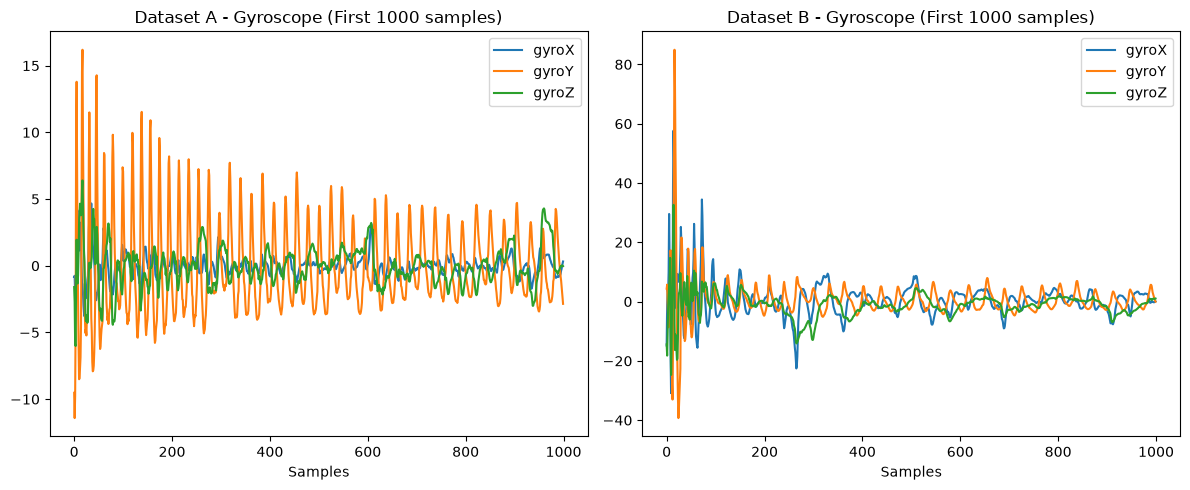

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def verify_column_extraction_and_units(matrices_A, matrices_B):
    """Diagnostic suite to inspect raw data shapes, unit scales, correlations,

    and column alignment between Dataset A and Dataset B.
    """
    print("==================================================")
    print(" 1. COLUMN LAYOUT & RAW DIMENSION INSPECTION")
    print("==================================================")

    dict_A_first_key = list(matrices_A.keys())[0]
    dict_B_keys = list(matrices_B.keys())

    # Find a 10/11 col file and a 21 col file from Dataset B
    sample_B_10 = next(
        (
            k
            for k in dict_B_keys
            if matrices_B[k].shape[1] in (10, 11) or matrices_B[k].shape[1] == 7
        ),
        dict_B_keys[0],
    )
    sample_B_21 = next(
        (k for k in dict_B_keys if matrices_B[k].shape[1] == 21), dict_B_keys[0]
    )

    mat_A = matrices_A[dict_A_first_key]
    mat_B_10 = matrices_B[sample_B_10]
    mat_B_21 = matrices_B[sample_B_21]

    print(
        f"Dataset A sample ('{dict_A_first_key}'): Shape = {mat_A.shape}, Type = {type(mat_A)}"
    )
    print(
        f"Dataset B sample 1 ('{sample_B_10}'): Shape = {mat_B_10.shape}, Type = {type(mat_B_10)}"
    )
    print(
        f"Dataset B sample 2 ('{sample_B_21}'): Shape = {mat_B_21.shape}, Type = {type(mat_B_21)}"
    )

    print("\n==================================================")
    print(" 2. PRESSURE_DIFF INDEX ALIGNMENT CHECK")
    print("==================================================")

    def inspect_last_cols(name, mat):
        if isinstance(mat, pd.DataFrame):
            mat = mat.to_numpy()
        n_cols = mat.shape[1]
        print(f"\nFile: {name} (Total columns: {n_cols})")
        print("  Col 0..5 (Motion) Sample Row 0:", mat[0, :6])
        if n_cols > 6:
            print("  Col 6..8 Sample Row 0:", mat[0, 6:9])
            print("  Col 9 Sample Row 0:", mat[0, 9] if n_cols > 9 else "N/A")
            print("  Last Column (mat[:, -1]) Sample Row 0:", mat[0, -1])

    inspect_last_cols(dict_A_first_key, mat_A)
    inspect_last_cols(sample_B_10, mat_B_10)
    inspect_last_cols(sample_B_21, mat_B_21)

    print("\n==================================================")
    print(" 3. RAW MAGNITUDE & UNIT SCALE COMPARISON")
    print("==================================================")

    # Compute unnormalized statistics across all raw arrays
    raw_A = np.vstack(
        [
            m.to_numpy() if isinstance(m, pd.DataFrame) else m
            for m in matrices_A.values()
        ]
    )
    raw_B = np.vstack(
        [
            m.to_numpy() if isinstance(m, pd.DataFrame) else m
            for m in matrices_B.values()
        ]
    )

    # Extract 6 motion channels from raw arrays
    motion_A = raw_A[:, :6]
    motion_B = raw_B[:, :6]

    channels = ["accX", "accY", "accZ", "gyroX", "gyroY", "gyroZ"]
    df_scale = pd.DataFrame(
        {
            "Channel": channels,
            "A_Raw_Mean": motion_A.mean(axis=0),
            "A_Raw_Std": motion_A.std(axis=0),
            "B_Raw_Mean": motion_B.mean(axis=0),
            "B_Raw_Std": motion_B.std(axis=0),
            "Std_Ratio (B/A)": motion_B.std(axis=0)
            / (motion_A.std(axis=0) + 1e-8),
        }
    )
    print(df_scale.to_string(index=False))

    print("\n==================================================")
    print(" 4. CHANNEL CORRELATION STRUCTURE (Cross-Axis Leak Test)")
    print("==================================================")
    corr_A = pd.DataFrame(np.corrcoef(motion_A.T), index=channels, columns=channels)
    corr_B = pd.DataFrame(np.corrcoef(motion_B.T), index=channels, columns=channels)

    print("Correlation Matrix - Dataset A (Motion Channels):")
    print(corr_A.round(2))
    print("\nCorrelation Matrix - Dataset B (Motion Channels):")
    print(corr_B.round(2))

    # Visual Plot
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].plot(motion_A[:1000, 3:6])
    axes[0].set_title("Dataset A - Gyroscope (First 1000 samples)")
    axes[0].set_xlabel("Samples")
    axes[0].legend(["gyroX", "gyroY", "gyroZ"])

    axes[1].plot(motion_B[:1000, 3:6])
    axes[1].set_title("Dataset B - Gyroscope (First 1000 samples)")
    axes[1].set_xlabel("Samples")
    axes[1].legend(["gyroX", "gyroY", "gyroZ"])
    plt.tight_layout()
    plt.show()


# Run the diagnostic test
verify_column_extraction_and_units(matrices_UNLAB, matrices_UNLAB_B)

 FEATURE SUBSET LEAKAGE TEST
Extracting feature subsets...
                    Feature Subset  Domain Separation AUC
          Time Domain (Std & Diff)               0.993113
Extreme Spikes (Quantiles/Min/Max)               0.730196
          Frequency Spectrum (FFT)               0.875470


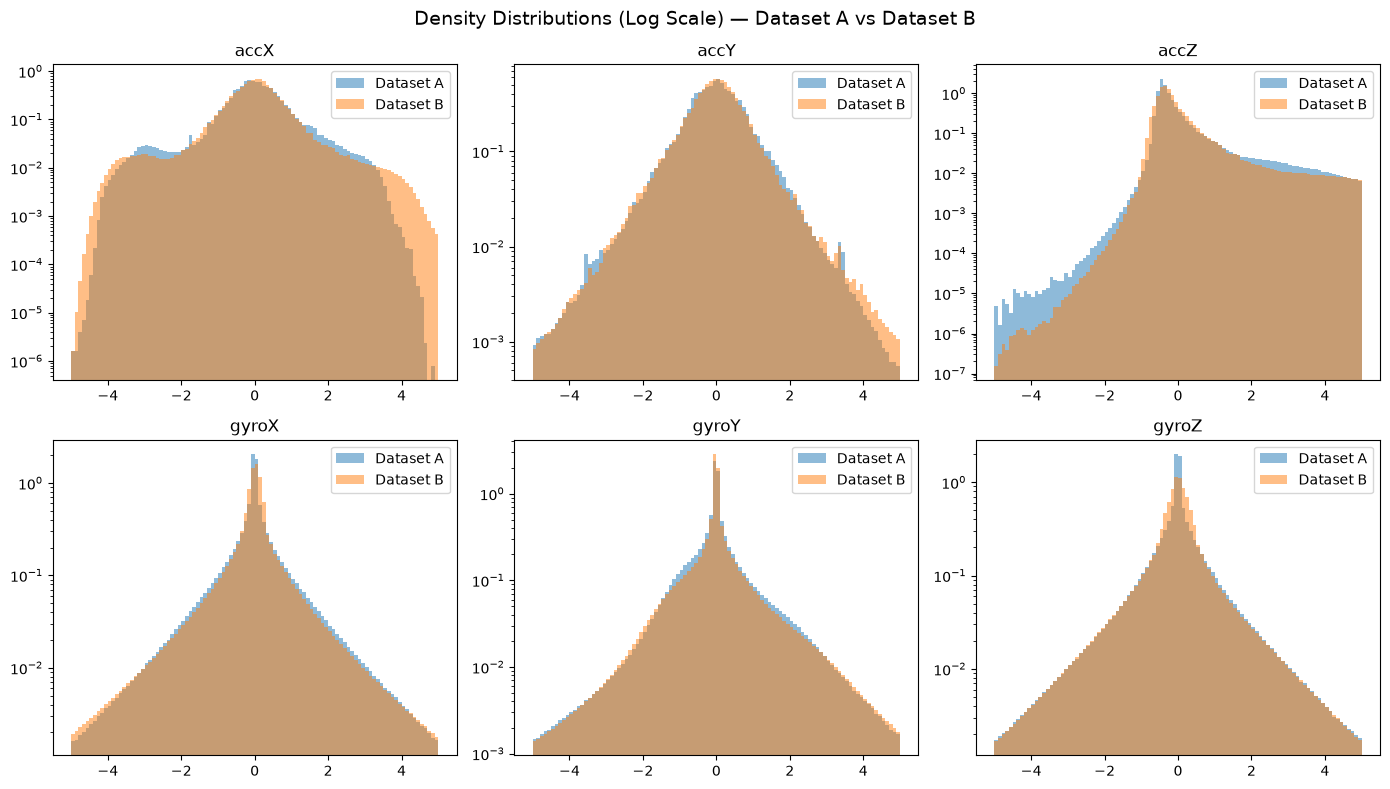

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict

# ----------------------------------------------------------------------------
# 1. Feature Leakage Isolation Test
# ----------------------------------------------------------------------------


def test_feature_leakage(matrices_A, matrices_B, win=800, stride=800, seed=42):
    """Evaluates individual feature sets to determine WHICH exact feature

    (Time vs. Frequency vs. Quantiles) allows the classifier to separate A from B.
    """

    def extract_isolated_features(matrices_dict):
        time_feats, freq_feats, quant_feats, groups = [], [], [], []
        for name, mat in matrices_dict.items():
            z = mat[:, :6]  # First 6 motion channels
            for i in range(0, len(z) - win + 1, stride):
                w = z[i : i + win]

                # 1. Standard time domain (Std & Mean Diff)
                t_f = np.concatenate(
                    [w.std(axis=0), np.abs(np.diff(w, axis=0)).mean(axis=0)]
                )

                # 2. Quantiles (Min, Max, 1st %, 99th %) - tests outlier spikes
                q_f = np.concatenate(
                    [
                        np.percentile(w, 1, axis=0),
                        np.percentile(w, 99, axis=0),
                        w.min(axis=0),
                        w.max(axis=0),
                    ]
                )

                # 3. Frequency domain (FFT magnitude spectrum)
                fft_vals = np.abs(np.fft.rfft(w, axis=0))[1:64, :]  # Low freqs
                f_f = fft_vals.ravel()

                time_feats.append(t_f)
                quant_feats.append(q_f)
                freq_feats.append(f_f)
                groups.append(name)

        return (
            np.array(time_feats),
            np.array(quant_feats),
            np.array(freq_feats),
            np.array(groups),
        )

    print("Extracting feature subsets...")
    t_A, q_A, f_A, g_A = extract_isolated_features(matrices_A)
    t_B, q_B, f_B, g_B = extract_isolated_features(matrices_B)

    rng = np.random.default_rng(seed)
    n = min(len(t_A), len(t_B))
    idx_A, idx_B = rng.choice(len(t_A), n, replace=False), rng.choice(
        len(t_B), n, replace=False
    )

    y = np.r_[np.zeros(n), np.ones(n)]
    groups = np.r_[g_A[idx_A], g_B[idx_B]]

    feature_sets = {
        "Time Domain (Std & Diff)": np.vstack([t_A[idx_A], t_B[idx_B]]),
        "Extreme Spikes (Quantiles/Min/Max)": np.vstack
        ([q_A[idx_A], q_B[idx_B]]),
        "Frequency Spectrum (FFT)": np.vstack([f_A[idx_A], f_B[idx_B]]),
    }

    results = []
    clf = RandomForestClassifier(n_estimators=50, max_depth=5, random_state=seed)
    cv = GroupKFold(n_splits=min(5, len(np.unique(groups))))

    for name, X in feature_sets.items():
        probs = cross_val_predict(
            clf, X, y, groups=groups, cv=cv, method="predict_proba"
        )[:, 1]
        auc = roc_auc_score(y, probs)
        results.append({"Feature Subset": name, "Domain Separation AUC": auc})

    return pd.DataFrame(results)


# ----------------------------------------------------------------------------
# 2. Histogram Overlay Diagnostic
# ----------------------------------------------------------------------------


def plot_distribution_comparison(matrices_A, matrices_B):
    """Plots direct PDF distribution overlays across shared motion channels."""
    data_A = np.vstack(list(matrices_A.values()))[:, :6]
    data_B = np.vstack(list(matrices_B.values()))[:, :6]

    channels = ["accX", "accY", "accZ", "gyroX", "gyroY", "gyroZ"]

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes = axes.ravel()

    for idx, col in enumerate(channels):
        axes[idx].hist(
            data_A[:, idx],
            bins=100,
            density=True,
            alpha=0.5,
            label="Dataset A",
            range=(-5, 5),
        )
        axes[idx].hist(
            data_B[:, idx],
            bins=100,
            density=True,
            alpha=0.5,
            label="Dataset B",
            range=(-5, 5),
        )
        axes[idx].set_title(col)
        axes[idx].set_yscale("log")  # Log scale highlights tail differences
        axes[idx].legend()

    plt.suptitle(
        "Density Distributions (Log Scale) — Dataset A vs Dataset B",
        fontsize=14,
    )
    plt.tight_layout()
    plt.show()


# Run feature breakdown
print("==================================================")
print(" FEATURE SUBSET LEAKAGE TEST")
print("==================================================")
df_auc_breakdown = test_feature_leakage(matrices_UNLAB, matrices_UNLAB_B)
print(df_auc_breakdown.to_string(index=False))

# Plot direct distributions
plot_distribution_comparison(matrices_UNLAB, matrices_UNLAB_B)

In [ ]:
import numpy as np
import pandas as pd
from scipy.signal import welch
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict

# ----------------------------------------------------------------------------
# 1. Helper Functions: Harmonised Channel Selection & Feature Extraction
# ----------------------------------------------------------------------------


def get_harmonised_channels(mat):
    """Selects the shared 7 channels across datasets regardless of total columns.

    Inputs:
      mat: (N, C) numpy array or pandas DataFrame.
    Outputs:
      (N, 7) array containing [accX, accY, accZ, gyroX, gyroY, gyroZ, Pressure_diff]
    """
    if isinstance(mat, pd.DataFrame):
        mat = mat.to_numpy()

    n_cols = mat.shape[1]

    # Motion channels are always columns 0 to 5
    motion = mat[:, :6]

    # Pressure_diff is column 9 in 10-col Dataset A, column 9 in 10-col raw A,
    # or the last column in preprocessed datasets (e.g. index -1 or 9/20)
    if n_cols == 7:
        # Pre-selected 7-channel matrix (6 motion + Pressure_diff as index 6)
        p_diff = mat[:, 6:7]
    elif n_cols == 10:
        p_diff = mat[:, 9:10]
    elif n_cols in (11, 21):
        p_diff = mat[:, -1:]
    else:
        # Fallback to last column if unknown layout
        p_diff = mat[:, -1:]

    return np.hstack([motion, p_diff])


def extract_window_features(
    matrices_dict, win=800, stride=800, fs=20.0, num_motion_channels=6
):
    """Extracts unit-free window features (time-domain std, mean differential, and Welch PSD band powers) from the 6 motion channels."""
    feats_list, groups_list = [], []

    for name, mat in matrices_dict.items():
        harmonised = get_harmonised_channels(mat)
        motion_mat = harmonised[:, :num_motion_channels]

        # Per-file z-score normalization to focus on relative dynamics
        sd = motion_mat.std(axis=0)
        sd[sd < 1e-8] = 1.0
        z = (motion_mat - motion_mat.mean(axis=0)) / sd
        n_samples = len(z)

        for i in range(0, n_samples - win + 1, stride):
            w = z[i : i + win]

            # Welch PSD features across 4 frequency bands
            f, p = welch(w, fs=fs, nperseg=min(256, win), axis=0)
            bands = [(0, 0.5), (0.5, 2), (2, 5), (5, 10)]
            bp = [p[(f >= lo) & (f < hi)].sum(axis=0) for lo, hi in bands]
            bp = np.array(bp) / (np.array(bp).sum(axis=0) + 1e-12)

            std_feat = w.std(axis=0)
            diff_feat = np.abs(np.diff(w, axis=0)).mean(axis=0)

            feats_list.append(
                np.concatenate([std_feat, diff_feat, bp.ravel()])
            )
            groups_list.append(name)

    return np.array(feats_list), np.array(groups_list)


def run_domain_classifier(
    matrices_A, matrices_B, win=800, stride=800, fs=20.0, seed=42
):
    """Extracts features, subsamples to balance datasets, and computes GroupKFold ROC-AUC.

    AUC ~ 0.5: High compatibility (indistinguishable) AUC ~ 1.0: Severe domain
    gap
    """
    print("Extracting features from Dataset A...")
    feats_A, groups_A = extract_window_features(
        matrices_A, win=win, stride=stride, fs=fs
    )
    print("Extracting features from Dataset B...")
    feats_B, groups_B = extract_window_features(
        matrices_B, win=win, stride=stride, fs=fs
    )

    rng = np.random.default_rng(seed)
    n = min(len(feats_A), len(feats_B))

    idx_A = rng.choice(len(feats_A), n, replace=False)
    idx_B = rng.choice(len(feats_B), n, replace=False)

    X = np.vstack([feats_A[idx_A], feats_B[idx_B]])
    y = np.r_[np.zeros(n), np.ones(n)]
    groups = np.r_[groups_A[idx_A], groups_B[idx_B]]

    k_folds = min(5, len(np.unique(groups)))
    print(f"Running {k_folds}-fold GroupKFold Domain Classifier...")

    clf = GradientBoostingClassifier(random_state=seed)
    probs = cross_val_predict(
        clf,
        X,
        y,
        groups=groups,
        cv=GroupKFold(n_splits=k_folds),
        method="predict_proba",
    )[:, 1]

    return roc_auc_score(y, probs)


def compute_channel_stats(matrices_dict, col_names):
    """Computes mean, standard deviation, and range for harmonised channels across all files."""
    all_mats = [get_harmonised_channels(m) for m in matrices_dict.values()]
    data = np.vstack(all_mats)

    stats = []
    for idx, name in enumerate(col_names):
        col = data[:, idx]
        stats.append(
            {
                "Channel": name,
                "Mean": np.mean(col),
                "Std": np.std(col),
                "Min": np.min(col),
                "Max": np.max(col),
            }
        )
    return pd.DataFrame(stats)


# ----------------------------------------------------------------------------
# 2. Execution & Comparability Diagnostics
# ----------------------------------------------------------------------------

CHANNELS_7 = [
    "accX",
    "accY",
    "accZ",
    "gyroX",
    "gyroY",
    "gyroZ",
    "Pressure_diff",
]

# 1. Run Domain Classifier Test
domain_auc = run_domain_classifier(
    matrices_UNLAB, matrices_UNLAB_B, win=800, stride=800, fs=20.0
)

print("\n==============================================")
print(f" DOMAIN CLASSIFIER ROC-AUC: {domain_auc:.4f}")
print("==============================================")
if domain_auc < 0.65:
    print("VERDICT: High compatibility! The datasets are largely indistinguishable.")
elif domain_auc < 0.85:
    print("VERDICT: Moderate domain shift detected. Consider feature normalization or fine-tuning.")
else:
    print("VERDICT: High domain shift (AUC near 1.0). The model easily distinguishes Logger A from Logger B.")

# 2. Print Summary Statistics
print("\n--- Dataset A Harmonised Channel Summary ---")
print(compute_channel_stats(matrices_UNLAB, CHANNELS_7).to_string(index=False))

print("\n--- Dataset B Harmonised Channel Summary ---")
print(
    compute_channel_stats(matrices_UNLAB_B, CHANNELS_7).to_string(index=False)
)

Extracting features from Dataset A...
Extracting features from Dataset B...
Running 5-fold GroupKFold Domain Classifier...

 DOMAIN CLASSIFIER ROC-AUC: 0.9981
VERDICT: High domain shift (AUC near 1.0). The model easily distinguishes Logger A from Logger B.

--- Dataset A Harmonised Channel Summary ---
      Channel          Mean  Std        Min       Max
         accX -6.953227e-18  1.0  -7.180171 11.110768
         accY  0.000000e+00  1.0 -11.585580 27.417207
         accZ -2.955121e-17  1.0 -16.665365 21.583826
        gyroX  3.440399e-19  1.0 -53.956023 57.916094
        gyroY  5.939215e-18  1.0 -47.413282 53.414114
        gyroZ  2.897178e-19  1.0 -57.045436 46.162867
Pressure_diff -2.788534e-18  1.0 -18.597350 21.970808

--- Dataset B Harmonised Channel Summary ---
      Channel          Mean  Std         Min        Max
         accX  4.054130e-18  1.0  -40.625779  80.106987
         accY  5.315415e-17  1.0  -15.867375  18.535568
         accZ  4.144222e-16  1.0  -27.673134  30.36

# Data Generator

In [ ]:
def density_for_one_promotion(turtle_name, CLASS):

    label=labels[turtle_name]

    N = len(label)
    dens = np.zeros_like(label, dtype=np.float64)

    dens[label==CLASS.id] = 1

    sum_dens=np.sum(dens)
    if  sum_dens<1e-6:
        print("the class to promote:"+CLASS.name +" is not present in:"+turtle_name)
        dens[:]=1
        sum_dens=len(dens)


    dens/=sum_dens

    # creating a mask.
    kernel = np.ones(int(1.5*WINDOW_SIZE))#avant cela dépendait de N
    kernel/=np.sum(kernel)
    #gauss = np.exp(-t**2)
    #gauss /= np.sum(gauss)

    # convolving label with a mask
    dens_conv = np.convolve(dens, kernel, mode='same')#+min_dens

    dens_conv[-WINDOW_SIZE//2-2:]=0
    dens_conv[:WINDOW_SIZE//2+2]=0

    cdf=np.cumsum(dens_conv)
    cdf/=cdf[-1]

    def rand_gene():
        while True:
                yield np.argmax(cdf>np.random.random())-WINDOW_SIZE//2

    return dens,dens_conv,cdf,rand_gene()

In [ ]:
class InterestingTurtles:

    def __init__(self,turtle_names,CLASS):
        self.turtle_names=turtle_names
        self.occurences=np.zeros(len(turtle_names))
        self.CLASS=CLASS

        for i,name in enumerate(turtle_names):
            self.occurences[i]+=np.sum(labels[name]==CLASS.id)

        total=np.sum(self.occurences)
        self.has_data = total > 0
        if self.has_data:
            self.proba=self.occurences/total
        else:
            self.proba=np.full(len(turtle_names),1.0/len(turtle_names))

    def give_me_one_turtle(self):
        return np.random.choice(a=self.turtle_names,p=self.proba)


### Global generator

* A class is drawn according to CLASS.sampling_weight
* Draw a turtle according to interest_by_class
* Draw a time window according to the index generator linked to the turtle

In [ ]:
class Global_generator:

    def __init__(self,turtle_names):

        self.turtle_names=turtle_names

        self.interesting_turtles_by_class={}

        self.proba_of_classes=np.zeros(len(CLASSES))

        for CLASS in CLASSES:
            it=InterestingTurtles(turtle_names,CLASS)
            self.interesting_turtles_by_class[CLASS.name]=it
            self.proba_of_classes[CLASS.id]=CLASS.sampling_weight if it.has_data else 0.0

        if self.proba_of_classes.sum()==0:
            raise ValueError("None of the classes has any labelled time steps in: "+str(turtle_names))
        self.proba_of_classes/=np.sum(self.proba_of_classes)


        print([ (CLASS.name,self.proba_of_classes[CLASS.id]) for CLASS in CLASSES])


        self.class_2_index_gene={}

        for CLASS in CLASSES:

            random_index_generators={}
            for name in turtle_names:
                _,_,_,gene=density_for_one_promotion(name,CLASS)
                random_index_generators[name]=gene

            self.class_2_index_gene[CLASS.name]=random_index_generators


    def give_me_turtle_and_timeIndex(self):

        if np.random.rand()<0.1:
            theTurtle=np.random.choice(self.turtle_names)
            deb=0
            fin=len(labels[theTurtle])-WINDOW_SIZE
            t=np.random.randint(deb,fin)
            return theTurtle,t

        theClass=np.random.choice(CLASSES,p=self.proba_of_classes)
        theTurtle=self.interesting_turtles_by_class[theClass.name].give_me_one_turtle()


        theGenerators=self.class_2_index_gene[theClass.name]
        theGenerator=theGenerators[theTurtle]
        return theTurtle,next(theGenerator)
    

In [ ]:
def oneEpoch_generator_window(turtle_names, size=100):


    generator=Global_generator(turtle_names)

    while True:

        X = np.empty([size,WINDOW_SIZE,len(DESCRIPTORS_SELEC)])
        Y = np.empty([size,WINDOW_SIZE],dtype=int)

        for i in range(size):
            turtle_name,t=generator.give_me_turtle_and_timeIndex()
            matrix=matrices[turtle_name]
            label=labels[turtle_name]
            X[i,:,:]=matrix[t:t+WINDOW_SIZE ,:]
            Y[i,:]=label[t:t+WINDOW_SIZE]

        yield X, Y


In [ ]:
memo["nb_train_per_epoch"] = NB_TRAIN_PER_EPOCH
memo["nb_val_fixed"] = NB_VAL_FIXED

# Vnet with pytorch

In [ ]:
class SpatialDropout1D(nn.Module):
    def __init__(self, p: float = 0.5):
        """
        Spatial Dropout for 1D inputs (batch_size, channels, sequence_length).
        It drops entire channels (features) across all timesteps.

        Args:
            p (float): dropout probability (default=0.5)
        """
        super(SpatialDropout1D, self).__init__()
        self.dropout = nn.Dropout2d(p)

    def forward(self, x):
        # x shape: (batch_size, channels, sequence_length)
        x = x.unsqueeze(3)  # Add fake height dimension (N, C, L, 1)
        x = self.dropout(x)  # Apply Dropout2d
        return x.squeeze(3)

class VNet4Levels(nn.Module):
    def __init__(self, in_channels, out_channels, model_depth, dropout_rate=0.5, kernel_size=5):
        super(VNet4Levels, self).__init__()

        self.in_channels = in_channels
        self.out_channels=out_channels
        self.depth = model_depth
        self.dropout_rate = dropout_rate
        self.kernel_size = kernel_size

        self.dropout = SpatialDropout1D(p=dropout_rate)

        # Define layers
        self.conv1 = self.double_conv(self.in_channels, self.depth)
        self.down1 = nn.Conv1d(self.depth, self.depth * 2, kernel_size=2, stride=2, padding=0)
        self.conv2 = self.double_conv(self.depth * 2, self.depth * 2)
        
        self.down2 = nn.Conv1d(self.depth * 2, self.depth * 4, kernel_size=2, stride=2, padding=0)
        self.conv3 = self.double_conv(self.depth * 4, self.depth * 4)
        
        self.down3 = nn.Conv1d(self.depth * 4, self.depth * 8, kernel_size=2, stride=2, padding=0)
        self.conv4 = self.double_conv(self.depth * 8, self.depth * 8)
        
        self.up1 = self.make_up(self.depth * 8, self.depth * 4)
        self.conv5 = self.double_conv(self.depth * 4, self.depth * 4)
        
        self.up2 = self.make_up(self.depth * 4, self.depth * 2)
        self.conv6 = self.double_conv(self.depth * 2, self.depth * 2)
        
        self.up3 = self.make_up(self.depth * 2, self.depth)
        self.conv7 = self.double_conv(self.depth, self.depth)

        #last layer 
        self.classifier = nn.Conv1d(self.depth, self.out_channels, kernel_size=1)

    def double_conv(self, in_channels, depth):
        return nn.Sequential(
            nn.Conv1d(in_channels, depth, self.kernel_size, padding=2),
            nn.BatchNorm1d(depth),
            nn.ReLU(inplace=True),
            nn.Conv1d(depth, depth, self.kernel_size, padding=2, bias=False),
            nn.BatchNorm1d(depth ),
            nn.ReLU(inplace=True),
            #nn.Dropout(self.dropout_rate)
        )
    
    def make_up(self, in_channels, depth):
        return nn.Sequential(
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv1d(in_channels, depth, kernel_size=3, padding=1),
            nn.BatchNorm1d(depth),
            nn.ReLU(inplace=True)
        )

    
    def forward(self, x):
        conv1 = self.conv1(x)
        conv1_d=self.dropout(conv1)
        down1 = self.down1(conv1_d)
        down1= F.relu(down1)
        conv2 = self.conv2(down1)
        conv2_d=self.dropout(conv2)
        
        y = torch.add(down1 , conv2_d)
        down2 = self.down2(y)
        down2=F.relu(down2)
        conv3 = self.conv3(down2)
        conv3_d=self.dropout(conv3)
        

        y = torch.add(down2 , conv3_d)
        down3 = self.down3(y)
        down3=F.relu(down3)
        conv4 = self.conv4(down3)
        conv4_d=self.dropout(conv4)
        
        #PATCH_DIM/4
        up1 = self.up1(conv4_d)
        y = torch.add(conv3_d , up1)
        pre_conv5=self.conv5(y)
        pre_conv5_d=self.dropout(pre_conv5)
        conv5 = torch.add(pre_conv5_d , up1)
        
        #PATCH_DIM/2
        up2 = self.up2(conv5)
        y = torch.add(conv2 , up2)
        pre_conv6=self.conv6(y)
        pre_conv6_d=self.dropout(pre_conv6)
        conv6 = torch.add(pre_conv6_d , up2)
        
        #PATCH_DIM
        up3 = self.up3(conv6)
        y = torch.add(conv1 , up3)
        pre_conv7=self.conv7(y)
        pre_conv7_d=self.dropout(pre_conv7)
        conv7 = torch.add(pre_conv7_d , up3)
       

        output=self.classifier(conv7)
        softmax=F.softmax(output, dim=1)
        
        return softmax


In [ ]:
in_channels=7
out_channels=7
model_depth=32
window_size=800

model = VNet4Levels(in_channels, out_channels, model_depth, dropout_rate=0.5)

print(model)

In [ ]:
#from torchsummary import summary

if hasattr(torch, "xpu") and torch.xpu.is_available():
    device = torch.device("xpu")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

model = VNet4Levels(in_channels, out_channels, model_depth, dropout_rate=0.5).to(device)
#summary(model, input_size=(7, 800), device=str(device))

In [ ]:
ponde = torch.tensor(np.array([CLASS.loss_weight for CLASS in CLASSES], dtype=np.float32))
ponde /= torch.sum(ponde)


In [ ]:
ponde

In [ ]:
DICE_LOSS_WEIGHT = 0.5
CE_LOSS_WEIGHT = 0.5

def dice_coef(pred_proba, target_onehot, smooth=1e-8):
    intersection = torch.sum(target_onehot * pred_proba, dim=2)
    return (2. * intersection + smooth) / (
        torch.sum(target_onehot, dim=2) + torch.sum(pred_proba, dim=2) + smooth
    )

def dice_loss(pred_proba, target_onehot, weight):
    weight = weight.view(1, -1).to(pred_proba.device)
    weighted_dice = dice_coef(pred_proba, target_onehot) * weight
    return 1 - weighted_dice.sum(dim=1).mean()

def weighted_ce_loss(pred_proba, target_onehot, weight, eps=1e-8):
    weight = weight.view(1, -1, 1).to(pred_proba.device)
    log_probs = torch.log(pred_proba.clamp(min=eps))
    per_timestep = -(target_onehot * log_probs * weight).sum(dim=1)
    return per_timestep.mean()

def dice_ce_loss(pred_proba, target_onehot, weight):
    return (
        DICE_LOSS_WEIGHT * dice_loss(pred_proba, target_onehot, weight)
        + CE_LOSS_WEIGHT * weighted_ce_loss(pred_proba, target_onehot, weight)
    )


In [ ]:
import time

class Trainer:
    def __init__(self, model, optimizer, criterion, batch_size, loss_weight, device, save_dir):
        self.model = model
        self.optimizer = optimizer
        self.criterion = criterion
        self.batch_size = batch_size
        self.loss_weight = loss_weight
        self.device = device
        self.save_dir = Path(save_dir)
        self.save_dir.mkdir(parents=True, exist_ok=True)
        self.best_loss = float('inf')
        self.total_duration = 0
        self.durations = []

    def load_best_model(self):
        save_path = os.path.join(self.save_dir, "model.pth")
        self.model.load_state_dict(torch.load(save_path, weights_only=True, map_location=self.device))
        self.model.to(self.device)

    def train2(self, train_gene, X_val_fixed, Y_val_fixed, epochs, patience=10):
        """Train with a FIXED validation set.

        The same validation windows are scored every epoch, so the validation loss
        is comparable across epochs and the early-stopping / best-checkpoint choice
        is not driven by which windows happened to be drawn (the old `train`
        resampled validation windows every epoch). Restores the best checkpoint
        on return."""
        counter = 0
        self.best_loss = float("inf")
        self.train_losses = []
        self.val_losses = []
        self.train_accuracies, self.val_accuracies = [], []
        self.best_epochs = []

        # build the val loader ONCE, outside the loop
        Y_val_oh = F.one_hot(torch.tensor(Y_val_fixed, dtype=torch.long), num_classes=7)
        val_loader = self._create_pytorch_dataloader(X_val_fixed, Y_val_oh, shuffle=False)

        for epoch in range(epochs):
            starting_time = time.time()

            X_ep, Y_ep = next(train_gene)
            Y_ep = F.one_hot(torch.tensor(Y_ep, dtype=torch.long), num_classes=7)
            train_loader = self._create_pytorch_dataloader(X_ep, Y_ep, shuffle=False)

            self.model.train(True)
            total_loss, total_acc = 0, 0
            num_batches = len(train_loader)

            for x_batch, y_batch in train_loader:
                x_batch, y_batch = x_batch.to(self.device), y_batch.to(self.device)
                self.optimizer.zero_grad()
                y_pred = self.model(x_batch)
                loss = self.criterion(y_pred, y_batch, self.loss_weight)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()
                total_acc += self._compute_accuracy(y_pred, y_batch)

            train_epoch_loss = total_loss / num_batches
            self.train_losses.append(train_epoch_loss)
            train_epoch_acc = total_acc / num_batches
            self.train_accuracies.append(train_epoch_acc)

            # evaluation on the SAME fixed val set every epoch
            val_loss, val_acc = self._val_one_epoch(val_loader)
            self.val_losses.append(val_loss)
            self.val_accuracies.append(val_acc)

            print(f"Epoch {epoch+1}, Train Loss: {train_epoch_loss:.4f}, Train Acc: {train_epoch_acc:.4f}, "
                  f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

            if val_loss < self.best_loss:
                print("val_loss improved from {:.5f} to {:.5f}".format(self.best_loss, val_loss))
                self.best_loss = val_loss
                self.best_epochs.append(epoch)
                print("Model is saved on epoch {:d}.".format(epoch))
                save_path = os.path.join(self.save_dir, "model.pth")
                torch.save(self.model.state_dict(), save_path)
                counter = 0
            else:
                counter += 1
                if counter >= patience:
                    print("Early stopping due to no improvement")
                    break

            duration = time.time() - starting_time
            self.durations.append(duration)
            self.total_duration += duration
    
        # restore the best checkpoint
        self.model.load_state_dict(torch.load(os.path.join(self.save_dir, "model.pth"),
                                              weights_only=True, map_location=self.device))

    def _create_pytorch_dataloader(self, X, Y, shuffle):

        X_tensor = torch.from_numpy(X).float()
        X_tensor=X_tensor.permute(0, 2, 1)
        Y_tensor=Y.permute(0, 2, 1)
        dataset = torch.utils.data.TensorDataset(X_tensor, Y_tensor)
        loader = torch.utils.data.DataLoader(
            dataset, batch_size=self.batch_size, shuffle=shuffle
        )
        return loader
    
    def _compute_accuracy(self,y_pred, y_true):

        y_pred_labels = y_pred.argmax(dim=1)  # Shape: (batch_size, seq_length)
        y_true_labels = y_true.argmax(dim=1)  # Convert one-hot to class index (batch_size, seq_length)

        correct = (y_pred_labels == y_true_labels).float()
        return correct.mean().item()  # Return scalar accuracy


    def _val_one_epoch(self, val_loader):
        self.model.train(False)

        num_batches = len( val_loader)
        num_samples = len( val_loader.dataset)
        
        with torch.no_grad():
            total_loss, total_acc = 0.0, 0.0

            for x_batch, y_batch in val_loader:
                x_batch, y_batch = x_batch.to(self.device), y_batch.to(self.device)
                #forward pass
                y_pred = self.model(x_batch)
                #compute loss
                loss = self.criterion(y_pred, y_batch, self.loss_weight)
                #compute loss
                total_loss += loss.item()
                total_acc += self._compute_accuracy(y_pred, y_batch)

        return total_loss / num_batches, total_acc / num_batches

In [ ]:
from sklearn.metrics import f1_score
import numpy as np
import torch

def evaluate_names(model, device, names, batch_size=64):
    """
    Evaluate a model on all complete non-overlapping windows from the given recordings.
    Model output shape is (batch, n_classes, WINDOW_SIZE), so argmax is over dim=1.
    """
    model.eval()

    y_true_all = []
    y_pred_all = []

    with torch.no_grad():
        for name in names:
            X = matrices[name]
            y = labels[name]

            n_windows = len(X) // WINDOW_SIZE
            if n_windows == 0:
                print(f"Skipping {name}: recording too short.")
                continue

            # Stack all complete windows: (n_windows, WINDOW_SIZE, n_features)
            X_win = X[:n_windows * WINDOW_SIZE].reshape(n_windows, WINDOW_SIZE, -1)
            y_win = y[:n_windows * WINDOW_SIZE].reshape(n_windows, WINDOW_SIZE)

            for start in range(0, n_windows, batch_size):
                xb = torch.from_numpy(X_win[start:start + batch_size]).float()
                xb = xb.permute(0, 2, 1).to(device)        # (B, C_in, L)

                outputs = model(xb)                         # (B, n_classes, L)
                preds = outputs.argmax(dim=1)               # (B, L)  <-- class axis

                y_pred_all.append(preds.cpu().numpy().reshape(-1))
                y_true_all.append(y_win[start:start + batch_size].reshape(-1))

    if len(y_true_all) == 0:
        raise ValueError("No valid windows found for evaluation.")

    y_true_all = np.concatenate(y_true_all).astype(int)
    y_pred_all = np.concatenate(y_pred_all).astype(int)

    class_ids = list(range(len(CLASSES)))

    macro_f1 = f1_score(y_true_all, y_pred_all, labels=class_ids,
                        average="macro", zero_division=0)
    class_scores = f1_score(y_true_all, y_pred_all, labels=class_ids,
                            average=None, zero_division=0)

    return macro_f1, {"F1_score": class_scores}

# Temperature

In [ ]:

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp
 
# ---------------------------- config ---------------------------------
USE_CALIBRATION = True
 
# Precision the pseudo-labels should reach on VAL animals, per class.
TARGET_PRECISION = {"Feeding": 0.90, "Scratching": 0.90, "Gliding": 0.90,
                    "default": 0.95}
 
THR_MIN_PRED = 500      # VAL timesteps predicted as class c needed to trust VAL estimates
THR_MIN_CORRECT = 300   # correct VAL timesteps required at the chosen threshold
THR_FALLBACK = 0.99     # used when VAL has too little evidence for a class
THR_DISABLED = 1.01     # class cannot reach target precision -> never pseudo-labelled
THR_FLOOR = 0.60        # never go below this confidence
T_BOUNDS = (0.5, 20.0)  # allowed temperature range
MAX_FIT_TIMESTEPS = 300_000   # subsample for fitting T (speed)
MAX_THR_TIMESTEPS = 2_000_000 # subsample cap for threshold selection (memory)
 
memo["USE_CALIBRATION"] = USE_CALIBRATION
memo["TARGET_PRECISION"] = TARGET_PRECISION
memo["THR_MIN_PRED"] = THR_MIN_PRED
memo["THR_MIN_CORRECT"] = THR_MIN_CORRECT
memo["THR_FALLBACK"] = THR_FALLBACK
 
 
# ------------------------ temperature wrapper ------------------------
class TemperatureScaledModel(nn.Module):
    """Drop-in replacement for the model inside `threshold_pseudo_core`.
 
    The V-Net ends in a softmax, and log(softmax) = logits - const, so
    softmax(log(p) / T) is exactly temperature scaling of the logits."""
 
    def __init__(self, model, T):
        super().__init__()
        self.model = model
        self.T = float(T)
 
    def forward(self, x):
        p = self.model(x).clamp_min(1e-8)          # (B, C, L)
        return F.softmax(torch.log(p) / self.T, dim=1)
 
 
# ----------------------------- helpers -------------------------------
@torch.no_grad()
def _collect_probs(model, X, Y, batch_size=64, max_timesteps=MAX_THR_TIMESTEPS, seed=0):
    """Softmax outputs for all VAL windows -> (n_timesteps, C), labels (n_timesteps,)."""
    model.eval()
    P = []
    for s in range(0, len(X), batch_size):
        xb = torch.from_numpy(np.ascontiguousarray(X[s:s + batch_size])).float()
        xb = xb.permute(0, 2, 1).to(device)
        pb = model(xb)                                           # (B, C, L)
        P.append(pb.permute(0, 2, 1).reshape(-1, pb.shape[1]).cpu().numpy())
    P = np.concatenate(P).astype(np.float32)
    y = np.asarray(Y).reshape(-1).astype(int)
    if len(P) > max_timesteps:
        keep = np.random.default_rng(seed).choice(len(P), max_timesteps, replace=False)
        P, y = P[keep], y[keep]
    return P, y
 
 
def _nll(logp, y, T):
    z = logp / T
    return float(-(z[np.arange(len(y)), y] - logsumexp(z, axis=1)).mean())
 
 
def fit_temperature(P, y, bounds=T_BOUNDS, max_n=MAX_FIT_TIMESTEPS, seed=0):
    """1-parameter temperature scaling by minimising NLL on VAL timesteps."""
    if len(P) > max_n:
        keep = np.random.default_rng(seed).choice(len(P), max_n, replace=False)
        P, y = P[keep], y[keep]
    logp = np.log(np.clip(P, 1e-8, 1.0)).astype(np.float64)
    res = minimize_scalar(lambda lt: _nll(logp, y, float(np.exp(lt))),
                          bounds=(np.log(bounds[0]), np.log(bounds[1])),
                          method="bounded")
    return float(np.exp(res.x))
 
 
def apply_temperature(P, T):
    z = np.log(np.clip(P, 1e-8, 1.0)) / T
    return np.exp(z - logsumexp(z, axis=1, keepdims=True)).astype(np.float32)
 
 
def expected_calibration_error(P, y, n_bins=15):
    conf, correct = P.max(1), (P.argmax(1) == y)
    idx = np.clip(np.digitize(conf, np.linspace(0, 1, n_bins + 1)) - 1, 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)
 
 
def select_class_thresholds(P, y):
    """Per-class threshold on max-softmax, chosen on VAL.
 
    A timestep is pseudo-labelled as class c when argmax == c and max prob >= thr[c]
    (exactly the rule in `threshold_pseudo_core`). thr[c] is the LOWEST value whose
    VAL precision is >= TARGET_PRECISION for c, with >= THR_MIN_CORRECT correct
    timesteps behind it. Returns (dict class_id -> threshold, dict class_id -> status)."""
    conf, pred = P.max(1), P.argmax(1)
    thr, status = {}, {}
    for c, name in enumerate(CLASS_NAMES):
        target = TARGET_PRECISION.get(name, TARGET_PRECISION["default"])
        sel = pred == c
        if sel.sum() < THR_MIN_PRED:
            thr[c], status[c] = THR_FALLBACK, "fallback (too few VAL predictions)"
            continue
        conf_c = conf[sel]
        ok_c = (y[sel] == c)
        order = np.argsort(-conf_c)
        conf_s, ok_s = conf_c[order], ok_c[order]
        n_correct = np.cumsum(ok_s)
        precision = n_correct / np.arange(1, len(ok_s) + 1)
        good = (precision >= target) & (n_correct >= THR_MIN_CORRECT)
        if not good.any():
            thr[c], status[c] = THR_DISABLED, f"disabled (cannot reach {target:.2f})"
            continue
        k = np.where(good)[0].max()                 # largest cutoff still meeting the target
        thr[c] = float(max(conf_s[k], THR_FLOOR))
        status[c] = f"ok (target {target:.2f})"
    return thr, status
 
 
def calibrate_for_pseudo(model, X_val, Y_val, verbose=True):
    """Returns (calibrated_model, class_thresholds, flat_info_dict)."""
    P0, y = _collect_probs(model, X_val, Y_val)
    T = fit_temperature(P0, y)
    Pc = apply_temperature(P0, T)
    thr, status = select_class_thresholds(Pc, y)
    cal_model = TemperatureScaledModel(model, T)
 
    info = {"temperature": T,
            "ece_before": expected_calibration_error(P0, y),
            "ece_after": expected_calibration_error(Pc, y)}
    for c, name in enumerate(CLASS_NAMES):
        info[f"thr_{name}"] = thr[c]
    if verbose:
        print(f"[calibration] T={T:.3f} | ECE {info['ece_before']:.4f} -> {info['ece_after']:.4f}")
        for c, name in enumerate(CLASS_NAMES):
            print(f"  thr {name:<10s} = {thr[c]:.4f}  [{status[c]}]")
    return cal_model, thr, info
 
 
def threshold_precision_report(model, class_thresholds, X, Y, label):
    """DIAGNOSTIC ONLY. Per-class pseudo-label precision / volume of a threshold rule on
    labelled windows. On VAL this is in-sample (T and thresholds were fitted there);
    on the TEST animal it is the honest check that calibration transfers.
    Never use the test version to select anything."""
    pred, cmask, keep = threshold_pseudo_core(
        model, X, class_thresholds, device, MIN_CONFIDENT_POSITIONS)
    n_true, assigned, correct = quality_counts(Y, pred[keep], cmask[keep], keep)
    print(f"[{label}] pseudo-label precision / n_assigned per class:")
    for c, name in enumerate(CLASS_NAMES):
        p = correct[c] / assigned[c] if assigned[c] > 0 else float("nan")
        print(f"  {name:<10s} precision={p:.3f}  n_assigned={int(assigned[c]):,}")
    return {"n_true": n_true, "assigned": assigned, "correct": correct}
 

# Shared setup for both pseudo-labelling methods

Everything from here to the LOOCV loop is either shared by both methods (target-class evaluation, masked pseudo-loss, trainers, `finetune_arm`, class-balanced window cap) or clearly labelled as belonging to **Method A (probability threshold)** or **Method B (centroid seeding)**.

**Common across both methods:** LOOCV splits, supervised baseline, minimum confident positions per window, class-balanced pseudo-window cap, pseudo-loss weight, pseudo fine-tuning budget, validation-gated bookkeeping, and the control arm.

**Changed between methods:** only how pseudo-label confidence is established. A: softmax probability thresholds per predicted class. B: distance to class-specific embedding centroids (plus a coverage floor on the window).

## Centroid seeding configuration

Centroids are fitted separately for each behaviour class on the **labelled training animals of the current LOOCV fold**. The validation animals are used only for validation-gated model selection and are never used to construct the centroids.

The centroid method retains the source notebook's class-specific distance-percentile, purity-floor, minimum-points, and window-coverage settings.


In [ ]:
# ---------------------------------------------------------------------
# Gate configuration
# ---------------------------------------------------------------------
GATE_METRIC = "target_f1"          # "target_f1" (Feeding/Scratching/Gliding) or "macro_f1"
GATE_MARGIN = 0.0                  # pseudo must beat the SAME-ROUND control by more than this on VAL
GATE_MACRO_TOL = 0.01              # ...and VAL macro-F1 may not fall more than this below control
GATE_MAX_CONSECUTIVE_REJECTS = 2   # close the gate only after this many rejections in a row

memo["GATE_METRIC"] = GATE_METRIC
memo["GATE_MARGIN"] = GATE_MARGIN
memo["GATE_MACRO_TOL"] = GATE_MACRO_TOL
memo["GATE_MAX_CONSECUTIVE_REJECTS"] = GATE_MAX_CONSECUTIVE_REJECTS
# ------------------------------------------------------------------
# Centroid-seeding configuration
# ------------------------------------------------------------------
class_names = CLASS_NAMES  # used by the centroid helper functions

PSEUDO_ITERS = 3
PSEUDO_EPOCHS_PER_ITER = 15
PSEUDO_LOSS_WEIGHT = 0.10   # v4: lowered from 0.25
PSEUDO_LR = 1e-4

# CLEAN1 safeguards shared with the probability-seeding notebook.
MAX_PSEUDO_PER_CLASS = 1000
MIN_CONFIDENT_POSITIONS = 5

# Centroid-specific confidence/seeding parameters.
# Lower distance_percentile = stricter centroid acceptance.
DIST_PERCENTILE_PER_CLASS = {
    "Other": 75,
    "Feeding": 75,
    "Scratching": 75,
    "Breathing": 50,
    "Gliding": 50,
    "Resting": 40,
    "Swimming": 40,
}

PURITY_FLOOR_PER_CLASS = {
    "Other": 0.80,
    "Feeding": 0.90,
    "Scratching": 0.80,
    "Breathing": 0.99,
    "Gliding": 0.90,
    "Resting": 0.99,
    "Swimming": 0.99,
}

MIN_POINTS_PER_CLASS = {
    "Other": 15,
    "Feeding": 15,
    "Scratching": 15,
    "Breathing": 40,
    "Gliding": 15,
    "Resting": 40,
    "Swimming": 40,
}

MIN_COVERAGE_PER_CLASS = {
    "Other": 0.35,
    "Feeding": 0.35,
    "Scratching": 0.35,
    "Breathing": 0.50,
    "Gliding": 0.50,
    "Resting": 0.50,
    "Swimming": 0.50,
    "default": 0.50,
}

NAMES_UNLAB_FOR_PSEUDO = NAMES_ALL_UNLAB

memo["PSEUDO_ITERS"] = PSEUDO_ITERS
memo["PSEUDO_EPOCHS_PER_ITER"] = PSEUDO_EPOCHS_PER_ITER
memo["PSEUDO_LOSS_WEIGHT"] = PSEUDO_LOSS_WEIGHT
memo["PSEUDO_LR"] = PSEUDO_LR
memo["MAX_PSEUDO_PER_CLASS"] = MAX_PSEUDO_PER_CLASS
memo["MIN_CONFIDENT_POSITIONS"] = MIN_CONFIDENT_POSITIONS
memo["PSEUDO_DIST_PERCENTILE_PER_CLASS"] = DIST_PERCENTILE_PER_CLASS
memo["PSEUDO_PURITY_FLOOR_PER_CLASS"] = PURITY_FLOOR_PER_CLASS
memo["PSEUDO_MIN_POINTS_PER_CLASS"] = MIN_POINTS_PER_CLASS
memo["PSEUDO_MIN_COVERAGE_PER_CLASS"] = MIN_COVERAGE_PER_CLASS


# =====================================================================
# v4 CONFIG: softer training, timestep balancing, looser centroid radii
# =====================================================================
# ---- (1) Softer pseudo-label training --------------------------------
# The pseudo term is applied only on a subset of the fine-tuning steps so that, on
# average, each pseudo window is seen at most PSEUDO_MAX_PASSES times per fine-tune
# (v3: every step -> ~20+ passes -> memorisation of noisy labels). None = every step.
PSEUDO_MAX_PASSES = 2.0
PSEUDO_LABEL_SMOOTHING = 0.10     # soft targets: (1-eps)*one-hot + eps*uniform
PSEUDO_CLASS_WEIGHTED = True      # reuse the supervised class weights (`ponde`) in the pseudo CE
# How rounds relate to each other:
#   "chain"           v3 behaviour: round r fine-tunes round r-1's model (drift accumulates)
#   "restart_student" every round fine-tunes a fresh copy of the BASELINE; the labeller is the
#                     previous round's model (iterative labelling, no weight-space drift)
#   "restart_all"     baseline labels AND baseline start every round (rounds = replicates)
# The control chain follows the same mode so pseudo and control stay comparable.
PSEUDO_CHAIN_MODE = "restart_student"
assert PSEUDO_CHAIN_MODE in ("chain", "restart_student", "restart_all")

# ---- (2) Timestep-level class balance --------------------------------
# After the window-level cap, confident TIMESTEPS of each class are randomly thinned to
#   cap = max(PSEUDO_TS_CAP_FLOOR, PSEUDO_TS_CAP_RATIO * (largest target-class count)).
PSEUDO_TS_BALANCE = True
PSEUDO_TS_CAP_RATIO = 1.0
PSEUDO_TS_CAP_FLOOR = 20_000

# ---- (3) Centroid radii ----------------------------------------------
# Used ONLY by the pseudo-labelling pipeline (the latent-space analysis keeps the
# original DIST_PERCENTILE_PER_CLASS / PURITY_FLOOR_PER_CLASS above, unchanged).
# Fallback radius (used when VAL gives no evidence for a cluster): larger percentiles.
CENTROID_DIST_PERCENTILE = {
    "Other": 90, "Feeding": 90, "Scratching": 90,
    "Breathing": 80, "Gliding": 85, "Resting": 80, "Swimming": 80,
}
# TRAIN-purity floors made attainable (v3 had 0.99 for Breathing/Resting/Swimming).
CENTROID_PURITY_FLOOR = {
    "Other": 0.75, "Feeding": 0.85, "Scratching": 0.75,
    "Breathing": 0.90, "Gliding": 0.85, "Resting": 0.90, "Swimming": 0.90,
}
# Main change: re-fit every cluster's radius on the VAL animals' embeddings, as the
# largest radius whose VAL precision still meets the class target. Clusters that cannot
# reach it are disabled; clusters with too little VAL evidence keep the fallback radius.
CENTROID_VAL_RADII = True
CENTROID_TARGET_PRECISION = dict(TARGET_PRECISION)   # same targets as the probability method
CENTROID_RADIUS_MAX_INFLATE = 3.0   # VAL radius is capped at this x the TRAIN radius
CENTROID_VAL_MIN_POINTS = 30        # VAL sub-windows nearest to a cluster needed to trust VAL
CENTROID_VAL_MIN_CORRECT = 15       # correct VAL sub-windows required at the chosen radius

for _k in ("PSEUDO_MAX_PASSES", "PSEUDO_LABEL_SMOOTHING", "PSEUDO_CLASS_WEIGHTED",
           "PSEUDO_CHAIN_MODE", "PSEUDO_TS_BALANCE", "PSEUDO_TS_CAP_RATIO",
           "PSEUDO_TS_CAP_FLOOR", "CENTROID_DIST_PERCENTILE", "CENTROID_PURITY_FLOOR",
           "CENTROID_VAL_RADII", "CENTROID_TARGET_PRECISION",
           "CENTROID_RADIUS_MAX_INFLATE", "CENTROID_VAL_MIN_POINTS",
           "CENTROID_VAL_MIN_CORRECT"):
    memo[_k] = globals()[_k]


In [ ]:
# ------------------------------------------------------------------
# Method A: probability-threshold configuration
# ------------------------------------------------------------------
CLASS_CONF_THRESHOLD = {}
for CLASS in CLASSES:
    if CLASS.name in ("Gliding", "Feeding"):
        CLASS_CONF_THRESHOLD[CLASS.id] = 0.90
    elif CLASS.name in ("Swimming", "Resting", "Breathing"):
        CLASS_CONF_THRESHOLD[CLASS.id] = 0.99
    else:
        CLASS_CONF_THRESHOLD[CLASS.id] = 0.80

print("Per-class softmax confidence thresholds (Method A):")
for CLASS in CLASSES:
    print(f"  {CLASS.name:10s} (id={CLASS.id}): {CLASS_CONF_THRESHOLD[CLASS.id]}")

memo["CLASS_CONF_THRESHOLD"] = CLASS_CONF_THRESHOLD

PROB, CENTROID = "prob", "centroid"
METHODS = [PROB, CENTROID]
METHOD_LABEL = {PROB: "Probability threshold", CENTROID: "Centroid seeding"}
METHOD_COLOR = {PROB: "#4e79a7", CENTROID: "#e15759"}

## Target-class evaluation (added)

Thesis focus: **Feeding, Scratching, Gliding**. `Other` is excluded; `Resting` and `Swimming` are reported only as guardrails.

`evaluate_names_detailed` returns per-class F1, precision, recall, support and number of predictions. A class that is **absent from the test animal's ground truth gets NaN, not 0**, so it is ignored rather than dragging the animal's score down. `target_f1` is the mean F1 over the target classes present in that animal. The macro-F1 it returns is identical to `evaluate_names`, so the validation gate is unchanged.


In [ ]:
# ------------------------------------------------------------------
# Target-class evaluation + fair-comparison configuration
# ------------------------------------------------------------------
import warnings
from sklearn.metrics import f1_score, precision_recall_fscore_support

# Classes the thesis question is about. "Other" is deliberately excluded.
TARGET_CLASS_NAMES = ["Feeding", "Scratching", "Gliding"]
TARGET_CLASS_IDS = [CLASS_NAMES.index(n) for n in TARGET_CLASS_NAMES]

# Guardrail classes (reported, never optimised).
GUARDRAIL_CLASS_NAMES = ["Resting", "Swimming"]

memo["TARGET_CLASS_NAMES"] = TARGET_CLASS_NAMES


def predict_names(model, device, names, batch_size=64):
    """Predict all complete non-overlapping windows of the given recordings.

    Same windowing as evaluate_names(); returns flat (y_true, y_pred).
    """
    model.eval()
    y_true_all, y_pred_all = [], []

    with torch.no_grad():
        for name in names:
            X = matrices[name]
            y = labels[name]

            n_windows = len(X) // WINDOW_SIZE
            if n_windows == 0:
                print(f"Skipping {name}: recording too short.")
                continue

            X_win = X[:n_windows * WINDOW_SIZE].reshape(n_windows, WINDOW_SIZE, -1)
            y_win = y[:n_windows * WINDOW_SIZE].reshape(n_windows, WINDOW_SIZE)

            for start in range(0, n_windows, batch_size):
                xb = torch.from_numpy(X_win[start:start + batch_size]).float()
                xb = xb.permute(0, 2, 1).to(device)
                preds = model(xb).argmax(dim=1)
                y_pred_all.append(preds.cpu().numpy().reshape(-1))
                y_true_all.append(y_win[start:start + batch_size].reshape(-1))

    if len(y_true_all) == 0:
        raise ValueError("No valid windows found for evaluation.")

    return (
        np.concatenate(y_true_all).astype(int),
        np.concatenate(y_pred_all).astype(int),
    )


def metrics_from_predictions(y_true, y_pred):
    """Per-class metrics where a class ABSENT from y_true gets NaN, not 0.

    * macro_f1 : identical to evaluate_names() (zero_division=0), so it can
                 still be used for the validation gate.
    * f1_raw   : identical to evaluate_names() per-class F1 (absent -> 0).
    * f1       : per-class F1, NaN if the class has no true support.
    * target_f1: mean F1 over TARGET_CLASS_NAMES that are present in y_true.
    """
    class_ids = list(range(len(CLASSES)))

    macro_f1 = f1_score(y_true, y_pred, labels=class_ids,
                        average="macro", zero_division=0)
    p, r, f, s = precision_recall_fscore_support(
        y_true, y_pred, labels=class_ids, zero_division=0
    )
    n_pred = np.bincount(y_pred, minlength=len(CLASSES))[:len(CLASSES)]

    f1 = np.where(s > 0, f, np.nan)
    recall = np.where(s > 0, r, np.nan)
    precision = np.where(n_pred > 0, p, np.nan)

    target_vals = f1[TARGET_CLASS_IDS]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        target_f1 = (float(np.nanmean(target_vals))
                     if np.isfinite(target_vals).any() else np.nan)

    return {
        "macro_f1": float(macro_f1),
        "f1_raw": f,
        "f1": f1,
        "precision": precision,
        "recall": recall,
        "support": s,
        "n_pred": n_pred,
        "target_f1": target_f1,
    }


def evaluate_names_detailed(model, device, names, batch_size=64):
    y_true, y_pred = predict_names(model, device, names, batch_size)
    return metrics_from_predictions(y_true, y_pred)


def metrics_row(fold_idx, test_individual, arm, rnd, val, test, extra=None):
    """One long-format row: a model (arm, round) on validation and test."""
    row = {
        "fold": fold_idx + 1,
        "test_individual": test_individual,
        "arm": arm,
        "round": rnd,
        "val_macro_F1": val["macro_f1"],
        "val_target_F1": val["target_f1"],
        "test_macro_F1": test["macro_f1"],
        "test_target_F1": test["target_f1"],
    }
    for k, n in enumerate(CLASS_NAMES):
        row[f"test_F1_{n}"] = test["f1"][k]
        row[f"test_P_{n}"] = test["precision"][k]
        row[f"test_R_{n}"] = test["recall"][k]
        row[f"test_support_{n}"] = int(test["support"][k])
        row[f"test_npred_{n}"] = int(test["n_pred"][k])
    if extra:
        row.update(extra)
    return row


def print_target_table(fold_rows):
    """Compact per-fold view: target classes + guardrails, every arm/round."""
    cols = TARGET_CLASS_NAMES + ["TARGET"] + GUARDRAIL_CLASS_NAMES + ["macro"]
    print(f"\n{'arm':<16}{'rnd':>4} " + " ".join(f"{c[:10]:>10}" for c in cols))
    for r in fold_rows:
        vals = (
            [r[f"test_F1_{n}"] for n in TARGET_CLASS_NAMES]
            + [r["test_target_F1"]]
            + [r[f"test_F1_{n}"] for n in GUARDRAIL_CLASS_NAMES]
            + [r["test_macro_F1"]]
        )
        cells = " ".join(
            f"{v:>10.3f}" if np.isfinite(v) else f"{'n/a':>10}" for v in vals
        )
        print(f"{r['arm']:<16}{r['round']:>4} {cells}")
    print("(n/a = class absent from the test animal; diagnostic only, "
          "never used for selection)")


## Centroid feature extraction

The source centroid notebook found the **sub-window pooled pre-classifier embedding** to be the seeding representation. The same representation is used here. For each 800-step window, the classifier pre-hook provides the 32-dimensional feature sequence; overlapping 50-step sub-windows are mean-pooled before centroid assignment.


In [ ]:

def cut_full_slice_labelled(matrix, label):
    """Create complete 800-step windows for labelled centroid fitting."""
    n = min(len(matrix), len(label))
    matrix = matrix[:n]
    label = label[:n]

    if n < WINDOW_SIZE:
        return (
            np.empty((0, WINDOW_SIZE, matrix.shape[1]), dtype=np.float32),
            np.empty((0, WINDOW_SIZE), dtype=int)
        )

    n_windows = n // WINDOW_SIZE
    X = matrix[:n_windows * WINDOW_SIZE].reshape(
        n_windows, WINDOW_SIZE, matrix.shape[1]
    ).astype(np.float32)
    Y = label[:n_windows * WINDOW_SIZE].reshape(
        n_windows, WINDOW_SIZE
    ).astype(int)
    return X, Y


def make_labelled_seed_pool(names):
    """Build the labelled embedding pool from TRAIN animals only."""
    X_parts, Y_parts = [], []

    for name in names:
        X_name, Y_name = cut_full_slice_labelled(
            matrices[name], labels[name]
        )
        if len(X_name):
            X_parts.append(X_name)
            Y_parts.append(Y_name)

    if not X_parts:
        raise ValueError("No complete labelled windows available for centroid seeding.")

    return np.concatenate(X_parts, axis=0), np.concatenate(Y_parts, axis=0)


def extract_subwindow_pooled_features_labelled(
    model, X_windows, Y_windows, device,
    sub_window=50, sub_stride=50, batch_size=128
):
    """
    Extract the source notebook's sub-window pooled pre-classifier
    representation from labelled windows.

    A sub-window is retained only when its true labels have a unique
    majority class. Ties are discarded as transitions/ambiguous regions.
    """
    model.eval()
    all_z, all_y = [], []
    n_transition = 0

    captured = []

    def _pre_hook(module, inputs):
        captured.append(inputs[0].detach())

    hook = model.classifier.register_forward_pre_hook(_pre_hook)

    try:
        with torch.no_grad():
            for i in range(0, len(X_windows), batch_size):
                xb = X_windows[i:i + batch_size]
                yb = Y_windows[i:i + batch_size]

                xb_tensor = torch.tensor(
                    xb, dtype=torch.float32, device=device
                ).permute(0, 2, 1)

                captured.clear()
                _ = model(xb_tensor)
                z = captured[0].cpu().numpy()  # B, D, L

                B, D, L = z.shape
                starts = range(0, L - sub_window + 1, sub_stride)

                for b in range(B):
                    for s in starts:
                        y_slice = yb[b, s:s + sub_window].astype(int)
                        vals, counts = np.unique(
                            y_slice, return_counts=True
                        )
                        max_count = counts.max()

                        if np.sum(counts == max_count) > 1:
                            n_transition += 1
                            continue

                        z_sub = z[b, :, s:s + sub_window].mean(axis=1)
                        all_z.append(z_sub)
                        all_y.append(int(vals[np.argmax(counts)]))
    finally:
        hook.remove()

    if not all_z:
        raise ValueError("No unambiguous labelled sub-window embeddings were extracted.")

    return np.stack(all_z, axis=0), np.asarray(all_y, dtype=int), n_transition


In [ ]:

class SeedCentroids:
    """Small KMeans-compatible container used by centroid assignment."""
    def __init__(self, centers):
        self.cluster_centers_ = np.asarray(centers)


def _per_class_value(param, class_name, default=None):
    if isinstance(param, dict):
        return param.get(class_name, param.get("default", default))
    return param


def fit_per_class_cluster_seeds(
    Z_lab,
    y_lab,
    class_names,
    k_per_class,
    dist_percentile,
    purity_floor,
    min_points_for_trust,
    random_state=42,
    verbose=True,
):
    """
    Fit KMeans separately within each labelled class.

    Each resulting centroid gets:
      - a class identity,
      - a local purity estimate,
      - a class/centroid-specific distance threshold.

    Clusters failing purity or minimum-support requirements are disabled.
    """
    _log = print if verbose else (lambda *a, **k: None)
    centers = []
    cluster_to_class = {}
    cluster_purity = {}
    cluster_thresh = {}
    cid = 0

    for class_idx, class_name in enumerate(class_names):
        mask = y_lab == class_idx
        Z_c = Z_lab[mask]
        n_avail = len(Z_c)

        if n_avail < 5:
            _log(f"[skip] {class_name}: only {n_avail} labelled points.")
            continue

        k_requested = int(k_per_class.get(class_name, 1))
        k_c = max(1, min(k_requested, n_avail))

        dp_c = float(_per_class_value(
            dist_percentile, class_name, 50
        ))

        km = KMeans(
            n_clusters=k_c,
            n_init=10,
            random_state=random_state
        ).fit(Z_c)

        _log(
            f"{class_name}: {n_avail} labelled points -> "
            f"{k_c} centroid(s), distance percentile={dp_c}"
        )

        for sub in range(k_c):
            center = km.cluster_centers_[sub]
            own_mask = km.labels_ == sub

            d_own = np.linalg.norm(
                Z_c[own_mask] - center, axis=1
            )
            thresh = float(np.percentile(d_own, dp_c))

            # Estimate local purity against ALL labelled classes:
            # points inside this centroid's radius are used.
            d_all = np.linalg.norm(
                Z_lab - center, axis=1
            )
            within = d_all <= thresh
            purity = (
                float((y_lab[within] == class_idx).mean())
                if within.sum() else 1.0
            )

            centers.append(center)
            cluster_to_class[cid] = class_idx
            cluster_purity[cid] = purity
            cluster_thresh[cid] = thresh
            cid += 1

    if not centers:
        raise ValueError("No centroid seeds could be fitted.")

    orig_class = dict(cluster_to_class)   # class of every cluster BEFORE any is disabled

    # Disable unreliable centroids.
    for c, class_idx in list(cluster_to_class.items()):
        if class_idx is None:
            continue

        cname = class_names[class_idx]
        floor = float(_per_class_value(
            purity_floor, cname, 0.8
        ))

        if cluster_purity[c] < floor:
            _log(
                f"[drop] centroid {c} ({cname}): "
                f"purity={cluster_purity[c]:.3f} < {floor:.3f}"
            )
            cluster_to_class[c] = None
            continue

        min_pts = int(_per_class_value(
            min_points_for_trust, cname, 40
        ))
        d_all = np.linalg.norm(
            Z_lab - centers[c], axis=1
        )
        n_within = int(np.sum(d_all <= cluster_thresh[c]))

        if n_within < min_pts:
            _log(
                f"[drop] centroid {c} ({cname}): "
                f"support={n_within} < {min_pts}"
            )
            cluster_to_class[c] = None

    seed_obj = SeedCentroids(np.stack(centers, axis=0))
    seed_obj.cluster_class_ = orig_class   # used by refit_radii_on_val
    seeds = (
        seed_obj,
        cluster_to_class,
        cluster_purity,
        cluster_thresh,
    )

    _log("\nActive centroid seeds:")
    for c, class_idx in cluster_to_class.items():
        if class_idx is not None:
            _log(
                f"  {c}: {class_names[class_idx]} | "
                f"purity={cluster_purity[c]:.3f} | "
                f"distance threshold={cluster_thresh[c]:.4f}"
            )

    return seeds


def choose_k_per_class(y_lab, class_names):
    """Same data-driven rule used by the source centroid notebook."""
    counts = {
        name: int(np.sum(y_lab == idx))
        for idx, name in enumerate(class_names)
    }
    return {
        name: max(1, min(5, n // 150))
        for name, n in counts.items()
    }


def refit_radii_on_val(seeds, Z_val, y_val, class_names=None, verbose=True):
    """Re-fit every centroid's acceptance radius on HELD-OUT (VAL) embeddings.

    Radii fitted on TRAIN embeddings are tight (the network has already fit those points),
    so held-out animals mostly fall outside them (recall ~10%). Here, for each cluster c of
    class k, take the VAL sub-windows whose nearest centroid is c, sort by distance, and
    set radius_c to the LARGEST radius whose VAL precision (true class == k) is still
    >= CENTROID_TARGET_PRECISION[k], with >= CENTROID_VAL_MIN_CORRECT correct points.
      * cannot reach the target      -> cluster disabled
      * too little VAL evidence      -> cluster left as fitted on TRAIN (fallback radius)
      * radius capped at CENTROID_RADIUS_MAX_INFLATE x the TRAIN radius
    Returns a new seeds tuple (same layout as fit_per_class_cluster_seeds)."""
    class_names = class_names or CLASS_NAMES
    km, c2c, purity, thresh = seeds
    orig = getattr(km, "cluster_class_", dict(c2c))
    centers = km.cluster_centers_

    nearest = np.empty(len(Z_val), dtype=int)
    dist = np.empty(len(Z_val), dtype=float)
    for s0 in range(0, len(Z_val), 4096):
        d = np.linalg.norm(Z_val[s0:s0 + 4096, None, :] - centers[None, :, :], axis=2)
        nc = np.argmin(d, axis=1)
        nearest[s0:s0 + 4096] = nc
        dist[s0:s0 + 4096] = d[np.arange(len(nc)), nc]

    new_c2c, new_thresh = dict(c2c), dict(thresh)
    km.train_radius_ = dict(thresh)     # radii as fitted on TRAIN (kept for the radius plots)
    km.train_active_ = dict(c2c)        # which clusters survived the TRAIN purity/support checks
    km.radius_status_ = {}
    if verbose:
        print("Centroid radii re-fitted on VAL embeddings:")
    for c, k in orig.items():
        if k is None:
            continue
        name = class_names[k]
        target = CENTROID_TARGET_PRECISION.get(name, CENTROID_TARGET_PRECISION["default"])
        sel = nearest == c
        n_sel = int(sel.sum())
        if n_sel < CENTROID_VAL_MIN_POINTS:
            status = "kept (little VAL evidence)" + ("" if c2c.get(c) is not None else ", stays disabled")
        else:
            order = np.argsort(dist[sel])
            d_s = dist[sel][order]
            ok_s = (y_val[sel] == k)[order]
            n_correct = np.cumsum(ok_s)
            precision = n_correct / np.arange(1, n_sel + 1)
            good = (precision >= target) & (n_correct >= CENTROID_VAL_MIN_CORRECT)
            if not good.any():
                new_c2c[c] = None
                status = f"DISABLED (cannot reach VAL precision {target:.2f})"
            else:
                r = float(d_s[np.where(good)[0].max()])
                r = min(r, CENTROID_RADIUS_MAX_INFLATE * thresh[c])
                new_thresh[c] = r
                new_c2c[c] = k
                status = f"radius {thresh[c]:.3f} -> {r:.3f}"
        km.radius_status_[c] = status
        if verbose:
            print(f"  cluster {c:>2} ({name:<10s}) n_VAL={n_sel:>5} | {status}")
    return (km, new_c2c, purity, new_thresh)


## Centroid pseudo-labelling

Each unlabelled sub-window is assigned to its nearest active centroid. It is considered confident only when its distance is within that centroid's learned radius. Confident sub-window labels are projected back onto the 800-step window.

Unlike the original centroid notebook, unconfident positions are **not permanently filled before the pseudo-loss is calculated**. The original confident-position mask is retained so the CLEAN1 masked pseudo-loss is applied only where the centroid method actually expressed confidence.


In [ ]:

def cut_full_slice_unlab(matrix):
    """Sliding 800-step windows for an unlabelled recording."""
    if len(matrix) < WINDOW_SIZE:
        return np.empty(
            (0, WINDOW_SIZE, matrix.shape[1]), dtype=np.float32
        )

    margin = int(0.1 * WINDOW_SIZE)
    stride = WINDOW_SIZE - 2 * margin
    starts = range(0, len(matrix) - WINDOW_SIZE + 1, stride)

    windows = [
        matrix[s:s + WINDOW_SIZE].astype(np.float32)
        for s in starts
    ]

    return np.stack(windows, axis=0) if windows else np.empty(
        (0, WINDOW_SIZE, matrix.shape[1]), dtype=np.float32
    )


def extract_subwindow_positions_unlab(
    model, X_windows, device,
    sub_window=50, sub_stride=50, batch_size=128
):
    """Extract unlabelled sub-window pooled embeddings."""
    model.eval()
    all_z, win_idx, starts_out = [], [], []

    captured = []

    def _pre_hook(module, inputs):
        captured.append(inputs[0].detach())

    hook = model.classifier.register_forward_pre_hook(_pre_hook)

    try:
        with torch.no_grad():
            for i in range(0, len(X_windows), batch_size):
                xb = X_windows[i:i + batch_size]
                xb_tensor = torch.tensor(
                    xb, dtype=torch.float32, device=device
                ).permute(0, 2, 1)

                captured.clear()
                _ = model(xb_tensor)
                z = captured[0].cpu().numpy()

                B, D, L = z.shape
                starts = range(
                    0, L - sub_window + 1, sub_stride
                )

                for b in range(B):
                    for s in starts:
                        all_z.append(
                            z[b, :, s:s + sub_window].mean(axis=1)
                        )
                        win_idx.append(i + b)
                        starts_out.append(s)
    finally:
        hook.remove()

    if not all_z:
        return (
            np.empty((0, model.classifier.in_channels)),
            np.empty(0, dtype=int),
            np.empty(0, dtype=int),
            sub_window
        )

    return (
        np.stack(all_z, axis=0),
        np.asarray(win_idx),
        np.asarray(starts_out),
        sub_window
    )


def nearest_centroid_pseudo_labels(
    Z, seeds
):
    """Nearest-centroid assignment with centroid-specific radii."""
    kmeans, cluster_to_class, cluster_purity, cluster_thresh = seeds

    if len(Z) == 0:
        return np.empty(0, dtype=int), np.empty(0, dtype=float)

    centers = kmeans.cluster_centers_

    # Chunked so memory stays bounded for high-dimensional embeddings
    # (e.g. 256-d bottleneck). Identical result to the unchunked version.
    nearest_cluster = np.empty(len(Z), dtype=int)
    nearest_dist = np.empty(len(Z), dtype=float)
    chunk = 4096
    for s0 in range(0, len(Z), chunk):
        d = np.linalg.norm(
            Z[s0:s0 + chunk, None, :] - centers[None, :, :],
            axis=2
        )
        nc = np.argmin(d, axis=1)
        nearest_cluster[s0:s0 + chunk] = nc
        nearest_dist[s0:s0 + chunk] = d[np.arange(len(nc)), nc]

    pseudo_class = np.full(len(Z), -1, dtype=int)

    for i, c in enumerate(nearest_cluster):
        c = int(c)
        class_id = cluster_to_class.get(c, None)

        if class_id is None:
            continue

        if nearest_dist[i] <= cluster_thresh[c]:
            pseudo_class[i] = int(class_id)

    return pseudo_class, nearest_dist


def build_centroid_pseudo_windows(
    X_windows,
    Z,
    win_idx,
    starts,
    sub_window,
    seeds,
    min_coverage_per_class,
    min_confident_positions=5,
):
    """
    Convert confident centroid assignments into full 800-step
    pseudo-label windows while retaining the true confidence mask.

    Window acceptance requires BOTH:
      1. at least min_confident_positions confident positions;
      2. coverage >= the class-specific minimum coverage.
    """
    pseudo_class, nearest_dist = nearest_centroid_pseudo_labels(
        Z, seeds
    )

    n_windows = len(X_windows)
    Y_grid = np.full(
        (n_windows, WINDOW_SIZE), -1, dtype=int
    )
    mask_grid = np.zeros(
        (n_windows, WINDOW_SIZE), dtype=bool
    )

    for z_i, cls in enumerate(pseudo_class):
        if cls == -1:
            continue

        w = int(win_idx[z_i])
        s = int(starts[z_i])
        e = min(s + sub_window, WINDOW_SIZE)

        # Keep only confident centroid assignments.
        Y_grid[w, s:e] = cls
        mask_grid[w, s:e] = True

    coverage = mask_grid.mean(axis=1)
    keep = np.zeros(n_windows, dtype=bool)

    for i in range(n_windows):
        n_conf = int(mask_grid[i].sum())
        if n_conf < min_confident_positions:
            continue

        confident_labels = Y_grid[i][mask_grid[i]]
        if len(confident_labels) == 0:
            continue

        vals, counts = np.unique(
            confident_labels, return_counts=True
        )
        dominant_class = int(vals[np.argmax(counts)])
        class_name = class_names[dominant_class]

        floor = float(
            min_coverage_per_class.get(
                class_name,
                min_coverage_per_class.get("default", 0.5)
            )
        )

        keep[i] = coverage[i] >= floor

    X_kept = X_windows[keep]
    Y_kept = Y_grid[keep]
    M_kept = mask_grid[keep]

    return X_kept, Y_kept, M_kept, coverage, keep


def generate_centroid_pseudo_labels(
    model,
    names,
    seeds,
    device,
    min_coverage_per_class,
    min_confident_positions=5,
):
    """
    Generate centroid-seeded pseudo windows from the fixed unlabelled
    training pool.
    """
    X_all, Y_all, M_all, R_all = [], [], [], []

    for name in names:
        X_windows = cut_full_slice_unlab(matrices_UNLAB[name])

        if len(X_windows) == 0:
            continue

        Z, win_idx, starts, sub_window = (
            extract_subwindow_positions_unlab(
                model, X_windows, device
            )
        )

        X_kept, Y_kept, M_kept, coverage, keep = (
            build_centroid_pseudo_windows(
                X_windows,
                Z,
                win_idx,
                starts,
                sub_window,
                seeds,
                min_coverage_per_class,
                min_confident_positions,
            )
        )

        print(
            f"{name}: kept {keep.sum()}/{len(X_windows)} windows "
            f"(mean centroid coverage={coverage.mean():.3f})"
        )

        if len(X_kept):
            X_all.append(X_kept)
            Y_all.append(Y_kept)
            M_all.append(M_kept)

        R_all.append(coverage)

    if not X_all:
        return (
            None, None, None,
            np.asarray([]),
            np.asarray([], dtype=object)
        )

    return (
        np.concatenate(X_all, axis=0),
        np.concatenate(Y_all, axis=0),
        np.concatenate(M_all, axis=0),
        np.concatenate(R_all),
        None
    )


In [ ]:
# Class-balanced selection: IDENTICAL to the probability-threshold notebook
def select_class_balanced_pseudo_labels(
    Y_pseudo, confidence_mask, max_per_class, seed
):
    """Select pseudo windows with a per-class maximum.

    A window is a candidate for class c when it contains at least one
    confident position predicted as c. The union of all selected candidates
    is returned, so a window can support multiple classes without duplication.
    """
    rng = np.random.default_rng(seed)
    selected = []

    for class_id in range(len(CLASSES)):
        candidates = []
        for i in range(len(Y_pseudo)):
            labels_i = Y_pseudo[i][confidence_mask[i]]
            if np.any(labels_i == class_id):
                candidates.append(i)

        if len(candidates) > max_per_class:
            candidates = rng.choice(
                candidates, max_per_class, replace=False
            ).tolist()

        selected.extend(candidates)

    if not selected:
        return np.array([], dtype=int)

    return np.unique(selected)


def centroid_pseudo_summary(
    Y_pseudo,
    confidence_mask,
    seeds,
):
    """Useful diagnostics for comparing the centroid seed quality."""
    _, cluster_to_class, cluster_purity, cluster_thresh = seeds

    active_purities = [
        cluster_purity[c]
        for c, cls in cluster_to_class.items()
        if cls is not None
    ]

    class_counts = {
        CLASS.name: 0
        for CLASS in CLASSES
    }

    if len(Y_pseudo):
        vals = Y_pseudo[confidence_mask]
        for class_id, count in zip(
            *np.unique(vals, return_counts=True)
        ):
            class_counts[CLASSES[int(class_id)].name] = int(count)

    return {
        "n_windows": int(len(Y_pseudo)),
        "confident_positions": int(confidence_mask.sum()),
        "coverage": float(confidence_mask.mean())
            if confidence_mask.size else 0.0,
        "mean_active_centroid_purity": float(
            np.mean(active_purities)
        ) if active_purities else np.nan,
        **{
            f"class_{k}_count": v
            for k, v in class_counts.items()
        },
    }


# =====================================================================
# v4: TIMESTEP-level class balance
# select_class_balanced_pseudo_labels caps WINDOWS per class, but a window counts for a
# class if it holds a single confident timestep of it, so the selected windows are still
# dominated by Resting/Swimming/Breathing timesteps. Here the confident TIMESTEPS are
# capped per class so Feeding/Scratching/Gliding are not swamped.
# =====================================================================
def balance_confident_timesteps(Y_pseudo, confidence_mask, seed):
    """Randomly thin confident timesteps of over-represented classes.

    cap = max(PSEUDO_TS_CAP_FLOOR, PSEUDO_TS_CAP_RATIO * largest target-class count).
    Returns (new_mask, keep_windows, info). Windows left with fewer than
    MIN_CONFIDENT_POSITIONS confident timesteps are dropped (keep_windows)."""
    rng = np.random.default_rng(seed)
    mask = confidence_mask.copy()
    n_classes = len(CLASSES)
    before = {c: int((mask & (Y_pseudo == c)).sum()) for c in range(n_classes)}
    target_counts = [before[c] for c in TARGET_CLASS_IDS]
    cap = max(int(PSEUDO_TS_CAP_FLOOR),
              int(PSEUDO_TS_CAP_RATIO * (max(target_counts) if target_counts else 0)))

    for c in range(n_classes):
        if before[c] > cap:
            rows, cols = np.nonzero(mask & (Y_pseudo == c))
            drop = rng.choice(len(rows), before[c] - cap, replace=False)
            mask[rows[drop], cols[drop]] = False

    keep = mask.sum(axis=1) >= MIN_CONFIDENT_POSITIONS
    after = {c: int((mask[keep] & (Y_pseudo[keep] == c)).sum()) for c in range(n_classes)}
    return mask[keep], keep, {"cap": cap, "before": before, "after": after}


def apply_timestep_balance(X_pseudo, Y_pseudo, confidence_mask, seed):
    """Wrapper used by both loaders. Returns (X, Y, mask, cap)."""
    if not PSEUDO_TS_BALANCE:
        return X_pseudo, Y_pseudo, confidence_mask, float("nan")
    mask_new, keep, info = balance_confident_timesteps(Y_pseudo, confidence_mask, seed)
    print(f"Timestep balance (cap {info['cap']:,} per class): "
          f"{int(confidence_mask.sum()):,} -> {int(mask_new.sum()):,} confident timesteps, "
          f"{int(keep.sum()):,}/{len(keep):,} windows kept")
    for c, CLASS in enumerate(CLASSES):
        print(f"  {CLASS.name:<12}: {info['before'][c]:,} -> {info['after'][c]:,}")
    return X_pseudo[keep], Y_pseudo[keep], mask_new, float(info["cap"])


## Method A helpers: probability-threshold pseudo-labelling

A timestep is confident when its softmax maximum reaches the threshold of its **predicted** class. A window is kept when it has at least `MIN_CONFIDENT_POSITIONS` confident timesteps. `threshold_pseudo_core` returns the result for *all* windows, so the same code produces the training pseudo-labels (unlabelled pool) and the quality measurement (labelled VAL windows).

In [ ]:
def iter_unlabelled_windows(names, stride=None):
    """Yield fixed windows from the unlabelled recordings (same windows as the centroid method)."""
    if stride is None:
        stride = WINDOW_SIZE - 2 * int(0.1 * WINDOW_SIZE)

    for name in names:
        mat = matrices_UNLAB[name]
        if len(mat) < WINDOW_SIZE:
            continue

        starts = range(0, len(mat) - WINDOW_SIZE + 1, stride)
        X = np.stack([mat[s:s + WINDOW_SIZE] for s in starts]).astype(np.float32)
        yield name, X


def threshold_pseudo_core(model_to_eval, X_windows, class_thresholds, device,
                          min_confident_positions, batch_size=None):
    """Probability-threshold pseudo-labelling for ALL given windows.

    Returns (pred, confident_mask, useful):
      pred            (N, L) predicted class per timestep
      confident_mask  (N, L) timestep passes the threshold of its predicted class
      useful          (N,)   window has >= min_confident_positions confident timesteps
    """
    batch_size = batch_size or BATCH_SIZE
    model_to_eval.eval()
    threshold_tensor = torch.tensor(
        [class_thresholds[i] for i in range(len(CLASSES))],
        dtype=torch.float32, device=device
    )
    preds, masks, useful_all = [], [], []

    with torch.no_grad():
        for start in range(0, len(X_windows), batch_size):
            X_batch = X_windows[start:start + batch_size]
            X_tensor = torch.from_numpy(
                np.ascontiguousarray(X_batch)
            ).float().to(device).permute(0, 2, 1)

            probs = model_to_eval(X_tensor)
            confidence, predictions = probs.max(dim=1)

            # Threshold depends on the predicted class at each timestep.
            confidence_mask = confidence >= threshold_tensor[predictions]
            useful = confidence_mask.sum(dim=1) >= min_confident_positions

            preds.append(predictions.cpu().numpy())
            masks.append(confidence_mask.cpu().numpy())
            useful_all.append(useful.cpu().numpy())

    if not preds:
        return (np.empty((0, WINDOW_SIZE), dtype=np.int64),
                np.empty((0, WINDOW_SIZE), dtype=bool),
                np.empty(0, dtype=bool))
    return np.concatenate(preds), np.concatenate(masks), np.concatenate(useful_all)


def generate_pseudo_labels(model_to_eval, names, class_thresholds,
                           min_confident_positions, device):
    """Window-level pseudo-labels for the unlabelled pool (Method A)."""
    X_all, Y_all, M_all = [], [], []
    recording_names = []

    for name, X_windows in iter_unlabelled_windows(names):
        pred, cmask, useful = threshold_pseudo_core(
            model_to_eval, X_windows, class_thresholds, device,
            min_confident_positions
        )
        if useful.any():
            X_all.append(X_windows[useful])
            Y_all.append(pred[useful])
            M_all.append(cmask[useful])
            recording_names.extend([name] * int(useful.sum()))

    if not X_all:
        return None, None, None, None

    return (np.concatenate(X_all), np.concatenate(Y_all),
            np.concatenate(M_all), np.asarray(recording_names))

## Latent-space comparison: why the pre-classifier embedding, and why seed from TRAIN (thesis-defence evidence)

This section answers two questions with data instead of assertion, **separately for every LOOCV fold** (using that fold's supervised baseline model, the same model that produces the round-1 seeds):

1. **Which latent space should the centroids live in?** Five representations are extracted from *one* forward pass and pooled over *identical* 50-step sub-windows with *identical* majority labels, so the layer is the only thing that differs:

| Representation | Where it is taken | Dim |
|---|---|---|
| Raw input | pooled input signal (reference floor: do we need a network at all?) | 7 |
| Bottleneck | `conv4_d`, the 256 x 100 encoder output, nearest-upsampled x8 to the 800-step grid | 256 |
| **Pre-classifier** | input of the final 1x1 conv (`conv7`), 32 x 800. **This is what the pipeline seeds from.** | 32 |
| Logits | output of the final 1x1 conv, before softmax | 7 |
| Softmax | model output (what the probability-threshold method uses) | 7 |

2. **Should centroids be fitted on the TRAIN animals or on the VAL animals?** Every comparison is done as a 2 x 2 (fit set x evaluation set). *TRAIN -> VAL* is the honest held-out number (centroids fitted on 11 animals, scored on 2 animals the centroids never saw); *TRAIN -> TRAIN* is in-sample and tells you how optimistic the radii are, because the network has been fitted to those windows.

Two kinds of metric are reported:

* **Global KMeans quality** (ARI, NMI, purity, macro purity): no hyper-parameters, so no representation is favoured by the tuned percentile/purity settings.
* **Seeding fidelity**: the *actual* per-class centroid/radius/purity-floor procedure from the pipeline is fitted on one split and used to assign the other. Reports precision (is a confident pseudo-label correct?) and recall (how much of each class gets seeded?). The percentile and purity settings were chosen for the 32-d pre-classifier space, so read this metric together with the global one.

**Caveats to state in the defence.** (i) The 14 folds share training animals, so they are not independent samples; treat p-values as descriptive. (ii) Sub-windows inside one animal are autocorrelated. (iii) The t-SNE panels are class-capped for readability, so cluster areas do not reflect prevalence.

In [ ]:
# ------------------------------------------------------------------
# Latent-space comparison: configuration + extraction
# ------------------------------------------------------------------
from scipy.stats import wilcoxon
import matplotlib.patches as mpatches
from sklearn.manifold import TSNE

RUN_LATENT_ANALYSIS = True        # False skips the analysis inside the LOOCV loop

# MUST equal the geometry used by the seeding code
# (extract_subwindow_pooled_features_labelled / extract_subwindow_positions_unlab).
LATENT_SUB_WINDOW = 50
LATENT_SUB_STRIDE = 50

LATENT_K_LIST = [5, 6, 7]         # global KMeans k (7 = number of behaviour classes)
LATENT_K_PRIMARY = 7
TSNE_CAP_PER_CLASS = 600          # display-only cap per class and split

REP_ORDER = ["Raw input", "Bottleneck", "Pre-classifier", "Logits", "Softmax"]
REP_KEY = {"Raw input": "raw", "Bottleneck": "bottleneck", "Pre-classifier": "preclf",
           "Logits": "logits", "Softmax": "softmax"}
CHOSEN_REP = "Pre-classifier"     # the representation the pipeline seeds from
N_CLASSES = len(CLASSES)

LATENT_DIR = os.path.join(DIR_OUT, "latent_analysis")
os.makedirs(LATENT_DIR, exist_ok=True)
LATENT_CLUSTER_CSV = os.path.join(LATENT_DIR, "latent_cluster_quality.csv")
LATENT_SEED_CSV = os.path.join(LATENT_DIR, "latent_seed_fidelity.csv")
LATENT_SUPPORT_CSV = os.path.join(LATENT_DIR, "latent_class_support.csv")

memo["LATENT_SUB_WINDOW"] = LATENT_SUB_WINDOW
memo["LATENT_K_LIST"] = LATENT_K_LIST


def extract_all_representations(model, X_windows, Y_windows, device,
                                sub_window=LATENT_SUB_WINDOW,
                                sub_stride=LATENT_SUB_STRIDE, batch_size=64):
    """One forward pass -> five representations on IDENTICAL sub-windows.

    X_windows: (N, 800, 7) channel-last, Y_windows: (N, 800) integer labels.
    Returns (reps, y, info): reps[name] is (M, D) float32, y is (M,) majority
    label of each kept sub-window. Sub-windows whose majority is tied are
    dropped (transitions), exactly as in the seeding code.
    """
    model.eval()
    store = {r: [] for r in REP_ORDER}
    ys = []
    n_total = n_dropped = 0
    cap = {}

    def _pre_bottleneck(module, inputs):
        cap["Bottleneck"] = inputs[0].detach()

    def _pre_classifier(module, inputs):
        cap["Pre-classifier"] = inputs[0].detach()

    def _out_classifier(module, inputs, output):
        cap["Logits"] = output.detach()

    h1 = model.up1.register_forward_pre_hook(_pre_bottleneck)
    h2 = model.classifier.register_forward_pre_hook(_pre_classifier)
    h3 = model.classifier.register_forward_hook(_out_classifier)
    try:
        with torch.no_grad():
            for i in range(0, len(X_windows), batch_size):
                xb = X_windows[i:i + batch_size]
                yb = np.asarray(Y_windows[i:i + batch_size]).astype(int)
                x_t = torch.as_tensor(
                    np.ascontiguousarray(xb), dtype=torch.float32, device=device
                ).permute(0, 2, 1)                                   # (B, 7, 800)

                cap.clear()
                probs = model(x_t)                                   # (B, 7, 800)

                # Pool on the CPU: keeps the device (XPU/CUDA) to plain forward ops only.
                x_c = x_t.cpu()
                probs_c = probs.cpu()
                cap_c = {k: v.cpu() for k, v in cap.items()}

                L = x_c.shape[2]
                z_b = cap_c["Bottleneck"]                            # (B, 256, 100)
                assert L % z_b.shape[2] == 0, "bottleneck length does not divide window"
                feats = {
                    "Raw input": x_c,
                    "Bottleneck": torch.repeat_interleave(z_b, L // z_b.shape[2], dim=2),
                    "Pre-classifier": cap_c["Pre-classifier"],
                    "Logits": cap_c["Logits"],
                    "Softmax": probs_c,
                }
                pooled = {}
                for r, f in feats.items():
                    p = f.unfold(2, sub_window, sub_stride).mean(dim=-1)    # (B, D, n_sub)
                    pooled[r] = p.permute(0, 2, 1).numpy()                  # (B, n_sub, D)

                # majority label per sub-window, tie -> drop
                yw = np.lib.stride_tricks.sliding_window_view(
                    yb, sub_window, axis=1)[:, ::sub_stride]                # (B, n_sub, sub)
                counts = (yw[..., None] == np.arange(N_CLASSES)).sum(axis=2)  # (B, n_sub, C)
                is_max = counts == counts.max(axis=2, keepdims=True)
                unique = is_max.sum(axis=2) == 1
                majority = counts.argmax(axis=2)

                assert pooled["Logits"].shape[:2] == unique.shape, "pooling/label grids differ"
                n_total += unique.size
                n_dropped += int((~unique).sum())
                for r in REP_ORDER:
                    store[r].append(pooled[r][unique])
                ys.append(majority[unique])
    finally:
        h1.remove(); h2.remove(); h3.remove()

    if not ys or sum(len(a) for a in ys) == 0:
        raise ValueError("No unambiguous sub-windows were extracted.")
    reps = {r: np.concatenate(store[r], axis=0).astype(np.float32) for r in REP_ORDER}
    y = np.concatenate(ys).astype(int)
    return reps, y, {"n_total": n_total, "n_ambiguous": n_dropped}


def build_split_representations(model, names):
    X, Y = make_labelled_seed_pool(names)
    return extract_all_representations(model, X, Y, device)

In [ ]:
# ------------------------------------------------------------------
# Latent-space comparison: cluster quality + seeding fidelity + driver
# ------------------------------------------------------------------
def _nanmean(x):
    x = np.asarray(x, dtype=float)
    return float(np.mean(x[np.isfinite(x)])) if np.isfinite(x).any() else np.nan


def per_class_purity(cl, y):
    """For each TRUE class present: take the cluster holding most of its members
    and report the share of that cluster that is truly the class (NaN if the
    class is absent). Same definition as the original macro-averaged purity."""
    out = np.full(N_CLASSES, np.nan)
    for c in range(N_CLASSES):
        m = (y == c)
        if m.sum() == 0:
            continue
        best = np.bincount(cl[m]).argmax()
        out[c] = (y[cl == best] == c).mean()
    return out


def cluster_scores(y, cl):
    ct = np.zeros((int(cl.max()) + 1, N_CLASSES))
    np.add.at(ct, (cl, y), 1)
    pcp = per_class_purity(cl, y)
    row = {
        "ari": adjusted_rand_score(y, cl),
        "nmi": normalized_mutual_info_score(y, cl),
        "purity": float(ct.max(axis=1).sum() / len(y)),
        "macro_purity": _nanmean(pcp),
        "target_purity": _nanmean(pcp[TARGET_CLASS_IDS]),
    }
    for c in range(N_CLASSES):
        row[f"pur_{CLASS_NAMES[c]}"] = pcp[c]
    return row


def latent_cluster_rows(reps_tr, y_tr, reps_va, y_va, meta, seed):
    """Global KMeans, fitted on one split and scored on both (2 x 2)."""
    rows = []
    for rep in REP_ORDER:
        for k in LATENT_K_LIST:
            fits = {}
            for fit_set, Zf in (("TRAIN", reps_tr[rep]), ("VAL", reps_va[rep])):
                fits[fit_set] = (KMeans(n_clusters=k, n_init=10, random_state=seed).fit(Zf)
                                 if len(Zf) >= max(k, 10) else None)
            for fit_set in ("TRAIN", "VAL"):
                km = fits[fit_set]
                if km is None:
                    continue
                for eval_set, Ze, ye in (("TRAIN", reps_tr[rep], y_tr),
                                         ("VAL", reps_va[rep], y_va)):
                    cl = km.labels_ if eval_set == fit_set else km.predict(Ze)
                    rows.append({**meta, "representation": rep, "k": k,
                                 "fit_set": fit_set, "eval_set": eval_set,
                                 "n_eval": int(len(ye)), **cluster_scores(ye, cl)})
    return rows


def fit_seeds_quiet(Z, y, random_state):
    """The pipeline's own per-class centroid/radius/purity-floor fit, silent."""
    try:
        K = choose_k_per_class(y, class_names)
        return fit_per_class_cluster_seeds(
            Z, y, class_names, K,
            dist_percentile=DIST_PERCENTILE_PER_CLASS,
            purity_floor=PURITY_FLOOR_PER_CLASS,
            min_points_for_trust=MIN_POINTS_PER_CLASS,
            random_state=random_state, verbose=False)
    except ValueError:
        return None


def seed_fidelity_rows(seeds, Z_eval, y_eval, meta):
    """Assign Z_eval with seeds fitted elsewhere; compare to the true labels."""
    if seeds is None:
        pred = np.full(len(Z_eval), -1, dtype=int)
        active = {}
    else:
        pred, _ = nearest_centroid_pseudo_labels(Z_eval, seeds)
        active = {}
        for c, cls in seeds[1].items():
            if cls is not None:
                active[cls] = active.get(cls, 0) + 1
    conf = pred >= 0

    def _row(name, n_true, n_assigned, n_correct, n_active):
        return {**meta, "class": name, "n_true": int(n_true),
                "n_assigned": int(n_assigned), "n_correct": int(n_correct),
                "precision": n_correct / n_assigned if n_assigned > 0 else np.nan,
                "recall": n_correct / n_true if n_true > 0 else np.nan,
                "coverage": n_assigned / n_true if n_true > 0 else np.nan,
                "n_active_centroids": int(n_active)}

    rows = [_row("ALL", len(y_eval), conf.sum(),
                 (pred[conf] == y_eval[conf]).sum(), sum(active.values()))]
    for c in range(N_CLASSES):
        rows.append(_row(CLASS_NAMES[c], (y_eval == c).sum(), (pred == c).sum(),
                         ((pred == c) & (y_eval == c)).sum(), active.get(c, 0)))
    return rows


def build_tsne_payload(reps_tr, y_tr, reps_va, y_va, chosen_seeds, seed):
    """Class-capped subsample of every representation + TRAIN-fitted centroids."""
    rng = np.random.RandomState(seed)

    def pick(y):
        idx = []
        for c in range(N_CLASSES):
            ci = np.flatnonzero(y == c)
            if len(ci) > TSNE_CAP_PER_CLASS:
                ci = rng.choice(ci, TSNE_CAP_PER_CLASS, replace=False)
            idx.append(ci)
        return np.sort(np.concatenate(idx))

    itr, iva = pick(y_tr), pick(y_va)
    payload = {"y_train": y_tr[itr], "y_val": y_va[iva]}
    for rep in REP_ORDER:
        payload[f"train__{REP_KEY[rep]}"] = reps_tr[rep][itr]
        payload[f"val__{REP_KEY[rep]}"] = reps_va[rep][iva]
    if chosen_seeds is not None:
        km, c2c, _, _ = chosen_seeds
        act = [c for c, cls in c2c.items() if cls is not None]
        payload["centroids"] = km.cluster_centers_[act].astype(np.float32)
        payload["centroid_classes"] = np.array([c2c[c] for c in act], dtype=int)
    else:
        dim = reps_tr[CHOSEN_REP].shape[1]
        payload["centroids"] = np.empty((0, dim), dtype=np.float32)
        payload["centroid_classes"] = np.empty(0, dtype=int)
    return payload


def latent_space_analysis(model, names_train, names_val, fold_idx, test_individual):
    """Full TRAIN-vs-VAL, representation-vs-representation analysis for one fold.
    Uses only TRAIN and VAL animals. The held-out TEST animal is never touched."""
    meta = {"fold": fold_idx + 1, "test_individual": test_individual}
    seed = SEED + fold_idx

    reps_tr, y_tr, info_tr = build_split_representations(model, names_train)
    reps_va, y_va, info_va = build_split_representations(model, names_val)
    print(f"[latent] TRAIN: {len(y_tr):,} sub-windows ({info_tr['n_ambiguous']:,} ambiguous dropped) | "
          f"VAL: {len(y_va):,} sub-windows ({info_va['n_ambiguous']:,} ambiguous dropped)")

    cluster_rows = latent_cluster_rows(reps_tr, y_tr, reps_va, y_va, meta, seed)

    seed_rows, chosen_seeds = [], None
    for rep in REP_ORDER:
        s_tr = fit_seeds_quiet(reps_tr[rep], y_tr, seed)
        s_va = fit_seeds_quiet(reps_va[rep], y_va, seed)
        for fit_set, seeds in (("TRAIN", s_tr), ("VAL", s_va)):
            for eval_set, Ze, ye in (("TRAIN", reps_tr[rep], y_tr), ("VAL", reps_va[rep], y_va)):
                seed_rows += seed_fidelity_rows(
                    seeds, Ze, ye,
                    {**meta, "representation": rep, "fit_set": fit_set, "eval_set": eval_set})
        if rep == CHOSEN_REP:
            chosen_seeds = s_tr

    support_rows = []
    for split, y, info in (("TRAIN", y_tr, info_tr), ("VAL", y_va, info_va)):
        for c in range(N_CLASSES):
            support_rows.append({**meta, "split": split, "class": CLASS_NAMES[c],
                                 "n_subwindows": int((y == c).sum()),
                                 "n_ambiguous_dropped": info["n_ambiguous"]})

    payload = build_tsne_payload(reps_tr, y_tr, reps_va, y_va, chosen_seeds, seed)

    # compact per-fold printout: held-out (TRAIN -> VAL) numbers at the primary k
    cdf = pd.DataFrame(cluster_rows)
    sdf = pd.DataFrame(seed_rows)
    held = cdf[(cdf.k == LATENT_K_PRIMARY) & (cdf.fit_set == "TRAIN") & (cdf.eval_set == "VAL")]
    tgt = sdf[(sdf["class"].isin(TARGET_CLASS_NAMES)) & (sdf.fit_set == "TRAIN") & (sdf.eval_set == "VAL")]
    tgt = tgt.groupby("representation")[["precision", "recall"]].mean()
    print(f"[latent] held-out (centroids fitted on TRAIN, scored on VAL), k={LATENT_K_PRIMARY}:")
    print(f"  {'representation':<16}{'ARI':>8}{'NMI':>8}{'tgt_pur':>9}{'seed_P':>9}{'seed_R':>9}")
    for rep in REP_ORDER:
        r = held[held.representation == rep]
        if r.empty:
            continue
        p = tgt.loc[rep] if rep in tgt.index else pd.Series({"precision": np.nan, "recall": np.nan})
        mark = "  <- seeding space" if rep == CHOSEN_REP else ""
        print(f"  {rep:<16}{r.ari.iloc[0]:>8.3f}{r.nmi.iloc[0]:>8.3f}{r.target_purity.iloc[0]:>9.3f}"
              f"{p['precision']:>9.3f}{p['recall']:>9.3f}{mark}")

    return {"cluster_rows": cluster_rows, "seed_rows": seed_rows,
            "support_rows": support_rows, "payload": payload}

## LOOCV: shared baseline, two pseudo-labelling methods

For each fold, **one** supervised baseline is trained on the labelled TRAIN animals (validation animals: early stopping and the gate; test animal: never used for training or selection). A shared control chain and the two pseudo-label chains are then started from that same baseline. Test scores of the ungated and control arms are diagnostics only and never influence selection.

Arms recorded per fold: `baseline`, `control` (shared), `pseudo_prob`, `pseudo_centroid` (ungated chains) and `gated_prob`, `gated_centroid` (the validation-gated models, reproducing the original accept/reject rule).

### Changes in v3 (rerun)

* **Merged run.** The probability-threshold and centroid-seeding notebooks are one notebook. The baseline and the control chain are trained **once per fold** and shared; the two methods differ only in how pseudo-labels are produced. The control chain was identical in the two separate notebooks (same seed, same data), so sharing it changes nothing except that both methods are now paired against the very same models.
* **Pseudo-label quality** is measured for both methods the same way, on labelled held-out VAL animals, every round.
* **Per-animal `pseudo - control` table** for both methods with the between-method difference.
* **Training budget.** The v2 centroid log shows every baseline ran the full 30 epochs without early stopping, with the best checkpoint at epoch >= 25 in 11 of 14 folds, i.e. undertrained. `EPOCHS_PER_FOLD` is now a 150-epoch safety cap with `PATIENCE = 20`; early stopping decides.
* **Fixed validation set (`train2`).** The old `train` resampled validation windows every epoch. `train2` scores one validation set drawn once per fold. The old `train` method is removed.
* **Housekeeping.** Loaders raise on missing files and print the correct source; the unlabelled loader no longer assumes a train/val/test split of the pool; z-scoring fails fast on NaN/constant columns; unused `get_loocv_splits`, the duplicate `individual_id_of` and the empty per-fold folders are gone.
* **Latent-space comparison** (five representations, TRAIN vs VAL) is computed inside every fold on the shared baseline.
* `fit_per_class_cluster_seeds` gained `verbose`; nearest-centroid assignment is chunked (bounded memory); `generate_pseudo_labels` now calls a shared core function so the same code serves training and the quality measurement. The seeding and thresholding results themselves are unchanged.

### Changes in v4

* **Softer pseudo-label training.** `PSEUDO_LOSS_WEIGHT` 0.25 -> 0.10; the pseudo term is applied on only ~`PSEUDO_MAX_PASSES` (2) passes over the pseudo set instead of every step (~20+ passes in v3); label smoothing 0.1; the supervised class weights (`ponde`) are used in the pseudo cross-entropy.
* **Rounds no longer chain** (`PSEUDO_CHAIN_MODE = "restart_student"`): every round fine-tunes a fresh copy of the baseline, labelled by the previous round's model. The control chain follows the same mode, so pseudo and control still get identical fine-tuning budgets.
* **Timestep-level balance.** After the window cap, confident timesteps per class are thinned to `max(PSEUDO_TS_CAP_FLOOR, PSEUDO_TS_CAP_RATIO x largest target-class count)`.
* **Centroid radii** are re-fitted on the VAL animals' embeddings (largest radius that still meets the class target precision; clusters that can't are disabled), fallback percentiles are larger, and the 0.99 purity floors are lowered. The latent-space analysis still uses the original `DIST_PERCENTILE_PER_CLASS` / `PURITY_FLOOR_PER_CLASS`.
* New per-round diagnostics print pseudo-label precision on the **test animal** (for both methods; never used for selection). The pseudo-stats CSV gains a `ts_cap` column.
* `CASE` is now `..._v4`, so v3 results are not overwritten. Outputs were cleared.
* **Radius visualisation** (new section near the end): accepted centroid radii vs the distance distribution of the unlabelled pool, per fold/round plus an all-folds summary. Data are collected each round by `collect_unlab_radius_diag` and saved to `centroid_radius_diag.pkl`.


In [ ]:
# --- Masked pseudo-loss + semi-supervised trainer: IDENTICAL to the probability notebook ---
class MaskedPseudoLabeledDataset(torch.utils.data.Dataset):
    """Dataset containing pseudo labels and a per-timestep confidence mask."""
    def __init__(self, X, Y, mask):
        self.X = torch.from_numpy(X).float()
        self.Y = torch.from_numpy(Y).long()
        self.mask = torch.from_numpy(mask).bool()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx], self.mask[idx]


def masked_pseudo_cross_entropy(probabilities, targets, mask,
                                class_weights=None, smoothing=0.0):
    """Cross-entropy over confident pseudo-labelled positions only.

    v4 additions
      * smoothing    : label smoothing, loss = (1-eps)*CE(target) + eps*CE(uniform), i.e. soft
                       targets that stop the model becoming ever more certain of its own labels
      * class_weights: per-class weights (C,) applied per position, weighted MEAN
                       (same weights as the supervised loss)."""
    if not mask.any():
        return probabilities.sum() * 0.0

    probs = probabilities.clamp_min(1e-8)
    log_probs = torch.log(probs)                                   # (B, C, L)
    # Unconfident positions may carry a placeholder target (e.g. -1 from the
    # centroid method). gather() would raise on a negative index even though
    # those positions are masked out below, so replace them with class 0 first.
    safe_targets = torch.where(mask, targets, torch.zeros_like(targets))
    nll = -log_probs.gather(1, safe_targets.unsqueeze(1)).squeeze(1)   # (B, L)

    if smoothing and smoothing > 0:
        uniform = -log_probs.mean(dim=1)                           # (B, L)
        per_position = (1.0 - smoothing) * nll + smoothing * uniform
    else:
        per_position = nll

    if class_weights is not None:
        w = class_weights.to(per_position.device)[safe_targets] * mask.float()
        return (per_position * w).sum() / w.sum().clamp_min(1e-8)

    return per_position[mask].mean()


class SemiSupervisedTrainer:
    """Semi-supervised fine-tuning for one pseudo iteration.

    v4: the pseudo term is added only every `pseudo_every` optimiser steps (the other steps
    are plain supervised steps), so pseudo windows are not memorised."""
    def __init__(self, model, optimizer, device, pseudo_weight, pseudo_every=1):
        self.model = model
        self.optimizer = optimizer
        self.device = device
        self.pseudo_weight = pseudo_weight
        self.pseudo_every = max(1, int(pseudo_every))
        self._step = 0                      # persists across epochs

    def train_epoch(self, train_gen, pseudo_loader):
        X_lab, Y_lab = next(train_gen)
        Y_lab_oh = F.one_hot(
            torch.tensor(Y_lab, dtype=torch.long),
            num_classes=len(CLASSES)
        ).float()

        lab_loader = torch.utils.data.DataLoader(
            torch.utils.data.TensorDataset(
                torch.from_numpy(X_lab).float().permute(0, 2, 1),
                Y_lab_oh.permute(0, 2, 1)
            ),
            batch_size=BATCH_SIZE,
            shuffle=True
        )

        self.model.train()
        pseudo_iter = iter(pseudo_loader)
        totals = {"total": [], "supervised": [], "pseudo": []}
        cw = ponde if PSEUDO_CLASS_WEIGHTED else None

        for xb, yb in lab_loader:
            use_pseudo = (self._step % self.pseudo_every == 0)
            self._step += 1

            xb, yb = xb.to(self.device), yb.to(self.device)
            self.optimizer.zero_grad()

            pred_lab = self.model(xb)
            supervised_loss = dice_ce_loss(pred_lab, yb, ponde)
            total_loss = supervised_loss

            if use_pseudo:
                try:
                    xp, yp, mp = next(pseudo_iter)
                except StopIteration:
                    pseudo_iter = iter(pseudo_loader)
                    xp, yp, mp = next(pseudo_iter)
                xp = xp.to(self.device).permute(0, 2, 1)
                yp = yp.to(self.device)
                mp = mp.to(self.device)

                pred_pseudo = self.model(xp)
                pseudo_loss = masked_pseudo_cross_entropy(
                    pred_pseudo, yp, mp,
                    class_weights=cw, smoothing=PSEUDO_LABEL_SMOOTHING
                )
                total_loss = supervised_loss + self.pseudo_weight * pseudo_loss
                totals["pseudo"].append(pseudo_loss.item())

            total_loss.backward()
            self.optimizer.step()

            totals["total"].append(total_loss.item())
            totals["supervised"].append(supervised_loss.item())

        return {k: (float(np.mean(v)) if len(v) else float("nan"))
                for k, v in totals.items()}


### Fair-comparison helpers (added)

* `finetune_arm(..., pseudo_loader=...)` is the pseudo-label fine-tune, as before.
* `finetune_arm(..., pseudo_loader=None)` is the **control**: the same labelled fine-tune for the same number of epochs, with no pseudo-label term. Both arms use the same seed and the same labelled-data draws.


In [ ]:
# ------------------------------------------------------------------
# Fair-comparison helpers: pseudo-label loader, pseudo arm, control arm
# ------------------------------------------------------------------
class LabelledOnlyTrainer:
    """Control arm: identical labelled fine-tuning to SemiSupervisedTrainer
    (same loss, optimiser, lr, batch size, steps per epoch) but with NO
    pseudo-label term. Isolates the effect of the pseudo-labels from the
    effect of simply training for PSEUDO_EPOCHS_PER_ITER more epochs."""

    def __init__(self, model, optimizer, device):
        self.model = model
        self.optimizer = optimizer
        self.device = device

    def train_epoch(self, train_gen):
        X_lab, Y_lab = next(train_gen)
        Y_lab_oh = F.one_hot(
            torch.tensor(Y_lab, dtype=torch.long),
            num_classes=len(CLASSES)
        ).float()

        lab_loader = torch.utils.data.DataLoader(
            torch.utils.data.TensorDataset(
                torch.from_numpy(X_lab).float().permute(0, 2, 1),
                Y_lab_oh.permute(0, 2, 1)
            ),
            batch_size=BATCH_SIZE,
            shuffle=True
        )

        self.model.train()
        losses = []
        for xb, yb in lab_loader:
            xb, yb = xb.to(self.device), yb.to(self.device)
            self.optimizer.zero_grad()
            loss = dice_ce_loss(self.model(xb), yb, ponde)
            loss.backward()
            self.optimizer.step()
            losses.append(loss.item())

        return {"supervised": float(np.mean(losses))}


def fit_centroid_seeds(model, names_train, fold_idx, pl_iter, names_val=None):
    """Method B: fit per-class centroid seeds from the labelled TRAIN animals, then (v4)
    re-fit every cluster's radius on the VAL animals' embeddings (never the test animal).
    Without names_val / CENTROID_VAL_RADII the radii are the TRAIN percentile radii."""
    X_seed, Y_seed = make_labelled_seed_pool(names_train)

    Z_seed, y_seed, n_transition = extract_subwindow_pooled_features_labelled(
        model, X_seed, Y_seed, device, sub_window=50, sub_stride=50
    )

    K_PER_CLASS = choose_k_per_class(y_seed, class_names)
    print(f"Centroid seed pool: {len(y_seed):,} unambiguous sub-windows "
          f"({n_transition:,} ambiguous windows dropped)")
    print("K per class:", K_PER_CLASS)

    seeds = fit_per_class_cluster_seeds(
        Z_seed, y_seed, class_names, K_PER_CLASS,
        dist_percentile=CENTROID_DIST_PERCENTILE,
        purity_floor=CENTROID_PURITY_FLOOR,
        min_points_for_trust=MIN_POINTS_PER_CLASS,
        random_state=SEED + fold_idx * 100 + pl_iter,
    )

    if CENTROID_VAL_RADII and names_val is not None:
        X_v, Y_v = make_labelled_seed_pool(names_val)
        Z_v, y_v, _ = extract_subwindow_pooled_features_labelled(
            model, X_v, Y_v, device, sub_window=50, sub_stride=50
        )
        seeds = refit_radii_on_val(seeds, Z_v, y_v)
    return seeds


def make_centroid_pseudo_loader(model, names_train, fold_idx, pl_iter, seeds=None,
                                names_val=None):
    """Method B: centroid-seeded pseudo-labels for the unlabelled pool, class-balanced
    cap, wrapped in a DataLoader. `seeds` may be passed in (already fitted this round);
    otherwise they are fitted here.

    Returns (pseudo_loader, stats, n_before_selection) or None if no usable
    pseudo windows were produced."""
    if seeds is None:
        seeds = fit_centroid_seeds(model, names_train, fold_idx, pl_iter,
                                   names_val=names_val)

    X_pseudo, Y_pseudo, confidence_mask, _, _ = generate_centroid_pseudo_labels(
        model, NAMES_UNLAB_FOR_PSEUDO, seeds, device,
        MIN_COVERAGE_PER_CLASS,
        min_confident_positions=MIN_CONFIDENT_POSITIONS,
    )

    if X_pseudo is None or len(X_pseudo) == 0:
        print("No windows met the centroid confidence criteria.")
        return None

    selected = select_class_balanced_pseudo_labels(
        Y_pseudo, confidence_mask,
        max_per_class=MAX_PSEUDO_PER_CLASS,
        seed=SEED + fold_idx * 100 + pl_iter,
    )
    if len(selected) == 0:
        print("No pseudo windows remained after class-balanced selection.")
        return None

    n_before = len(X_pseudo)
    X_pseudo = X_pseudo[selected]
    Y_pseudo = Y_pseudo[selected]
    confidence_mask = confidence_mask[selected]

    X_pseudo, Y_pseudo, confidence_mask, ts_cap = apply_timestep_balance(
        X_pseudo, Y_pseudo, confidence_mask, seed=SEED + fold_idx * 100 + pl_iter + 7
    )
    if len(X_pseudo) == 0:
        print("No pseudo windows left after timestep balancing.")
        return None

    stats = centroid_pseudo_summary(Y_pseudo, confidence_mask, seeds)
    stats["ts_cap"] = ts_cap

    print(f"Selected pseudo windows: {len(X_pseudo):,}")
    print(f"Confident positions: {stats['confident_positions']:,}")
    print(f"Mean confident coverage: {stats['coverage']:.4f}")
    print(f"Mean active centroid purity: "
          f"{stats['mean_active_centroid_purity']:.4f}")
    for CLASS in CLASSES:
        print(f"  {CLASS.name:<12}: {stats[f'class_{CLASS.name}_count']:,}")

    pseudo_loader = torch.utils.data.DataLoader(
        MaskedPseudoLabeledDataset(X_pseudo, Y_pseudo, confidence_mask),
        batch_size=BATCH_SIZE, shuffle=True, drop_last=False
    )
    return pseudo_loader, stats, n_before


def finetune_arm(base_model, names_train, arm_seed, pseudo_loader=None,
                 tag=""):
    """Fine-tune a COPY of base_model for PSEUDO_EPOCHS_PER_ITER epochs.

    pseudo_loader given  -> pseudo-label arm (labelled loss + weighted
                            masked pseudo loss, exactly as before)
    pseudo_loader None   -> control arm (labelled loss only)

    Both arms are seeded identically and draw their labelled epochs from
    identically seeded generators, so they see the SAME labelled data and
    differ only in the pseudo-label term."""
    model_copy = copy.deepcopy(base_model).to(device)
    opt = optim.Adam(model_copy.parameters(), lr=PSEUDO_LR)

    set_seed(arm_seed)
    gen = oneEpoch_generator_window(names_train, size=NB_TRAIN_PER_EPOCH)

    if pseudo_loader is None:
        tr = LabelledOnlyTrainer(model_copy, opt, device)
    else:
        # v4: apply the pseudo term on only ~PSEUDO_MAX_PASSES passes over the pseudo set.
        steps_per_epoch = int(np.ceil(NB_TRAIN_PER_EPOCH / BATCH_SIZE))
        total_steps = steps_per_epoch * PSEUDO_EPOCHS_PER_ITER
        n_pseudo = len(pseudo_loader.dataset)
        if PSEUDO_MAX_PASSES is None:
            pseudo_every = 1
        else:
            pseudo_steps = max(1, int(np.ceil(PSEUDO_MAX_PASSES * n_pseudo / BATCH_SIZE)))
            pseudo_every = max(1, total_steps // pseudo_steps)
        print(f"[{tag}] pseudo term every {pseudo_every} step(s): "
              f"~{total_steps / pseudo_every * BATCH_SIZE / max(n_pseudo, 1):.1f} passes "
              f"over {n_pseudo:,} pseudo windows")
        tr = SemiSupervisedTrainer(model_copy, opt, device,
                                   PSEUDO_LOSS_WEIGHT, pseudo_every=pseudo_every)

    for epoch in range(PSEUDO_EPOCHS_PER_ITER):
        if pseudo_loader is None:
            losses = tr.train_epoch(gen)
            print(f"[{tag}] Epoch {epoch + 1}/{PSEUDO_EPOCHS_PER_ITER} | "
                  f"supervised={losses['supervised']:.5f}")
        else:
            losses = tr.train_epoch(gen, pseudo_loader)
            print(f"[{tag}] Epoch {epoch + 1}/{PSEUDO_EPOCHS_PER_ITER} | "
                  f"total={losses['total']:.5f} | "
                  f"supervised={losses['supervised']:.5f} | "
                  f"pseudo={losses['pseudo']:.5f}")

    return model_copy


def make_prob_pseudo_loader(model, fold_idx, pl_iter, class_thresholds=None):
    """Method A: probability-threshold pseudo-labels from the unlabelled pool,
    class-balanced cap, wrapped in a DataLoader.
    Returns (pseudo_loader, stats, n_before_selection) or None."""
    X_pseudo, Y_pseudo, confidence_mask, _ = generate_pseudo_labels(
        model, NAMES_UNLAB_FOR_PSEUDO, class_thresholds if class_thresholds is not None else CLASS_CONF_THRESHOLD,
        MIN_CONFIDENT_POSITIONS, device
    )

    if X_pseudo is None:
        print("No windows met the minimum confident-position criterion.")
        return None

    selected = select_class_balanced_pseudo_labels(
        Y_pseudo, confidence_mask,
        max_per_class=MAX_PSEUDO_PER_CLASS,
        seed=SEED + fold_idx * 100 + pl_iter
    )
    if len(selected) == 0:
        print("No pseudo windows remained after class-balanced selection.")
        return None

    n_before = len(X_pseudo)
    X_pseudo = X_pseudo[selected]
    Y_pseudo = Y_pseudo[selected]
    confidence_mask = confidence_mask[selected]

    X_pseudo, Y_pseudo, confidence_mask, ts_cap = apply_timestep_balance(
        X_pseudo, Y_pseudo, confidence_mask, seed=SEED + fold_idx * 100 + pl_iter + 7
    )
    if len(X_pseudo) == 0:
        print("No pseudo windows left after timestep balancing.")
        return None

    confident_positions = int(confidence_mask.sum())
    coverage = float(confidence_mask.mean())
    class_counts = {
        CLASS.name: int(np.sum(Y_pseudo[confidence_mask] == CLASS.id))
        for CLASS in CLASSES
    }

    print(f"Selected pseudo windows: {len(X_pseudo):,}")
    print(f"Confident positions:     {confident_positions:,}")
    print(f"Mean confident coverage: {coverage:.4f}")
    for CLASS in CLASSES:
        print(f"  {CLASS.name:<12}: {class_counts[CLASS.name]:,}")

    stats = {
        "n_windows": int(len(X_pseudo)),
        "confident_positions": confident_positions,
        "coverage": coverage,
        "ts_cap": ts_cap,
        **{f"class_{k}_count": v for k, v in class_counts.items()},
    }
    pseudo_loader = torch.utils.data.DataLoader(
        MaskedPseudoLabeledDataset(X_pseudo, Y_pseudo, confidence_mask),
        batch_size=BATCH_SIZE, shuffle=True, drop_last=False
    )
    return pseudo_loader, stats, n_before


## Pseudo-label quality, measured identically for both methods

The unlabelled pool has no ground truth, so quality is measured on **labelled held-out (VAL) animals**, using each method's *real* pipeline: Method A thresholds the softmax of the model; Method B fits centroids on the TRAIN animals and assigns the VAL sub-windows. The same window filter that decides what the model is trained on (`MIN_CONFIDENT_POSITIONS`, and for B the per-class coverage floor) is applied, and everything is scored **per timestep** against the true labels:

* **precision** = share of pseudo-labelled timesteps whose pseudo-label is correct,
* **recall** = share of a class's true timesteps that receive the correct pseudo-label,
* **n_assigned** = how many timesteps receive that pseudo-label (volume and class mix).

In round 1 both methods use the *same* shared baseline, so that comparison is clean. Later rounds use each method's own chain model.

The per-class cap (`MAX_PSEUDO_PER_CLASS`) is a random subsample and is not applied here, so the numbers describe the labels *before* the cap. VAL animals are also used for gating, so this is a diagnostic, never a selection criterion.

In [ ]:
# ------------------------------------------------------------------
# Pseudo-label quality on labelled VAL windows (both methods)
# ------------------------------------------------------------------
def centroid_pseudo_grid(model, X_windows, seeds):
    """Method B on arbitrary windows: (Y_kept, M_kept, keep) from the real pipeline functions."""
    Z, win_idx, starts, sub_window = extract_subwindow_positions_unlab(
        model, X_windows, device
    )
    _, Y_kept, M_kept, _, keep = build_centroid_pseudo_windows(
        X_windows, Z, win_idx, starts, sub_window, seeds,
        MIN_COVERAGE_PER_CLASS, MIN_CONFIDENT_POSITIONS
    )
    return Y_kept, M_kept, keep


def quality_counts(Y_true_all, Y_pred_kept, M_kept, keep):
    """Per-class counts at timestep level.

    Y_true_all : (N, L) true labels of ALL windows
    Y_pred_kept: (K, L) pseudo-labels of the K windows that passed the window filter
    M_kept     : (K, L) confidence mask of those windows
    keep       : (N,)   bool, which windows passed
    Returns n_true, n_assigned, n_correct (each length n_classes).
    """
    C = len(CLASSES)
    n_true = np.bincount(Y_true_all.ravel().astype(int), minlength=C)[:C]
    assigned = np.zeros(C, dtype=np.int64)
    correct = np.zeros(C, dtype=np.int64)
    if keep.any():
        t = Y_true_all[keep]
        for c in range(C):
            sel = M_kept & (Y_pred_kept == c)
            assigned[c] = int(sel.sum())
            correct[c] = int((sel & (t == c)).sum())
    return n_true, assigned, correct


def pseudo_label_quality_rows(method, model, X_val, Y_val, seeds, meta,class_thresholds=None):

    """Long-format rows (ALL + each class) for one method / model / round."""
    empty_y = np.empty((0, WINDOW_SIZE), dtype=int)
    empty_m = np.empty((0, WINDOW_SIZE), dtype=bool)

    if method == PROB:
        pred, cmask, keep = threshold_pseudo_core(
            model, X_val, class_thresholds if class_thresholds is not None else CLASS_CONF_THRESHOLD, device, MIN_CONFIDENT_POSITIONS
        )
        Yk, Mk = pred[keep], cmask[keep]
    elif seeds is None:
        Yk, Mk, keep = empty_y, empty_m, np.zeros(len(X_val), dtype=bool)
    else:
        Yk, Mk, keep = centroid_pseudo_grid(model, X_val, seeds)

    n_true, assigned, correct = quality_counts(Y_val, Yk, Mk, keep)
    n_pos = int(Y_val.size)

    def _row(name, nt, na, nc):
        return {**meta, "method": method, "class": name,
                "n_val_positions": n_pos, "n_true": int(nt),
                "n_assigned": int(na), "n_correct": int(nc),
                "precision": nc / na if na > 0 else np.nan,
                "recall": nc / nt if nt > 0 else np.nan,
                "coverage": na / nt if nt > 0 else np.nan,
                "n_windows_kept": int(keep.sum()), "n_windows": int(len(keep))}

    rows = [_row("ALL", n_pos, assigned.sum(), correct.sum())]
    for c in range(len(CLASSES)):
        rows.append(_row(CLASS_NAMES[c], n_true[c], assigned[c], correct[c]))
    return rows


def centroid_precision_report(model, seeds, X, Y, label):
    """DIAGNOSTIC ONLY (the centroid analogue of threshold_precision_report).
    On VAL it is in-sample now that radii are fitted there; on the TEST animal it is the
    honest check that the loosened radii transfer. Never used for selection."""
    Yk, Mk, keep = centroid_pseudo_grid(model, X, seeds)
    n_true, assigned, correct = quality_counts(Y, Yk, Mk, keep)
    print(f"[{label}] centroid pseudo-label precision / n_assigned / recall per class:")
    for c, name in enumerate(CLASS_NAMES):
        p = correct[c] / assigned[c] if assigned[c] > 0 else float("nan")
        r = correct[c] / n_true[c] if n_true[c] > 0 else float("nan")
        print(f"  {name:<10s} precision={p:.3f}  n_assigned={int(assigned[c]):,}  recall={r:.3f}")
    return {"n_true": n_true, "assigned": assigned, "correct": correct}


# =====================================================================
# v4: data for the centroid-radius visualisation
# For every fold/round, the distance of UNLABELLED sub-window embeddings to their nearest
# labelled centroid, next to each cluster's TRAIN radius and accepted (VAL-refit) radius.
# =====================================================================
import pickle
RADIUS_DIAG_WINDOWS_PER_REC = 400   # random windows per unlabelled recording (speed/memory)
memo["RADIUS_DIAG_WINDOWS_PER_REC"] = RADIUS_DIAG_WINDOWS_PER_REC
if "radius_diag_all" not in globals():
    radius_diag_all = []


def _nearest_centroid(Z, centers, chunk=4096):
    near = np.empty(len(Z), dtype=int)
    dist = np.empty(len(Z), dtype=float)
    for s0 in range(0, len(Z), chunk):
        d = np.linalg.norm(Z[s0:s0 + chunk, None, :] - centers[None, :, :], axis=2)
        nc = np.argmin(d, axis=1)
        near[s0:s0 + chunk] = nc
        dist[s0:s0 + chunk] = d[np.arange(len(nc)), nc]
    return near, dist


def collect_unlab_radius_diag(model, seeds, names_unlab, meta,
                              windows_per_recording=RADIUS_DIAG_WINDOWS_PER_REC, seed=0):
    """Nearest-centroid distance of unlabelled sub-windows + the radii of every cluster.
    Uses the same windows / embedding / centroids as the real centroid pseudo-labelling
    (a random subset of windows per recording). Diagnostic only."""
    km, c2c, _purity, thresh = seeds
    centers = km.cluster_centers_
    rng = np.random.default_rng(seed)
    near_all, dist_all = [], []
    for name in names_unlab:
        Xw = cut_full_slice_unlab(matrices_UNLAB[name])
        if len(Xw) == 0:
            continue
        if len(Xw) > windows_per_recording:
            Xw = Xw[np.sort(rng.choice(len(Xw), windows_per_recording, replace=False))]
        Z, _, _, _ = extract_subwindow_positions_unlab(model, Xw, device)
        if len(Z) == 0:
            continue
        near, dist = _nearest_centroid(Z, centers)
        near_all.append(near.astype(np.int16))
        dist_all.append(dist.astype(np.float32))
    if not near_all:
        raise ValueError("no unlabelled sub-windows embedded")

    train_r = getattr(km, "train_radius_", thresh)
    train_act = getattr(km, "train_active_", c2c)
    status = getattr(km, "radius_status_", {})
    orig = getattr(km, "cluster_class_", c2c)
    clusters = [{
        "cluster": c,
        "class_id": orig.get(c),
        "train_active": train_act.get(c) is not None,
        "active": c2c.get(c) is not None,                  # accepted for pseudo-labelling
        "train_radius": float(train_r[c]),
        "accepted_radius": float(thresh[c]),
        "status": status.get(c, ""),
    } for c in range(len(centers))]
    return {**meta, "nearest": np.concatenate(near_all),
            "dist": np.concatenate(dist_all), "clusters": clusters}


## Chain runners (shared control chain, one pseudo-label chain per method)

`run_control_chain` trains the labelled-only control once per fold. `run_pseudo_chain(method, ...)` runs one method's pseudo-label chain from the shared baseline and returns its rows, pseudo-label statistics, quality rows, and the gated model.

Every arm in round *r* of both methods and of the control uses the same `arm_seed`, so they all draw the **same labelled data**; the pseudo arms differ from the control only in the pseudo-label term, and from each other only in how the pseudo-labels were obtained.

In [ ]:
# =====================================================================
# GATE FIX
# Replace the existing `run_control_chain` and `run_pseudo_chain`
# (the cell starting at "def _arm_seed") with everything below.
# Add the config block once, e.g. next to PSEUDO_ITERS.
# No change is needed at the call sites in the LOOCV loop:
# `ctrl_val_f1` is still passed through, it just holds full val-metric
# dicts per round instead of a single float.
# =====================================================================




def _gate_score(val):
    """Gate metric for a val-metrics dict. Falls back to macro-F1 when the
    val animals contain no target class (target_f1 is NaN in that case)."""
    s = val.get(GATE_METRIC, np.nan)
    return float(s) if np.isfinite(s) else float(val["macro_f1"])


def _arm_seed(fold_idx, pl_iter):
    return SEED + fold_idx * 100 + 50 + pl_iter


# ---------------------------------------------------------------------
# Control chain: now returns the FULL val metrics per round
# ---------------------------------------------------------------------
def run_control_chain(base_model, names_train, names_val, test_names,
                      fold_idx, test_individual):
    """Labelled-only fine-tuning chain, shared by both methods.
    Returns (rows, ctrl_val) where ctrl_val[round] is the full val-metrics dict."""
    rows, ctrl_val_by_round = [], {}
    control_model = copy.deepcopy(base_model).to(device)

    for pl_iter in range(1, PSEUDO_ITERS + 1):
        # v4: in the restart modes every control round starts from the BASELINE, mirroring
        # the pseudo arm, so pseudo and control get the same number of fine-tuning epochs.
        ctrl_start = control_model if PSEUDO_CHAIN_MODE == "chain" else base_model
        ctrl_model = finetune_arm(
            ctrl_start, names_train, _arm_seed(fold_idx, pl_iter),
            pseudo_loader=None, tag="control"
        )
        ctrl_val = evaluate_names_detailed(ctrl_model, device, names_val)
        ctrl_test = evaluate_names_detailed(ctrl_model, device, test_names)
        rows.append(metrics_row(fold_idx, test_individual, "control",
                                pl_iter, ctrl_val, ctrl_test))
        ctrl_val_by_round[pl_iter] = ctrl_val
        if PSEUDO_CHAIN_MODE == "chain":
            del control_model
            control_model = ctrl_model
        else:
            del ctrl_model

    del control_model
    return rows, ctrl_val_by_round


# ---------------------------------------------------------------------
# Pseudo chain with the corrected gate
# ---------------------------------------------------------------------
def run_pseudo_chain(method, base_model, names_train, names_val, test_names,
                     fold_idx, test_individual, baseline_val_f1, ctrl_val_f1,
                     save_dir):
    """One method's pseudo-label chain, starting from the shared baseline.

    Gate (validation animals only):
      A round PASSES if, versus the control model of the SAME round,
        gain = gate_score(candidate) - gate_score(control) > GATE_MARGIN
        and  control_macro_f1 - candidate_macro_f1 <= GATE_MACRO_TOL.
      The gated model is the passing round with the largest gain.
      The gate closes only after GATE_MAX_CONSECUTIVE_REJECTS rejections in a row.
      If no round passes, the gated model is the baseline (as before).
    """
    arm = f"pseudo_{method}"
    rows, stats_rows, quality_rows = [], [], []
    X_val_q, Y_val_q = make_labelled_seed_pool(names_val)
    meta = {"fold": fold_idx + 1, "test_individual": test_individual}

    best_state = copy.deepcopy(base_model.state_dict())
    best_val_f1 = baseline_val_f1          # macro val F1 of the gated model (baseline until a round passes)
    best_gain = -np.inf
    n_accepted = 0
    consecutive_rejects = 0
    gate_open = True
    pseudo_model = copy.deepcopy(base_model).to(device)

    for pl_iter in range(1, PSEUDO_ITERS + 1):
        print("\n" + "=" * 70)
        print(f"{METHOD_LABEL[method].upper()} | PSEUDO-LABELLING ITERATION "
              f"{pl_iter}/{PSEUDO_ITERS}")
        print("=" * 70)

        # Centroid seeds are fitted once per round and used both for the
        # quality measurement and for the pseudo-labels (identical seeds).
        seeds = None
        if method == CENTROID:
            try:
                seeds = fit_centroid_seeds(pseudo_model, names_train,
                                           fold_idx, pl_iter, names_val=names_val)
            except ValueError as err:
                print(f"Centroid seeding failed: {err}")

        if seeds is not None:
            try:   # diagnostic only, never used for selection
                X_te_c, Y_te_c = make_labelled_seed_pool(test_names)
                centroid_precision_report(pseudo_model, seeds, X_te_c, Y_te_c,
                                          "TEST animal, diagnostic")
            except ValueError:
                pass

        if seeds is not None:     # data for the radius visualisation (diagnostic only)
            try:
                radius_diag_all.append(collect_unlab_radius_diag(
                    pseudo_model, seeds, NAMES_UNLAB_FOR_PSEUDO,
                    {**meta, "round": pl_iter}))
            except Exception as err:
                print(f"[radius diag] skipped: {err!r}")

        label_model, class_thr, cal_info = pseudo_model, None, {}
        if method == PROB and USE_CALIBRATION:
            label_model, class_thr, cal_info = calibrate_for_pseudo(
                pseudo_model, X_val_q, Y_val_q)
            threshold_precision_report(label_model, class_thr,
                                       X_val_q, Y_val_q, "VAL, in-sample")
            try:   # diagnostic only, never used for selection
                X_te, Y_te = make_labelled_seed_pool(test_names)
                threshold_precision_report(label_model, class_thr,
                                           X_te, Y_te, "TEST animal, diagnostic")
            except ValueError:
                pass


        q_rows = pseudo_label_quality_rows(
            method, label_model, X_val_q, Y_val_q, seeds,
            {**meta, "round": pl_iter}, class_thresholds=class_thr)


        quality_rows.extend(q_rows)
        q_all = q_rows[0]
        print(f"[quality on VAL] pseudo-labelled timesteps: {q_all['n_assigned']:,} "
              f"({100 * q_all['n_assigned'] / q_all['n_val_positions']:.1f}% of VAL) | "
              f"precision: {q_all['precision']:.4f}" if q_all["n_assigned"] > 0 else
              "[quality on VAL] no pseudo-labels produced on VAL windows")

        if method == PROB:
            built = make_prob_pseudo_loader(label_model, fold_idx, pl_iter,class_thresholds=class_thr)

        elif seeds is not None:
            built = make_centroid_pseudo_loader(
                pseudo_model, names_train, fold_idx, pl_iter, seeds=seeds
            )
        else:
            built = None

        if built is None:
            print("Stopping this fold's pseudo chain.")
            break
        pseudo_loader, stats, n_before = built

        stats_rows.append({
            "method": method,
            "fold": test_individual,
            "pseudo_iter": pl_iter,
            "n_pseudo_windows_before_selection": n_before,
            "n_pseudo_windows": stats["n_windows"],
            "confident_positions": stats["confident_positions"],
            "confidence_coverage": stats["coverage"],
            "mean_active_centroid_purity":
                stats.get("mean_active_centroid_purity", np.nan),
            "ts_cap": stats.get("ts_cap", np.nan),
            **{f"class_{CLASS.name}_count": stats[f"class_{CLASS.name}_count"]
               for CLASS in CLASSES},
        })
        stats_rows[-1].update(cal_info)
        
        # v4: the student restarts from the BASELINE in the restart modes; the labeller
        # (pseudo_model) is what generated this round's pseudo-labels.
        student_base = pseudo_model if PSEUDO_CHAIN_MODE == "chain" else base_model
        cand_model = finetune_arm(
            student_base, names_train, _arm_seed(fold_idx, pl_iter),
            pseudo_loader=pseudo_loader, tag=f"pseudo-{method}"
        )
        cand_val = evaluate_names_detailed(cand_model, device, names_val)
        cand_test = evaluate_names_detailed(cand_model, device, test_names)

        # ------------------------- GATE -------------------------
        ctrl_val = ctrl_val_f1[pl_iter]                 # same-round control, full metrics dict
        cand_score = _gate_score(cand_val)
        ctrl_score = _gate_score(ctrl_val)
        gain = cand_score - ctrl_score
        macro_drop = ctrl_val["macro_f1"] - cand_val["macro_f1"]
        passes = (gain > GATE_MARGIN) and (macro_drop <= GATE_MACRO_TOL)

        print(f"Candidate val {GATE_METRIC}: {cand_score:.6f} | "
              f"control: {ctrl_score:.6f} | gain: {gain:+.6f} | "
              f"macro-F1 drop vs control: {macro_drop:+.6f}")

        if not gate_open:
            gate_decision = "gate_closed"
        elif passes:
            consecutive_rejects = 0
            if gain > best_gain:
                best_gain = gain
                best_val_f1 = cand_val["macro_f1"]
                best_state = copy.deepcopy(cand_model.state_dict())
                n_accepted += 1
                gate_decision = "accepted"
                print("Gate: beats same-round control -> ACCEPT (new best).")
            else:
                gate_decision = "passed_not_best"
                print("Gate: beats control but not the best accepted round -> keep going.")
        else:
            consecutive_rejects += 1
            gate_decision = "rejected"
            if consecutive_rejects >= GATE_MAX_CONSECUTIVE_REJECTS:
                gate_open = False
                print(f"Gate: REJECT ({consecutive_rejects} in a row) -> gate closed.")
            else:
                print(f"Gate: REJECT ({consecutive_rejects} in a row) -> gate stays open.")

        rows.append(metrics_row(
            fold_idx, test_individual, arm, pl_iter, cand_val, cand_test,
            {"gate": gate_decision, "gate_gain_vs_control": gain,
             "gate_cand_score": cand_score, "gate_ctrl_score": ctrl_score,
             "gate_macro_drop": macro_drop}
        ))

        if PSEUDO_CHAIN_MODE == "restart_all":
            del cand_model                  # labeller stays the baseline every round
        else:
            del pseudo_model
            pseudo_model = cand_model       # next round labels with this round's student

    del pseudo_model

    # Gated model on validation and the held-out test animal.
    gated_model = copy.deepcopy(base_model).to(device)
    gated_model.load_state_dict(best_state)
    gated_val = evaluate_names_detailed(gated_model, device, names_val)
    gated_test = evaluate_names_detailed(gated_model, device, test_names)
    rows.append(metrics_row(fold_idx, test_individual, f"gated_{method}",
                            n_accepted, gated_val, gated_test))
    torch.save(best_state, Path(save_dir) / f"model_pseudo_final_{method}.pth")
    del gated_model

    return {"rows": rows, "stats": stats_rows, "quality": quality_rows,
            "n_accepted": n_accepted, "best_val_f1": best_val_f1,
            "gated_test": gated_test}

In [ ]:
fold_summary_rows = []
radius_diag_all = []   # v4: per fold/round data for the centroid-radius plots
per_class_f1_final = {m: {} for m in METHODS}
baseline_per_class_f1_by_fold = {}
pseudo_stats_all = []
round_rows_all = []
quality_rows_all = []

# EPOCHS_PER_FOLD, PATIENCE, NB_TRAIN_PER_EPOCH, NB_VAL_FIXED and
# N_VAL_INDIVIDUALS_PER_FOLD are set in the Parameters cell.

# latent-space comparison results (see section "Latent-space comparison")
latent_cluster_rows_all, latent_seed_rows_all, latent_support_rows_all = [], [], []

round_path = os.path.join(DIR_OUT, "loocv_round_results.csv")
summary_path = os.path.join(DIR_OUT, "loocv_fold_summary.csv")
pseudo_stats_path = os.path.join(DIR_OUT, "loocv_pseudo_stats.csv")
quality_path = os.path.join(DIR_OUT, "loocv_pseudo_label_quality.csv")

for fold_idx, test_individual in enumerate(INDIVIDUAL_IDS):

    set_seed(SEED + fold_idx)

    # --------------------------------------------------------------
    # 1. TEST animal
    # --------------------------------------------------------------
    test_names = INDIVIDUAL_TO_NAMES[test_individual]

    remaining_individuals = [
        animal for animal in INDIVIDUAL_IDS
        if animal != test_individual
    ]

    # --------------------------------------------------------------
    # 2. VALIDATION and labelled TRAIN animals
    # --------------------------------------------------------------
    rng = np.random.RandomState(SEED + fold_idx)
    shuffled = list(rng.permutation(remaining_individuals))

    val_individuals = shuffled[:N_VAL_INDIVIDUALS_PER_FOLD]
    train_individuals = shuffled[N_VAL_INDIVIDUALS_PER_FOLD:]

    NAMES_VAL_fold = [
        name
        for animal in val_individuals
        for name in INDIVIDUAL_TO_NAMES[animal]
    ]

    NAMES_TRAIN_fold = [
        name
        for animal in train_individuals
        for name in INDIVIDUAL_TO_NAMES[animal]
    ]

    print(f"\n{'=' * 70}")
    print(f"FOLD {fold_idx + 1}/{len(INDIVIDUAL_IDS)}")
    print(f"Test animal: {test_individual}")
    print(f"Training animals: {len(train_individuals)}")
    print(f"Validation animals: {len(val_individuals)}")
    print(f"{'=' * 70}")

    # --------------------------------------------------------------
    # 3. Fresh model
    # --------------------------------------------------------------
    model = VNet4Levels(
        len(DESCRIPTORS_SELEC),
        len(CLASSES),
        MODEL_DEPTH,
        dropout_rate=DROPOUT
    ).to(device)

    optimizer = optim.Adam(
        model.parameters(),
        lr=LR_initial
    )

    save_dir = Path(DIR_OUT) / f"fold_{fold_idx + 1:02d}_{test_individual}"

    trainer = Trainer(
        model=model,
        optimizer=optimizer,
        criterion=dice_ce_loss,
        batch_size=BATCH_SIZE,
        loss_weight=ponde,
        device=device,
        save_dir=save_dir,
    )

    # --------------------------------------------------------------
    # 4. SHARED supervised baseline (trained once; both methods start here)
    # --------------------------------------------------------------
    # Validation set drawn ONCE per fold (own seed) and scored identically every
    # epoch, so checkpoint selection / early stopping are not driven by sampling noise.
    set_seed(SEED + 5000 + fold_idx)
    X_val_fixed, Y_val_fixed = next(
        oneEpoch_generator_window(NAMES_VAL_fold, size=NB_VAL_FIXED)
    )
    X_val_fixed = X_val_fixed.astype(np.float32)

    set_seed(SEED + fold_idx)
    train_gen = oneEpoch_generator_window(
        NAMES_TRAIN_fold,
        size=NB_TRAIN_PER_EPOCH
    )

    trainer.train2(
        train_gen,
        X_val_fixed,
        Y_val_fixed,
        epochs=EPOCHS_PER_FOLD,
        patience=PATIENCE
    )
    trainer.load_best_model()

    baseline_epochs_run = len(trainer.train_losses)
    baseline_best_epoch = trainer.best_epochs[-1] + 1
    baseline_stopped_early = (baseline_epochs_run - baseline_best_epoch) >= PATIENCE
    print(f"Baseline: {baseline_epochs_run} epochs run, best checkpoint at epoch "
          f"{baseline_best_epoch}, early-stopped: {baseline_stopped_early}")
    if not baseline_stopped_early:
        print("WARNING: baseline hit EPOCHS_PER_FOLD without early stopping; "
              "raise EPOCHS_PER_FOLD if the best epoch is near the cap.")

    base_val = evaluate_names_detailed(
        trainer.model, device, NAMES_VAL_fold
    )
    baseline_val_f1 = base_val["macro_f1"]
    print(f"Baseline validation macro-F1: {baseline_val_f1:.6f}")

    # Diagnostic ONLY (never used for gating/selection).
    base_test = evaluate_names_detailed(
        trainer.model, device, test_names
    )
    baseline_test_f1 = base_test["macro_f1"]
    print(f"Baseline (supervised) test macro-F1: {baseline_test_f1:.4f}")

    fold_rows = [
        metrics_row(fold_idx, test_individual, "baseline", 0,
                    base_val, base_test)
    ]
    baseline_per_class_f1_by_fold[test_individual] = base_test["f1_raw"]

    # --------------------------------------------------------------
    # 4b. Latent-space comparison on the shared baseline (TRAIN vs VAL,
    #     five representations). Uses TRAIN and VAL animals only; the
    #     test animal is never touched. Does not alter any model.
    # --------------------------------------------------------------
    if RUN_LATENT_ANALYSIS:
        print("\nLatent-space comparison (baseline model, TRAIN vs VAL)...")
        lat = latent_space_analysis(
            trainer.model, NAMES_TRAIN_fold, NAMES_VAL_fold,
            fold_idx, test_individual
        )
        latent_cluster_rows_all.extend(lat["cluster_rows"])
        latent_seed_rows_all.extend(lat["seed_rows"])
        latent_support_rows_all.extend(lat["support_rows"])
        pd.DataFrame(latent_cluster_rows_all).to_csv(LATENT_CLUSTER_CSV, index=False)
        pd.DataFrame(latent_seed_rows_all).to_csv(LATENT_SEED_CSV, index=False)
        pd.DataFrame(latent_support_rows_all).to_csv(LATENT_SUPPORT_CSV, index=False)
        np.savez_compressed(
            os.path.join(LATENT_DIR, f"tsne_payload_fold{fold_idx + 1}.npz"),
            **lat["payload"]
        )
        del lat

    # --------------------------------------------------------------
    # 5. SHARED control chain: baseline -> labelled-only fine-tune -> ...
    #    (same extra epochs, same labelled draws, same optimiser as the
    #    pseudo arms). Trained once; both methods are compared to it.
    # --------------------------------------------------------------
    ctrl_rows, ctrl_val_f1 = run_control_chain(
        trainer.model, NAMES_TRAIN_fold, NAMES_VAL_fold, test_names,
        fold_idx, test_individual
    )
    fold_rows += ctrl_rows

    # --------------------------------------------------------------
    # 6. Method A and Method B pseudo-label chains, both from the SAME
    #    baseline. Pseudo-label quality on labelled VAL windows is
    #    recorded each round before fine-tuning.
    # --------------------------------------------------------------
    chain = {}
    for method in METHODS:
        chain[method] = run_pseudo_chain(
            method, trainer.model, NAMES_TRAIN_fold, NAMES_VAL_fold,
            test_names, fold_idx, test_individual,
            baseline_val_f1, ctrl_val_f1, save_dir
        )
        fold_rows += chain[method]["rows"]
        quality_rows_all.extend(chain[method]["quality"])
        if chain[method]["stats"]:
            pseudo_stats_all.append(pd.DataFrame(chain[method]["stats"]))
        per_class_f1_final[method][test_individual] = (
            chain[method]["gated_test"]["f1_raw"]
        )

    print_target_table(fold_rows)

    # --------------------------------------------------------------
    # 7. Fold summary (one row per method)
    # --------------------------------------------------------------
    def _row_for(arm, rnd):
        for r in fold_rows:
            if r["arm"] == arm and r["round"] == rnd:
                return r
        return None

    for method in METHODS:
        res = chain[method]
        pseudo_rounds_done = [r["round"] for r in fold_rows
                              if r["arm"] == f"pseudo_{method}"]
        last_rnd = max(pseudo_rounds_done) if pseudo_rounds_done else None
        last_pseudo = _row_for(f"pseudo_{method}", last_rnd) if last_rnd else None
        matched_control = _row_for("control", last_rnd) if last_rnd else None

        print(f"[{METHOD_LABEL[method]}] accepted iters: {res['n_accepted']} | "
              f"best val macro-F1: {res['best_val_f1']:.4f} | "
              f"gated test macro-F1: {res['gated_test']['macro_f1']:.4f}")

        fold_summary_rows.append({
            "fold": fold_idx + 1,
            "test_individual": test_individual,
            "method": method,
            "n_test_recordings": len(test_names),
            "n_train_individuals": len(train_individuals),
            "n_val_individuals": len(val_individuals),
            "n_pseudo_iters_accepted": res["n_accepted"],
            "n_rounds_completed": len(pseudo_rounds_done),
            "baseline_epochs_run": baseline_epochs_run,
            "baseline_best_epoch": baseline_best_epoch,
            "baseline_stopped_early": baseline_stopped_early,
            "baseline_val_macro_F1": baseline_val_f1,
            "best_val_macro_F1": res["best_val_f1"],
            "baseline_test_macro_F1": baseline_test_f1,
            "gated_test_macro_F1": res["gated_test"]["macro_f1"],
            "baseline_test_target_F1": base_test["target_f1"],
            "gated_test_target_F1": res["gated_test"]["target_f1"],
            "ungated_pseudo_test_macro_F1":
                last_pseudo["test_macro_F1"] if last_pseudo else np.nan,
            "ungated_pseudo_test_target_F1":
                last_pseudo["test_target_F1"] if last_pseudo else np.nan,
            "control_test_macro_F1":
                matched_control["test_macro_F1"] if matched_control else np.nan,
            "control_test_target_F1":
                matched_control["test_target_F1"] if matched_control else np.nan,
        })

    # --------------------------------------------------------------
    # 8. Save everything after every fold (safe to interrupt)
    # --------------------------------------------------------------
    round_rows_all.extend(fold_rows)
    pd.DataFrame(round_rows_all).to_csv(round_path, index=False)
    pd.DataFrame(fold_summary_rows).to_csv(summary_path, index=False)
    pd.DataFrame(quality_rows_all).to_csv(quality_path, index=False)
    with open(os.path.join(DIR_OUT, "centroid_radius_diag.pkl"), "wb") as _f:
        pickle.dump(radius_diag_all, _f)
    if pseudo_stats_all:
        pd.concat(pseudo_stats_all, ignore_index=True).to_csv(
            pseudo_stats_path, index=False)

    pd.DataFrame(baseline_per_class_f1_by_fold, index=CLASS_NAMES).T.to_csv(
        os.path.join(DIR_OUT, "loocv_per_class_f1_baseline.csv"))
    for method in METHODS:
        pd.DataFrame(per_class_f1_final[method], index=CLASS_NAMES).T.to_csv(
            os.path.join(DIR_OUT, f"loocv_per_class_f1_final_{method}.csv"))

    del model, optimizer, trainer, X_val_fixed, Y_val_fixed, chain

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        torch.xpu.empty_cache()

# --------------------------------------------------------------
# 9. Final LOOCV results
# --------------------------------------------------------------
results_df = pd.DataFrame(fold_summary_rows)

print("\nMerged LOOCV complete!")
print(f"Number of folds: {results_df['fold'].nunique() if len(results_df) else 0}")

if len(results_df):
    for method in METHODS:
        r = results_df[results_df["method"] == method]
        print(f"\n[{METHOD_LABEL[method]}]")
        print(f"  Mean gated macro F1: {r['gated_test_macro_F1'].mean():.4f} "
              f"+/- {r['gated_test_macro_F1'].std():.4f}")
        print(f"  Mean baseline test macro F1: {r['baseline_test_macro_F1'].mean():.4f}")
        print(f"  Mean gated gain vs baseline: "
              f"{(r['gated_test_macro_F1'] - r['baseline_test_macro_F1']).mean():+.4f}")
    print("\nRun the next cells for the per-animal pseudo - control comparison and "
          "the pseudo-label quality tables.")

results_df

## Baseline vs control vs pseudo-labelled, per method

* `pseudo - control` is the clean estimate of the pseudo-label effect, because the pseudo arm and the (shared) control get the same extra labelled training from the same labelled draws.
* `control - baseline` shows how much of any change is just extra epochs. It is identical for both methods, because the control is shared.
* `n_animals` varies by class because a class absent from an animal's test data is skipped for that animal.

In [ ]:
# ------------------------------------------------------------------
# Paired per-animal comparison for each method
# ------------------------------------------------------------------
round_df = pd.DataFrame(round_rows_all)
round_df.to_csv(os.path.join(DIR_OUT, "loocv_round_results.csv"), index=False)

F1_COLS = (
    [f"test_F1_{n}" for n in TARGET_CLASS_NAMES]
    + ["test_target_F1"]
    + [f"test_F1_{n}" for n in GUARDRAIL_CLASS_NAMES]
    + ["test_macro_F1"]
)


def _arm(df, arm, rnd):
    return df[(df["arm"] == arm) & (df["round"] == rnd)].set_index("test_individual")


def paired_delta(df, arm_a, rnd_a, arm_b, rnd_b, comparison, method):
    """Per-animal delta (a - b). NaN pairs (class absent from that test
    animal) are dropped per metric, so n_animals differs by class."""
    a, b = _arm(df, arm_a, rnd_a), _arm(df, arm_b, rnd_b)
    rows = []
    for col in F1_COLS:
        d = (a[col] - b[col]).dropna() if len(a) and len(b) else pd.Series(dtype=float)
        rows.append({
            "method": method,
            "comparison": comparison,
            "metric": col.replace("test_F1_", "").replace("test_", ""),
            "n_animals": len(d),
            "mean_delta": d.mean() if len(d) else np.nan,
            "median_delta": d.median() if len(d) else np.nan,
            "n_improved": int((d > 0).sum()),
            "n_worse": int((d < 0).sum()),
            "n_equal": int((d == 0).sum()),
        })
    return rows


comparison_rows = []
for method in METHODS:
    arm = f"pseudo_{method}"
    rounds = sorted(round_df.loc[round_df["arm"] == arm, "round"].unique())
    for r in rounds:
        comparison_rows += paired_delta(round_df, arm, r, "control", r,
                                        f"round {r}: pseudo - control", method)
        comparison_rows += paired_delta(round_df, "control", r, "baseline", 0,
                                        f"round {r}: control - baseline", method)
        comparison_rows += paired_delta(round_df, arm, r, "baseline", 0,
                                        f"round {r}: pseudo - baseline", method)
    gated_rows = round_df[round_df["arm"] == f"gated_{method}"].set_index("test_individual")
    base_rows = _arm(round_df, "baseline", 0)
    for col in F1_COLS:
        d = (gated_rows[col] - base_rows[col]).dropna()
        comparison_rows.append({
            "method": method, "comparison": "gated protocol - baseline",
            "metric": col.replace("test_F1_", "").replace("test_", ""),
            "n_animals": len(d),
            "mean_delta": d.mean() if len(d) else np.nan,
            "median_delta": d.median() if len(d) else np.nan,
            "n_improved": int((d > 0).sum()), "n_worse": int((d < 0).sum()),
            "n_equal": int((d == 0).sum()),
        })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(os.path.join(DIR_OUT, "loocv_target_class_comparison.csv"), index=False)

pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_columns", 50)

print("Mean per-animal delta in test F1 (positive = first arm better), both methods side by side.")
print("'pseudo - control' is the clean estimate of the pseudo-label effect.\n")
side = (comparison_df
        .pivot_table(index=["comparison", "metric"], columns="method",
                     values="mean_delta", sort=False)
        .reindex(columns=[m for m in METHODS if m in comparison_df["method"].unique()]))
side.columns = [METHOD_LABEL[c] for c in side.columns]
display(side.round(4))

In [ ]:
# ------------------------------------------------------------------
# Over/under-prediction: precision and recall of the final models
# ------------------------------------------------------------------
pr_cols = []
for n in TARGET_CLASS_NAMES:
    pr_cols += [f"test_P_{n}", f"test_R_{n}"]
sel = round_df[round_df["arm"].isin(["baseline", "control", f"pseudo_{PROB}", f"pseudo_{CENTROID}"])]
pr = sel.groupby(["arm", "round"])[pr_cols].mean().round(3)
print("Mean test precision (P) / recall (R) per target class, averaged over animals where defined.")
print("Does a pseudo arm gain recall by over-predicting the minority classes?\n")
display(pr)

## Per-animal `pseudo - control` delta, both methods, and their difference

For every held-out test animal: how much did each method's pseudo-labelling change test F1 relative to the shared control (`pseudo - control`), and **which method did better** (`centroid - prob`, positive = centroid better). Because the baseline, the control and the labelled data are shared, the between-method difference is a paired, per-animal comparison.

The first table is the animal-by-animal printout; the second summarises it. p-values are descriptive: animals share training data across folds, so they are not independent samples.

In [ ]:
# ------------------------------------------------------------------
# Per-animal pseudo - control delta, per method, and the between-method difference
# ------------------------------------------------------------------
METRIC_COLS = {"TARGET": "test_target_F1", "macro": "test_macro_F1"}
METRIC_COLS.update({n: f"test_F1_{n}" for n in TARGET_CLASS_NAMES + GUARDRAIL_CLASS_NAMES})

all_rounds = sorted(r for r in round_df.loc[round_df["arm"] == f"pseudo_{PROB}", "round"].unique()) \
    if len(round_df) else []
all_rounds = sorted(set(all_rounds) | set(round_df.loc[round_df["arm"] == f"pseudo_{CENTROID}", "round"].unique()))
FINAL_ROUND = max(all_rounds) if all_rounds else 1
ROUNDS_TO_PRINT = sorted({1, FINAL_ROUND})


def delta_table(rnd, metric_col):
    """pseudo - control per animal for each method, plus centroid - prob."""
    ctrl = _arm(round_df, "control", rnd)[metric_col]
    out = pd.DataFrame({
        m: _arm(round_df, f"pseudo_{m}", rnd)[metric_col] - ctrl for m in METHODS
    })
    out["centroid - prob"] = out[CENTROID] - out[PROB]
    return out


def _wilcoxon_p(d):
    d = d.dropna()
    return wilcoxon(d).pvalue if (len(d) >= 6 and (d != 0).any()) else np.nan


long_rows, summary_rows = [], []
for rnd in all_rounds:
    for key, col in METRIC_COLS.items():
        d = delta_table(rnd, col)
        for animal, r in d.iterrows():
            long_rows.append({"round": rnd, "metric": key, "test_individual": animal,
                              "delta_prob": r[PROB], "delta_centroid": r[CENTROID],
                              "centroid_minus_prob": r["centroid - prob"]})
        common = d.dropna(subset=[PROB, CENTROID])
        diff = common["centroid - prob"]
        summary_rows.append({
            "round": rnd, "metric": key, "n_animals": len(common),
            "mean delta prob": common[PROB].mean() if len(common) else np.nan,
            "mean delta centroid": common[CENTROID].mean() if len(common) else np.nan,
            "mean diff (centroid - prob)": diff.mean() if len(common) else np.nan,
            "median diff": diff.median() if len(common) else np.nan,
            "animals centroid better": int((diff > 0).sum()),
            "animals prob better": int((diff < 0).sum()),
            "ties": int((diff == 0).sum()),
            "wilcoxon p (descriptive)": _wilcoxon_p(diff),
        })

delta_long_df = pd.DataFrame(long_rows)
delta_summary_df = pd.DataFrame(summary_rows)
delta_long_df.to_csv(os.path.join(DIR_OUT, "loocv_delta_vs_control_per_animal.csv"), index=False)
delta_summary_df.to_csv(os.path.join(DIR_OUT, "loocv_delta_vs_control_summary.csv"), index=False)

for rnd in ROUNDS_TO_PRINT:
    cols = {}
    for key in ["TARGET", "macro"]:
        d = delta_table(rnd, METRIC_COLS[key])
        cols[(key, "prob")] = d[PROB]
        cols[(key, "centroid")] = d[CENTROID]
        cols[(key, "centroid-prob")] = d["centroid - prob"]
    for n in TARGET_CLASS_NAMES:
        cols[(n, "centroid-prob")] = delta_table(rnd, METRIC_COLS[n])["centroid - prob"]
    wide = pd.DataFrame(cols)
    wide.columns = pd.MultiIndex.from_tuples(wide.columns)
    wide.loc["MEAN"] = wide.mean()
    print("\n" + "=" * 100)
    print(f"ROUND {rnd}: per-animal test-F1 change vs the shared control (pseudo - control).")
    print("'prob' / 'centroid' = each method's pseudo - control; 'centroid-prob' = difference "
          "(positive = centroid better).")
    print("TARGET = mean F1 of Feeding/Scratching/Gliding present in the animal. "
          "NaN = class absent from that animal.")
    print("=" * 100)
    print(wide.round(3).to_string())

print("\n" + "=" * 100)
print("SUMMARY across animals (paired). p-values are descriptive.")
print("=" * 100)
display(delta_summary_df[delta_summary_df["round"].isin(ROUNDS_TO_PRINT)].round(4))

# ---- figure: TARGET pseudo - control per animal, final round ----
d = delta_table(FINAL_ROUND, METRIC_COLS["TARGET"])
fig, ax = plt.subplots(figsize=(max(8, 0.9 * len(d)), 4.4))
x = np.arange(len(d))
w = 0.38
ax.bar(x - w / 2, d[PROB], w, label=METHOD_LABEL[PROB], color=METHOD_COLOR[PROB], edgecolor="black", linewidth=0.5)
ax.bar(x + w / 2, d[CENTROID], w, label=METHOD_LABEL[CENTROID], color=METHOD_COLOR[CENTROID], edgecolor="black", linewidth=0.5)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(d.index, rotation=40, ha="right")
ax.set_ylabel("test TARGET F1: pseudo - control")
ax.set_title(f"Effect of pseudo-labelling vs shared control, per held-out animal (round {FINAL_ROUND}); "
             "TARGET = Feeding/Scratching/Gliding")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(DIR_OUT, "fig_delta_vs_control_per_animal.png"), dpi=300, bbox_inches="tight")
plt.show()

## Pseudo-label quality: probability threshold vs centroid seeding

Measured on labelled VAL animals (see the explanation above). Round 1 uses the same shared baseline for both methods. Read precision together with volume: a method can be precise because it labels very little.

In [ ]:
# ------------------------------------------------------------------
# Pseudo-label quality tables and figure
# ------------------------------------------------------------------
quality_df = pd.DataFrame(quality_rows_all) if quality_rows_all else pd.read_csv(quality_path)
quality_df.to_csv(quality_path, index=False)

Q_CLASSES = ["ALL"] + TARGET_CLASS_NAMES + GUARDRAIL_CLASS_NAMES + [
    n for n in CLASS_NAMES if n not in TARGET_CLASS_NAMES + GUARDRAIL_CLASS_NAMES]


def pooled_quality(df):
    """Counts summed over folds -> pooled precision / recall / share of pseudo-labels."""
    g = df.groupby(["method", "class"])[["n_true", "n_assigned", "n_correct"]].sum()
    g["precision"] = g["n_correct"] / g["n_assigned"].where(g["n_assigned"] > 0)
    g["recall"] = g["n_correct"] / g["n_true"].where(g["n_true"] > 0)
    tot = g.xs("ALL", level="class")["n_assigned"]
    g["share_of_pseudo_labels"] = [
        r.n_assigned / tot[m] if tot[m] > 0 else np.nan
        for (m, c), r in g.iterrows()
    ]
    return g


q1 = quality_df[quality_df["round"] == 1]
pooled1 = pooled_quality(q1)
metrics_q = ["precision", "recall", "share_of_pseudo_labels", "n_assigned"]
tbl = pooled1[metrics_q].unstack("method").reindex(Q_CLASSES).swaplevel(0, 1, axis=1)
tbl = tbl[[(m, k) for m in METHODS if m in tbl.columns.get_level_values(0) for k in metrics_q]]
tbl.columns = pd.MultiIndex.from_tuples([(METHOD_LABEL[m], k) for m, k in tbl.columns])
print("=" * 100)
print("1) ROUND 1 (shared baseline for both methods): pseudo-label quality on labelled VAL animals,")
print("   pooled over all folds. precision = correct / pseudo-labelled; recall = correct / true class timesteps.")
print("=" * 100)
display(tbl.round(3))
tbl.to_csv(os.path.join(DIR_OUT, "table_pseudo_label_quality_round1_pooled.csv"))

# ---- per-fold mean +/- sd and paired comparison on the target classes ----
def per_fold_target(df, value):
    t = df[df["class"].isin(TARGET_CLASS_NAMES)]
    return (t.groupby(["fold", "method"])[value].mean().unstack("method"))


rows = []
for value in ["precision", "recall"]:
    pf = per_fold_target(q1, value)
    if PROB in pf and CENTROID in pf:
        d = (pf[CENTROID] - pf[PROB]).dropna()
        rows.append({"metric": f"target-class {value} (mean of classes, per fold)",
                     "n_folds": len(d),
                     "prob mean": pf[PROB].mean(), "centroid mean": pf[CENTROID].mean(),
                     "diff (centroid - prob)": d.mean(),
                     "folds centroid better": int((d > 0).sum()),
                     "folds prob better": int((d < 0).sum()),
                     "wilcoxon p (descriptive)": _wilcoxon_p(d)})
all_q = q1[q1["class"] == "ALL"].set_index(["fold", "method"])["precision"].unstack("method")
if PROB in all_q and CENTROID in all_q:
    d = (all_q[CENTROID] - all_q[PROB]).dropna()
    rows.append({"metric": "precision over ALL pseudo-labelled timesteps (per fold)",
                 "n_folds": len(d), "prob mean": all_q[PROB].mean(),
                 "centroid mean": all_q[CENTROID].mean(),
                 "diff (centroid - prob)": d.mean(),
                 "folds centroid better": int((d > 0).sum()),
                 "folds prob better": int((d < 0).sum()),
                 "wilcoxon p (descriptive)": _wilcoxon_p(d)})
paired_q = pd.DataFrame(rows)
print("\n2) Paired per-fold comparison, round 1 (folds share training animals -> descriptive p-values)")
display(paired_q.round(4))
paired_q.to_csv(os.path.join(DIR_OUT, "table_pseudo_label_quality_round1_paired.csv"), index=False)

# ---- quality by round (each method's own chain model) ----
by_round = []
for rnd, g in quality_df.groupby("round"):
    pooled = pooled_quality(g)
    for m in METHODS:
        for cls in ["ALL", "TARGET"]:
            if cls == "ALL":
                r = pooled.loc[(m, "ALL")] if (m, "ALL") in pooled.index else None
                if r is None:
                    continue
                by_round.append({"round": rnd, "method": METHOD_LABEL[m], "class group": "ALL",
                                 "precision": r.precision, "recall": r.recall, "n_assigned": r.n_assigned})
            else:
                idx = [(m, c) for c in TARGET_CLASS_NAMES if (m, c) in pooled.index]
                if not idx:
                    continue
                sub_ = pooled.loc[idx]
                by_round.append({"round": rnd, "method": METHOD_LABEL[m], "class group": "TARGET (pooled)",
                                 "precision": sub_["n_correct"].sum() / max(sub_["n_assigned"].sum(), 1)
                                 if sub_["n_assigned"].sum() > 0 else np.nan,
                                 "recall": sub_["n_correct"].sum() / max(sub_["n_true"].sum(), 1),
                                 "n_assigned": sub_["n_assigned"].sum()})
by_round_df = pd.DataFrame(by_round)
print("\n3) Quality by round (round 1 = shared baseline; later rounds = each method's own chain model)")
display(by_round_df.round(3))
by_round_df.to_csv(os.path.join(DIR_OUT, "table_pseudo_label_quality_by_round.csv"), index=False)

# ---- figure: round-1 precision and recall per class, both methods ----
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
rng_fig = np.random.RandomState(0)
for ax, value in zip(axes, ["precision", "recall"]):
    for j, m in enumerate(METHODS):
        for i, cls in enumerate(Q_CLASSES):
            v = q1[(q1["method"] == m) & (q1["class"] == cls)][value].dropna().values
            if len(v) == 0:
                continue
            xpos = i + (j - 0.5) * 0.38
            ax.bar(xpos, v.mean(), 0.36, yerr=v.std(ddof=1) if len(v) > 1 else 0, capsize=3,
                   color=METHOD_COLOR[m], edgecolor="black", linewidth=0.5,
                   label=METHOD_LABEL[m] if i == 0 else None, alpha=0.9)
            ax.scatter(xpos + rng_fig.uniform(-0.1, 0.1, len(v)), v, s=9, color="black", alpha=0.5, zorder=3)
    ax.set_xticks(range(len(Q_CLASSES)))
    ax.set_xticklabels(Q_CLASSES, rotation=30, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_title(f"Pseudo-label {value} on held-out VAL animals (round 1, dots = folds)"
                 + ("\nno bar = class never pseudo-labelled by that method" if value == "precision" else ""),
                 fontsize=11)
    ax.grid(axis="y", alpha=0.25)
axes[0].legend()
plt.tight_layout()
plt.savefig(os.path.join(DIR_OUT, "fig_pseudo_label_quality_round1.png"), dpi=300, bbox_inches="tight")
plt.show()

## Latent-space comparison: results for the thesis defence

Run after the LOOCV loop. Everything below is read from the per-fold CSVs in `<DIR_OUT>/latent_analysis`, so it also works after a restart. Figures are saved at 300 dpi in the same folder.

How to read it: the *held-out* bars (centroids fitted on **TRAIN**, scored on **VAL**) are the evidence for the representation choice; the TRAIN-vs-VAL figure is the evidence for seeding from TRAIN. Report the paired fold counts alongside the means, and report any representation that ties with the chosen one as a tie.

In [ ]:
# ------------------------------------------------------------------
# Latent-space comparison: load results + summary tables
# ------------------------------------------------------------------
def _load_df(var_name, path):
    rows = globals().get(var_name)
    if rows:
        return pd.DataFrame(rows)
    return pd.read_csv(path)

lat_cluster_df = _load_df("latent_cluster_rows_all", LATENT_CLUSTER_CSV)
lat_seed_df = _load_df("latent_seed_rows_all", LATENT_SEED_CSV)
lat_support_df = _load_df("latent_support_rows_all", LATENT_SUPPORT_CSV)
n_lat_folds = lat_cluster_df["fold"].nunique()
print(f"Latent analysis available for {n_lat_folds} fold(s).")

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)


def _ordered(df):
    return df.reindex([r for r in REP_ORDER if r in df.index])


# ---- 1. Representation comparison, HELD-OUT (fit TRAIN -> eval VAL) ----
held = lat_cluster_df[(lat_cluster_df.k == LATENT_K_PRIMARY)
                      & (lat_cluster_df.fit_set == "TRAIN")
                      & (lat_cluster_df.eval_set == "VAL")]
METRICS = ["ari", "nmi", "macro_purity", "target_purity"]
rep_table = _ordered(held.groupby("representation")[METRICS].agg(["mean", "std"]))
print(f"\n1) Representation comparison, held-out (KMeans k={LATENT_K_PRIMARY} fitted on TRAIN, scored on VAL animals)")
display(rep_table.round(3))
rep_table.to_csv(os.path.join(LATENT_DIR, "table1_representation_comparison_heldout.csv"))

# same at every k (robustness to the choice of k)
by_k = (lat_cluster_df[(lat_cluster_df.fit_set == "TRAIN") & (lat_cluster_df.eval_set == "VAL")]
        .groupby(["k", "representation"])[["ari", "nmi"]].mean().round(3).unstack("k"))
by_k = _ordered(by_k)
print("\n   Robustness to k (mean ARI / NMI, held-out):")
display(by_k)
by_k.to_csv(os.path.join(LATENT_DIR, "table1b_representation_by_k.csv"))


# ---- 2. Paired comparison: chosen representation vs each alternative ----
def paired_vs(df, metric, ref=CHOSEN_REP):
    piv = df.pivot_table(index="fold", columns="representation", values=metric)
    out = []
    for alt in REP_ORDER:
        if alt == ref or alt not in piv or ref not in piv:
            continue
        d = (piv[ref] - piv[alt]).dropna()
        p = wilcoxon(d).pvalue if (len(d) >= 6 and (d != 0).any()) else np.nan
        out.append({"metric": metric, "alternative": alt, "n_folds": len(d),
                    "mean_diff (chosen - alt)": d.mean(),
                    f"folds {ref} better": int((d > 0).sum()),
                    "folds alt better": int((d < 0).sum()),
                    "wilcoxon p (descriptive)": p})
    return out

paired = pd.DataFrame(sum([paired_vs(held, m) for m in ["ari", "nmi", "target_purity"]], []))
print(f"\n2) Paired per-fold comparison: {CHOSEN_REP} vs each alternative (held-out, k={LATENT_K_PRIMARY})")
print("   Folds share training animals -> p-values are descriptive, not confirmatory.")
display(paired.round(4))
paired.to_csv(os.path.join(LATENT_DIR, "table2_paired_vs_chosen.csv"), index=False)


# ---- 3. TRAIN vs VAL: where should the centroids be fitted? (chosen space) ----
combo = lat_cluster_df[(lat_cluster_df.k == LATENT_K_PRIMARY)
                       & (lat_cluster_df.representation == CHOSEN_REP)].copy()
combo["fit -> eval"] = combo["fit_set"] + " -> " + combo["eval_set"]
COMBO_ORDER = ["TRAIN -> TRAIN", "TRAIN -> VAL", "VAL -> VAL", "VAL -> TRAIN"]
tv_cluster = combo.groupby("fit -> eval")[["ari", "nmi", "macro_purity", "target_purity"]].agg(["mean", "std"])
tv_cluster = tv_cluster.reindex([c for c in COMBO_ORDER if c in tv_cluster.index])
print(f"\n3a) {CHOSEN_REP}: global KMeans quality by fit set -> evaluation set (k={LATENT_K_PRIMARY})")
display(tv_cluster.round(3))
tv_cluster.to_csv(os.path.join(LATENT_DIR, "table3a_train_vs_val_cluster_quality.csv"))

tgt_seed = (lat_seed_df[lat_seed_df["class"].isin(TARGET_CLASS_NAMES)]
            .groupby(["fold", "representation", "fit_set", "eval_set"])[["precision", "recall"]]
            .mean().reset_index())
all_seed = lat_seed_df[lat_seed_df["class"] == "ALL"][
    ["fold", "representation", "fit_set", "eval_set", "precision", "recall", "coverage", "n_active_centroids"]]
fid = tgt_seed.merge(all_seed, on=["fold", "representation", "fit_set", "eval_set"],
                     suffixes=("_target", "_all"))
fid["fit -> eval"] = fid["fit_set"] + " -> " + fid["eval_set"]
fid_c = fid[fid.representation == CHOSEN_REP]
tv_seed = fid_c.groupby("fit -> eval")[["precision_target", "recall_target", "precision_all",
                                         "coverage", "n_active_centroids"]].agg(["mean", "std"])
tv_seed = tv_seed.reindex([c for c in COMBO_ORDER if c in tv_seed.index])
print(f"\n3b) {CHOSEN_REP}: SEEDING FIDELITY of the pipeline's per-class centroids by fit -> eval")
print("   precision = share of confident pseudo-labels that are correct; recall = share of the class that gets seeded;")
print("   'TRAIN -> TRAIN' is in-sample, 'TRAIN -> VAL' is the held-out reality.")
display(tv_seed.round(3))
tv_seed.to_csv(os.path.join(LATENT_DIR, "table3b_train_vs_val_seed_fidelity.csv"))

# ---- 4. Seeding fidelity across representations (held-out) ----
fid_h = fid[(fid.fit_set == "TRAIN") & (fid.eval_set == "VAL")]
seed_rep = _ordered(fid_h.groupby("representation")[
    ["precision_target", "recall_target", "precision_all", "coverage", "n_active_centroids"]].agg(["mean", "std"]))
print("\n4) Seeding fidelity by representation, held-out (centroids fitted on TRAIN, assigned on VAL)")
print("   NB: percentile / purity-floor settings were tuned for the 32-d pre-classifier space.")
display(seed_rep.round(3))
seed_rep.to_csv(os.path.join(LATENT_DIR, "table4_seed_fidelity_by_representation.csv"))

# ---- 5. Class support: how much of each class does VAL actually contain? ----
sup = lat_support_df.pivot_table(index="class", columns="split", values="n_subwindows", aggfunc=["mean", "min"])
sup.columns = [f"{stat}_{split}" for stat, split in sup.columns]      # e.g. mean_TRAIN, min_VAL
absent = (lat_support_df[lat_support_df.n_subwindows == 0]
          .groupby(["split", "class"]).size().unstack("split").reindex(CLASS_NAMES).fillna(0).astype(int))
absent.columns = [f"folds with 0 in {c}" for c in absent.columns]
sup_table = sup.join(absent).reindex(CLASS_NAMES)
print("\n5) Labelled sub-windows per class (50-step), across folds, and folds in which the class is absent")
display(sup_table.round(0))
sup_table.to_csv(os.path.join(LATENT_DIR, "table5_class_support_train_vs_val.csv"))

In [ ]:
# ------------------------------------------------------------------
# Latent-space comparison: quantitative figures
# ------------------------------------------------------------------
REP_COLORS = {"Raw input": "#9e9e9e", "Bottleneck": "#4e79a7", "Pre-classifier": "#e15759",
              "Logits": "#59a14f", "Softmax": "#b07aa1"}


def _bars_with_folds(ax, df, value_col, group_col, order, colors, title, ylabel=None):
    rng = np.random.RandomState(0)
    for i, g in enumerate(order):
        v = df.loc[df[group_col] == g, value_col].dropna().values
        if len(v) == 0:
            continue
        ax.bar(i, v.mean(), yerr=v.std(ddof=1) if len(v) > 1 else 0, capsize=4,
               color=colors.get(g, "#888888") if isinstance(colors, dict) else colors,
               alpha=0.85, edgecolor="black", linewidth=0.6)
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=14, color="black", alpha=0.55, zorder=3)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=30, ha="right")
    ax.set_title(title, fontsize=11)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)


# ---- Figure A: representation comparison on held-out VAL animals ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (m, t) in zip(axes, [("ari", "ARI"), ("nmi", "NMI"),
                             ("target_purity", "Macro purity: Feeding/Scratching/Gliding")]):
    _bars_with_folds(ax, held, m, "representation", REP_ORDER, REP_COLORS, t)
fig.suptitle(f"Which latent space separates behaviours? KMeans (k={LATENT_K_PRIMARY}) fitted on TRAIN animals, "
             f"scored on held-out VAL animals ({n_lat_folds} LOOCV folds; dots = folds)", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(LATENT_DIR, "figA_representation_comparison_heldout.png"), dpi=300, bbox_inches="tight")
plt.show()

# ---- Figure B: TRAIN vs VAL as the centroid source (chosen space) ----
COMBO_COLORS = {"TRAIN -> TRAIN": "#bab0ab", "TRAIN -> VAL": "#e15759",
                "VAL -> VAL": "#bab0ab", "VAL -> TRAIN": "#76b7b2"}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
_bars_with_folds(axes[0], combo, "ari", "fit -> eval", COMBO_ORDER, COMBO_COLORS, "KMeans ARI")
_bars_with_folds(axes[1], combo, "nmi", "fit -> eval", COMBO_ORDER, COMBO_COLORS, "KMeans NMI")
_bars_with_folds(axes[2], fid_c, "precision_target", "fit -> eval", COMBO_ORDER, COMBO_COLORS,
                 "Seed precision (target classes)")
_bars_with_folds(axes[3], fid_c, "recall_target", "fit -> eval", COMBO_ORDER, COMBO_COLORS,
                 "Seed recall (target classes)")
fig.suptitle(f"{CHOSEN_REP} space: fit set -> evaluation set. Grey = in-sample (optimistic); "
             f"red = the pipeline (seed from TRAIN, deploy on unseen animals)", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(LATENT_DIR, "figB_train_vs_val_centroid_source.png"), dpi=300, bbox_inches="tight")
plt.show()

# ---- Figure C: seeding fidelity across representations (held-out) ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
_bars_with_folds(axes[0], fid_h, "precision_target", "representation", REP_ORDER, REP_COLORS,
                 "Seed precision (Feeding/Scratching/Gliding)")
_bars_with_folds(axes[1], fid_h, "recall_target", "representation", REP_ORDER, REP_COLORS,
                 "Seed recall (Feeding/Scratching/Gliding)")
_bars_with_folds(axes[2], fid_h, "precision_all", "representation", REP_ORDER, REP_COLORS,
                 "Seed precision (all classes)")
fig.suptitle("Pipeline seeding procedure, centroids fitted on TRAIN and assigned on held-out VAL animals "
             "(tuned for the 32-d space)", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(LATENT_DIR, "figC_seed_fidelity_by_representation.png"), dpi=300, bbox_inches="tight")
plt.show()

# ---- Figure D: class support, TRAIN vs VAL ----
fig, ax = plt.subplots(figsize=(10, 4.2))
w = 0.38
for j, (split, col) in enumerate([("TRAIN", "#4e79a7"), ("VAL", "#f28e2b")]):
    s = lat_support_df[lat_support_df.split == split].groupby("class")["n_subwindows"].agg(["mean", "std"]).reindex(CLASS_NAMES)
    ax.bar(np.arange(len(CLASS_NAMES)) + (j - 0.5) * w, s["mean"], w, yerr=s["std"], capsize=3,
           label=f"{split} animals", color=col, edgecolor="black", linewidth=0.5)
ax.set_yscale("log")
ax.set_xticks(range(len(CLASS_NAMES)))
ax.set_xticklabels(CLASS_NAMES, rotation=20, ha="right")
ax.set_ylabel("labelled 50-step sub-windows (mean +/- sd over folds)")
ax.set_title("How much labelled data each split offers for centroid fitting")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(LATENT_DIR, "figD_class_support_train_vs_val.png"), dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# ------------------------------------------------------------------
# Latent-space comparison: t-SNE figures (one LOOCV fold at a time)
# ------------------------------------------------------------------
TSNE_FOLDS_TO_PLOT = [1]      # fold numbers (1..14); each fold costs ~11 t-SNE fits

_cmap = plt.get_cmap("tab10")
CLASS_COLORS = [_cmap(i) for i in range(N_CLASSES)]


def _load_payload(fold_number):
    path = os.path.join(LATENT_DIR, f"tsne_payload_fold{fold_number}.npz")
    with np.load(path) as z:
        return {k: z[k] for k in z.files}


def _tsne2d(Z, seed=42):
    perplexity = float(min(30, max(5, (len(Z) - 1) // 3)))
    return TSNE(n_components=2, perplexity=perplexity, init="pca",
                random_state=seed).fit_transform(Z)


def _class_legend(fig, y_present):
    handles = [mpatches.Patch(color=CLASS_COLORS[c], label=CLASS_NAMES[c]) for c in np.unique(y_present)]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles),
               bbox_to_anchor=(0.5, -0.045), frameon=False, fontsize=10)


def plot_tsne_representations(fold_number):
    """Rows = TRAIN / VAL animals, columns = representations, coloured by true behaviour."""
    P = _load_payload(fold_number)
    fig, axes = plt.subplots(2, len(REP_ORDER), figsize=(4.0 * len(REP_ORDER), 8))
    for r, split in enumerate(["train", "val"]):
        y = P[f"y_{split}"]
        for c_idx, rep in enumerate(REP_ORDER):
            Z = P[f"{split}__{REP_KEY[rep]}"]
            print(f"t-SNE fold {fold_number} | {split.upper()} | {rep} ({Z.shape[0]} pts, {Z.shape[1]}-d)")
            Z2 = _tsne2d(Z)
            ax = axes[r, c_idx]
            for c in np.unique(y):
                m = y == c
                ax.scatter(Z2[m, 0], Z2[m, 1], s=6, alpha=0.6, color=CLASS_COLORS[c])
            if r == 0:
                ax.set_title(f"{rep} ({Z.shape[1]}-d)" + ("\n[seeding space]" if rep == CHOSEN_REP else ""),
                             fontsize=11, fontweight="bold" if rep == CHOSEN_REP else "normal")
            if c_idx == 0:
                ax.set_ylabel(("TRAIN animals" if split == "train" else "VAL animals (held-out)"), fontsize=11)
            ax.set_xticks([]); ax.set_yticks([])
    _class_legend(fig, np.concatenate([P["y_train"], P["y_val"]]))
    fig.suptitle(f"t-SNE of sub-window embeddings by layer, LOOCV fold {fold_number} "
                 f"(class-capped at {TSNE_CAP_PER_CLASS} per class: areas do not reflect prevalence)", fontsize=12)
    plt.tight_layout()
    out = os.path.join(LATENT_DIR, f"figE_tsne_representations_fold{fold_number}.png")
    plt.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()


def plot_tsne_train_vs_val(fold_number, rep=CHOSEN_REP):
    """One joint t-SNE of TRAIN + VAL + TRAIN-fitted centroids, shown three ways."""
    P = _load_payload(fold_number)
    key = REP_KEY[rep]
    Ztr, Zva = P[f"train__{key}"], P[f"val__{key}"]
    ytr, yva = P["y_train"], P["y_val"]
    cent, cent_cls = P["centroids"], P["centroid_classes"]
    print(f"joint t-SNE fold {fold_number} | {rep}: {len(Ztr)} TRAIN + {len(Zva)} VAL + {len(cent)} centroids")
    Z2 = _tsne2d(np.vstack([Ztr, Zva, cent]))
    A, B, C = Z2[:len(Ztr)], Z2[len(Ztr):len(Ztr) + len(Zva)], Z2[len(Ztr) + len(Zva):]

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, pts, y, title in [(axes[0], A, ytr, "TRAIN animals (centroid source)"),
                              (axes[1], B, yva, "VAL animals (held-out)")]:
        for c in np.unique(y):
            m = y == c
            ax.scatter(pts[m, 0], pts[m, 1], s=7, alpha=0.55, color=CLASS_COLORS[c])
        ax.set_title(title, fontsize=12)
    axes[2].scatter(A[:, 0], A[:, 1], s=6, alpha=0.25, color="#999999", label="TRAIN")
    for c in np.unique(yva):
        m = yva == c
        axes[2].scatter(B[m, 0], B[m, 1], s=7, alpha=0.7, color=CLASS_COLORS[c])
    axes[2].set_title("TRAIN (grey) vs VAL (coloured): do held-out animals land on the TRAIN structure?", fontsize=11)
    for ax in axes:
        if len(C):
            ax.scatter(C[:, 0], C[:, 1], s=260, marker="*", c=[CLASS_COLORS[c] for c in cent_cls],
                       edgecolors="black", linewidths=1.2, zorder=5)
        ax.set_xticks([]); ax.set_yticks([])
    _class_legend(fig, np.concatenate([ytr, yva]))
    fig.suptitle(f"{rep} embedding, LOOCV fold {fold_number}. Stars = active TRAIN-fitted centroids "
                 f"(coloured by class). Class-capped display.", fontsize=12)
    plt.tight_layout()
    out = os.path.join(LATENT_DIR, f"figF_tsne_train_vs_val_fold{fold_number}.png")
    plt.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()


for _f in TSNE_FOLDS_TO_PLOT:
    plot_tsne_representations(_f)
    plot_tsne_train_vs_val(_f)

## Accepted centroid radii on the unlabelled data (Method B)

For every fold and round, each labelled centroid's acceptance radius is drawn against the distribution of distances from the **unlabelled** sub-window embeddings to their nearest centroid. The dashed line is the radius fitted on the TRAIN animals, the solid line the accepted radius after the VAL refit, and the dark part of each histogram is what is accepted for pseudo-labelling (grey = disabled cluster). The summary figure compares all folds. Data come from `collect_unlab_radius_diag` (saved to `centroid_radius_diag.pkl`).

In [ ]:
# ------------------------------------------------------------------
# Accepted centroid radii vs the UNLABELLED data (Method B)
# ------------------------------------------------------------------
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RADIUS_PLOT_FOLD = 1      # fold shown in the notebook (every fold is also saved as a PNG)
RADIUS_PLOT_ROUND = 1
RADIUS_PLOT_BINS = 60

_diag_pkl = os.path.join(DIR_OUT, "centroid_radius_diag.pkl")
if not radius_diag_all and os.path.exists(_diag_pkl):
    with open(_diag_pkl, "rb") as _f:
        radius_diag_all = pickle.load(_f)


def _accepted_counts(diag):
    """Per class: number of unlabelled sub-windows accepted (nearest cluster is active and
    distance <= accepted radius), and the total number of sub-windows."""
    near, dist = diag["nearest"], diag["dist"]
    acc = np.zeros(len(CLASS_NAMES), dtype=np.int64)
    for c in diag["clusters"]:
        if c["active"] and c["class_id"] is not None:
            sel = near == c["cluster"]
            acc[c["class_id"]] += int((dist[sel] <= c["accepted_radius"]).sum())
    return acc, len(dist)


def plot_centroid_radii_fold(diag, savepath=None, show=True, bins=RADIUS_PLOT_BINS):
    """One panel per class. Histogram = distance of unlabelled sub-windows to their NEAREST
    labelled centroid (one colour per cluster of that class), as a fraction of ALL unlabelled
    sub-windows. Dashed line = radius fitted on TRAIN; solid line = accepted radius (refit on
    VAL); dark part of the histogram = accepted for pseudo-labelling. Grey = disabled cluster."""
    near, dist, clusters = diag["nearest"], diag["dist"], diag["clusters"]
    acc, n_total = _accepted_counts(diag)
    fig, axes = plt.subplots(2, 4, figsize=(21, 8.5))
    axes = axes.ravel()

    for cid, cname in enumerate(CLASS_NAMES):
        ax = axes[cid]
        cl = [c for c in clusters if c["class_id"] == cid]
        if not cl:
            ax.text(0.5, 0.5, "no centroid fitted\n(too few labelled points)",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_title(cname)
            ax.set_xticks([]); ax.set_yticks([])
            continue
        d_cl = np.concatenate([dist[near == c["cluster"]] for c in cl])
        xmax = max([np.percentile(d_cl, 99) if len(d_cl) else 1.0] +
                   [1.25 * c["accepted_radius"] for c in cl])
        edges = np.linspace(0, xmax, bins + 1)
        colors = plt.cm.tab10(np.arange(len(cl)) % 10)
        for col, c in zip(colors, cl):
            d = dist[near == c["cluster"]]
            w = np.full(len(d), 1.0 / n_total)
            on = c["active"]
            base_col = col if on else "0.6"
            ax.hist(d, bins=edges, weights=w, color=base_col, alpha=0.25 if on else 0.15)
            ax.hist(d, bins=edges, weights=w, histtype="step", color=base_col, lw=1.0)
            if on:
                dd = d[d <= c["accepted_radius"]]
                ax.hist(dd, bins=edges, weights=np.full(len(dd), 1.0 / n_total),
                        color=col, alpha=0.65)
                ax.axvline(c["accepted_radius"], color=col, lw=2.2)
            ax.axvline(c["train_radius"], color=base_col, lw=1.2, ls="--")
            frac_near = (d <= c["accepted_radius"]).mean() if (on and len(d)) else 0.0
            tag = (f"c{c['cluster']}: r {c['train_radius']:.2f}\u2192{c['accepted_radius']:.2f}"
                   f", {frac_near:.0%} of nearest" if on else f"c{c['cluster']}: disabled")
            ax.plot([], [], color=base_col, lw=6, alpha=0.6, label=tag)
        ax.set_xlim(0, xmax)
        ax.set_xlabel("distance to nearest labelled centroid (embedding units)")
        ax.set_ylabel("fraction of all unlabelled sub-windows")
        ax.set_title(f"{cname}: {acc[cid] / n_total:.1%} of unlabelled accepted")
        ax.legend(fontsize=7, loc="upper right", frameon=False)
        ax.grid(alpha=0.25)

    ax = axes[7]
    order = np.arange(len(CLASS_NAMES))
    ax.bar(order, acc / n_total, color=plt.cm.tab10(order % 10), edgecolor="k", lw=0.5)
    ax.set_xticks(order)
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
    ax.set_ylabel("fraction of unlabelled sub-windows")
    ax.set_title(f"Accepted per class (total {acc.sum() / n_total:.1%})")
    ax.grid(alpha=0.25, axis="y")

    fig.suptitle(
        f"Fold {diag['fold']} ({diag['test_individual']}), round {diag['round']}: unlabelled "
        f"sub-windows vs labelled centroids | dashed = TRAIN radius, solid = accepted radius "
        f"(refit on VAL), dark = accepted | n = {n_total:,} sub-windows", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    if savepath:
        fig.savefig(savepath, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    return fig


def plot_centroid_radii_summary(diag_all, round_=1, savepath=None, show=True):
    """All folds at once: how much of the unlabelled pool each class accepts, and how far the
    VAL refit moved the radii relative to the TRAIN radii (1 = unchanged). One dot per fold."""
    rows = []
    for d in diag_all:
        if d["round"] != round_:
            continue
        acc, n_total = _accepted_counts(d)
        for cid, cname in enumerate(CLASS_NAMES):
            act = [c for c in d["clusters"] if c["class_id"] == cid and c["active"]]
            n_all = sum(1 for c in d["clusters"] if c["class_id"] == cid)
            rows.append({
                "fold": d["fold"], "class": cname,
                "accepted_fraction": acc[cid] / n_total,
                "radius_ratio": (np.mean([c["accepted_radius"] / c["train_radius"] for c in act])
                                 if act else np.nan),
                "active_clusters": len(act), "clusters": n_all})
    df = pd.DataFrame(rows)
    if df.empty:
        print("no radius diagnostics for this round")
        return df

    fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
    x = np.arange(len(CLASS_NAMES))
    rng = np.random.default_rng(0)
    for ax, col, title, ylabel in (
            (axes[0], "accepted_fraction", "Unlabelled sub-windows accepted",
             "fraction of unlabelled pool"),
            (axes[1], "radius_ratio", "Accepted radius / TRAIN radius (mean over active clusters)",
             "ratio (1 = unchanged)")):
        vals = [df.loc[df["class"] == n, col].values for n in CLASS_NAMES]
        ax.bar(x, [np.nanmean(v) if np.isfinite(v).any() else 0 for v in vals],
               color=plt.cm.tab10(x % 10), alpha=0.55, edgecolor="k", lw=0.5)
        for xi, v in zip(x, vals):
            ax.scatter(xi + rng.uniform(-0.18, 0.18, len(v)), v, s=14, c="k", alpha=0.6, zorder=3)
        ax.set_xticks(x)
        ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
        ax.set_title(title, fontsize=10)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.25, axis="y")
    axes[1].axhline(1.0, color="k", lw=1)

    n_act = [df.loc[df["class"] == n, "active_clusters"].mean() for n in CLASS_NAMES]
    n_all = [df.loc[df["class"] == n, "clusters"].mean() for n in CLASS_NAMES]
    axes[2].bar(x - 0.2, n_all, width=0.4, label="fitted", color="0.75", edgecolor="k", lw=0.5)
    axes[2].bar(x + 0.2, n_act, width=0.4, label="accepted (active)", color="tab:blue",
                edgecolor="k", lw=0.5)
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
    axes[2].set_title("Centroids per class (mean over folds)", fontsize=10)
    axes[2].legend(frameon=False)
    axes[2].grid(alpha=0.25, axis="y")
    fig.suptitle(f"Centroid radius acceptance on the unlabelled pool, round {round_} "
                 f"(dots = folds)", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    if savepath:
        fig.savefig(savepath, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    return df


# ------------------------------ run ------------------------------
if not radius_diag_all:
    print("No radius diagnostics yet: run the LOOCV loop first (Method B stores them each round).")
else:
    fig_dir = os.path.join(DIR_OUT, "centroid_radii")
    os.makedirs(fig_dir, exist_ok=True)
    for d in radius_diag_all:                                   # every fold/round -> PNG
        show_it = (d["fold"] == RADIUS_PLOT_FOLD and d["round"] == RADIUS_PLOT_ROUND)
        plot_centroid_radii_fold(
            d, savepath=os.path.join(fig_dir, f"fold{d['fold']:02d}_round{d['round']}.png"),
            show=show_it)
    radius_summary_df = plot_centroid_radii_summary(
        radius_diag_all, RADIUS_PLOT_ROUND,
        savepath=os.path.join(fig_dir, f"summary_round{RADIUS_PLOT_ROUND}.png"))
    radius_summary_df.to_csv(os.path.join(fig_dir, f"summary_round{RADIUS_PLOT_ROUND}.csv"),
                             index=False)
    print(f"Figures saved to {fig_dir}")


## How to read the comparison between the two methods

Both methods share the split logic, the supervised baseline, the control chain, the labelled data draws, the pseudo-window cap (identical selection function), the masked pseudo-loss, the pseudo budget and the validation gate. The pseudo-label *seeding rule* is the intended difference, but they still differ in what counts as a usable pseudo window:

* **Granularity.** Method A judges every timestep on its own softmax. Method B judges 50-step sub-windows by distance to a centroid.
* **Window filter.** Method B additionally requires a per-class minimum **coverage** of confident sub-windows (0.35 to 0.50) and prunes centroids by purity and support. Method A has no coverage floor. Because confident regions are 50-step sub-windows, `MIN_CONFIDENT_POSITIONS = 5` is effectively always satisfied by Method B.
* **Fitted vs fixed.** Centroid radii are learned on embeddings of *training* windows, which the network has fit, so they may be tighter than the spread of unseen animals. The softmax thresholds are fixed numbers and were not re-tuned after the baseline training budget changed.
* **Tuning.** Neither parameter set is shown to be at its optimum; the centroid percentiles and purity floors were tuned for the 32-d pre-classifier space.

So a difference in results should be described as a difference between two complete pseudo-labelling pipelines under a shared protocol, not attributed to the latent space alone. The pseudo-label quality tables help separate "better labels" from "more labels".

Inference caveats: 14 folds share training animals, there is a single seed, and sub-windows within an animal are autocorrelated, so p-values are descriptive. Each held-out animal contributes one paired difference; check the sign counts, not only the mean.